# Kandy · CIFAKE baseline training and exploration

**Research question:** What fools an AI-image detector?

This **single notebook** contains the model definition, data preparation, training/resume code, visualizations, validation-set modification and model-explanation explorers, completed-run metrics, and the trained baseline weights. It does not need sibling Python scripts, a separate model download, or a results directory. Saved outputs can be read on GitHub.

**To use the trained model:** install the packages in Section 1, leave `MODE = "review"` in Section 2, and run the cells from top to bottom. Section 9 loads the included weights into `model`, ready for inference on CPU or GPU. The dataset is needed for full-data recalculation, training, or evaluation. The modification explorer in Section 11, the attribution views in Section 12, and the filter investigation in Section 13 use included images and work without downloading it.

The completed plain CNN selected **epoch 19** by validation loss: **94.54% validation accuracy** and **94.29% official test accuracy**. Review mode reads the existing results and does not retrain or repeat test evaluation. To train a separate experiment, choose a new `RUN_NAME` and set `MODE = "train"`. Every completed epoch is checkpointed locally.

For the completed run, start with **section 7** for the epoch report, **sections 11–13** for model behaviour, and **section 16** for the conclusions. Implementation cells and saved data loaders are collapsed by default; expand them when you want to inspect the code.

## 1. Environment and notebook implementation

Use Python 3.12 and select that environment as the notebook kernel in VS Code or Jupyter. If dependencies are missing, set `INSTALL_DEPENDENCIES = True` in the next cell, run it once, restart the kernel if prompted, then set it back to `False`. This installs packages in the current kernel environment; the default Run All does not install or download anything.

The helper cells below contain the entire implementation. The collapsed **bundled baseline** cell carries the selected trained weights, numerical results, and static figures, so copying this `.ipynb` is enough to share the baseline. You can leave that cell collapsed.

In [1]:
INSTALL_DEPENDENCIES = False
PACKAGES = [
    "kagglehub==1.0.3",
    "torch==2.15.0",
    "numpy==2.5.4",
    "pillow==13.0.0",
    "scikit-learn==1.9.1",
    "matplotlib==3.11.2",
    "jupyterlab==4.6.5",
    "ipykernel==7.4.0",
    "nbformat==5.11.1",
    "nbclient==0.11.0",
    "plotly==7.1.0",
    "anywidget==0.11.0",
    "ipywidgets==8.1.9",
]

if INSTALL_DEPENDENCIES:
    get_ipython().run_line_magic("pip", "install " + " ".join(PACKAGES))
else:
    print("Using the current kernel environment; installation is disabled.")


Using the current kernel environment; installation is disabled.


In [2]:
from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime, timezone
from io import BytesIO, StringIO
from types import SimpleNamespace
import base64
import csv
import hashlib
import importlib.metadata
import json
import logging
import os
import platform
import random
import shutil
import sys
import tarfile
import tempfile
import time

ROOT = Path.cwd().resolve()
NOTEBOOK_PATH = ROOT / "baseline_training.ipynb"
os.environ.setdefault(
    "MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "cifake-matplotlib")
)

import numpy as np
import torch
from torch import nn
from PIL import Image
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, roc_auc_score
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

get_ipython().run_line_magic("matplotlib", "inline")
torch.set_num_threads(4)


def read_json(path):
    return json.loads(Path(path).read_text())


def read_csv(path):
    with Path(path).open(newline="") as handle:
        return list(csv.DictReader(handle))


def show_table(headers, rows):
    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |",
    ]
    lines += ["| " + " | ".join(str(value) for value in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


def snapshot_notebook(source_dir):
    """Record the notebook and the code actually executed for a new training run."""
    if not NOTEBOOK_PATH.is_file():
        raise FileNotFoundError(
            "Save this notebook and set NOTEBOOK_PATH to its filename before training."
        )
    shutil.copy2(NOTEBOOK_PATH, source_dir / "baseline_training.ipynb")
    shell = get_ipython()
    if shell is not None:
        inputs = [
            s
            for s in shell.history_manager.input_hist_raw
            if s and "EMBEDDED_ASSETS =" not in s
        ]
        (source_dir / "executed_cells.txt").write_text(
            "\n\n# --- next executed cell ---\n\n".join(inputs)
        )


print(f"Python {sys.version.split()[0]} · PyTorch {torch.__version__}")
print("Working directory:", ROOT)


### Bundled baseline and reusable notebook functions

Run the following cells once. They define the helpers without starting training; the bundled baseline cell can stay collapsed.

**Saved review data.** The trained weights and saved measurements are stored in notebook metadata, so there is no long encoded string to scroll through. This short loader checks and decodes the data when needed. Keep the complete `.ipynb` file when sharing it.

In [3]:
# These assets travel inside the .ipynb, outside the visible code cells.
# They include the trained CNN, saved metrics and the figures used in review mode.
_NOTEBOOK_PAYLOADS = None


def notebook_payload(name):
    """Read the saved notebook once and retrieve one embedded data block."""
    global _NOTEBOOK_PAYLOADS
    if _NOTEBOOK_PAYLOADS is None:
        if not NOTEBOOK_PATH.is_file():
            raise FileNotFoundError(
                "Save this notebook and set NOTEBOOK_PATH to its filename before review."
            )
        saved_notebook = json.loads(NOTEBOOK_PATH.read_text(encoding="utf-8"))
        _NOTEBOOK_PAYLOADS = saved_notebook["metadata"]["cifake"]
    return _NOTEBOOK_PAYLOADS[name]


# Bundled selected model and saved results. Leave this cell collapsed.
EMBEDDED_RUN = "baseline_plain_seed1"
EMBEDDED_ASSETS = notebook_payload("baseline_assets")


def embedded_bytes(name):
    """Decode one bundled asset and check its checksum before using it."""
    item = EMBEDDED_ASSETS.get(name)
    if item is None:
        return None
    raw = base64.b64decode(item["base64"], validate=True)
    if hashlib.sha256(raw).hexdigest() != item["sha256"]:
        raise ValueError(f"Bundled artifact integrity check failed: {name}")
    return raw


for artifact_name in EMBEDDED_ASSETS:
    embedded_bytes(artifact_name)
print(
    "Bundled baseline verified: trained weights, metrics, history, and static figures are available in memory."
)


Bundled baseline verified: trained weights, metrics, history, and static figures are available in memory.


**The baseline architecture.** The model is a small CNN with two convolution-and-pooling stages and a 64-unit hidden layer. Its output is a REAL logit; converting it to a probability and applying the fixed threshold happens in the evaluation helpers.

In [4]:
LABELS = {"FAKE": 0, "REAL": 1}  # Matches the paper; sigmoid(logit) = P(REAL).


class BaselineCNN(nn.Module):
    """Paper-inspired 32/32 convolutional filters and one 64-unit dense layer.

    3x3 valid convolutions, ReLU, 2x2 max pooling after each convolution.
    32x32 -> 30x30 -> 15x15 -> 13x13 -> 6x6 -> 1152 -> 64 -> 1.
    No augmentation, dropout, batch normalization, or pretrained weights.
    """

    def __init__(self):
        super().__init__()
        # Learn local patterns, then reduce their spatial size with max pooling.
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 32, 3),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        # Combine the 32 feature maps into 64 hidden values and one REAL logit.
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(1152, 64), nn.ReLU(), nn.Linear(64, 1)
        )
        # Initialize this small network from scratch; no pretrained weights are used.
        for layer in self.modules():
            if isinstance(layer, (nn.Conv2d, nn.Linear)):
                nn.init.xavier_uniform_(layer.weight)
                nn.init.zeros_(layer.bias)

    def forward(self, x):
        return self.classifier(self.features(x)).squeeze(1)


**Data integrity and predictions.** These helpers check the data, prepare batches and calculate metrics. File checksums keep the split consistent when the notebook is shared.

In [5]:
def file_sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def write_json(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n")
    temporary.replace(path)


def choose_device(name="auto"):
    if name == "auto":
        name = (
            "cuda"
            if torch.cuda.is_available()
            else "mps" if torch.backends.mps.is_available() else "cpu"
        )
    if name == "mps" and not torch.backends.mps.is_available():
        raise RuntimeError(
            "MPS is unavailable in this process. Use an allowed GPU process or --device cpu."
        )
    return torch.device(name)


def verify_run_data(data_dir, run_dir, config):
    """Compare content, not machine-specific absolute paths, for team portability."""
    data_dir, run_dir = Path(data_dir), Path(run_dir)
    expected = json.loads((run_dir / "data_audit.json").read_text())
    actual = json.loads((data_dir / "audit.json").read_text())
    if (
        file_sha256(data_dir / "manifest.csv") != config["manifest_sha256"]
        or actual["file_sha256"] != expected["file_sha256"]
    ):
        raise ValueError("Prepared dataset differs from the data used in this run")


def load_split(data_dir, split):
    """Verify cached data against the audit before using it."""
    data_dir = Path(data_dir)
    audit = json.loads((data_dir / "audit.json").read_text())
    for filename in ("manifest.csv", f"{split}_images.npy", f"{split}_labels.npy"):
        if file_sha256(data_dir / filename) != audit["file_sha256"][filename]:
            raise ValueError(f"Prepared file changed after audit: {filename}")
    images = np.load(data_dir / f"{split}_images.npy", allow_pickle=False)
    labels = np.load(data_dir / f"{split}_labels.npy", allow_pickle=False)
    with (data_dir / "manifest.csv").open(newline="") as handle:
        rows = [row for row in csv.DictReader(handle) if row["split"] == split]
    if images.dtype != np.uint8 or images.shape != (len(rows), 3, 32, 32):
        raise ValueError(f"Invalid image cache for {split}")
    if not np.array_equal(labels, [int(row["label"]) for row in rows]):
        raise ValueError(f"Labels do not match manifest for {split}")
    return images, labels, rows


def batches(images, labels, batch_size, device, order=None):
    if order is None:
        order = np.arange(len(labels))
    for offset in range(0, len(order), batch_size):
        idx = order[offset : offset + batch_size]
        x = (
            torch.from_numpy(images[idx])
            .to(device=device, dtype=torch.float32)
            .div_(255)
        )
        y = torch.from_numpy(labels[idx]).to(device=device, dtype=torch.float32)
        yield x, y


@torch.inference_mode()
def predict(model, images, labels, batch_size, device):
    """Run evaluation batches without updating the weights or tracking gradients."""
    model.eval()
    logits = [
        model(x).cpu().numpy() for x, _ in batches(images, labels, batch_size, device)
    ]
    return np.concatenate(logits)


def classification_metrics(labels, logits):
    """Summarize predictions with FAKE=0, REAL=1 and a fixed 0.5 threshold."""
    logits = np.asarray(logits, dtype=np.float64)
    labels = np.asarray(labels, dtype=np.int64)
    if len(labels) != len(logits) or not np.isfinite(logits).all():
        raise ValueError("Invalid predictions")
    predicted = (logits >= 0).astype(np.int64)
    cm = confusion_matrix(labels, predicted, labels=[0, 1])
    # Stable BCE and sigmoid. Threshold is fixed in advance at P(REAL) >= 0.5.
    p_real = np.exp(-np.logaddexp(0, -logits))
    return {
        "n": len(labels),
        "loss": float(np.mean(np.logaddexp(0, logits) - labels * logits)),
        "accuracy": float(accuracy_score(labels, predicted)),
        "balanced_accuracy": float(np.mean(np.diag(cm) / cm.sum(axis=1))),
        "f1_fake": float(f1_score(labels, predicted, pos_label=0)),
        "roc_auc_fake": float(roc_auc_score(labels == 0, -logits)),
        "fake_detection_rate": float(cm[0, 0] / cm[0].sum()),
        "real_flagged_fake_rate": float(cm[1, 0] / cm[1].sum()),
        "brier_score_fake": float(np.mean(((1 - p_real) - (labels == 0)) ** 2)),
        "confusion_matrix": cm.tolist(),
        "confusion_matrix_order": ["FAKE", "REAL"],
        "confusion_matrix_axes": "rows=true, columns=predicted",
        "decision_rule": "REAL if sigmoid(logit) >= 0.5, otherwise FAKE",
    }


def save_predictions(path, rows, logits):
    p_real = np.exp(-np.logaddexp(0, -np.asarray(logits, dtype=np.float64)))
    with Path(path).open("w", newline="") as handle:
        writer = csv.writer(handle)
        writer.writerow(
            [
                "path",
                "pixel_sha256",
                "label",
                "class_name",
                "logit_real",
                "p_real",
                "p_fake",
                "prediction",
                "correct",
            ]
        )
        for row, logit, probability in zip(rows, logits, p_real, strict=True):
            prediction = "REAL" if logit >= 0 else "FAKE"
            writer.writerow(
                [
                    row["path"],
                    row["pixel_sha256"],
                    row["label"],
                    row["class_name"],
                    float(logit),
                    float(probability),
                    float(1 - probability),
                    prediction,
                    prediction == row["class_name"],
                ]
            )


In [6]:
def assign_splits(records, validation_per_class=5000, seed=1):
    """Keep the official test set. Deduplicate development data before sampling."""
    labels_by_hash = defaultdict(set)
    for row in records:
        labels_by_hash[row["pixel_sha256"]].add(row["label"])
    if any(len(labels) != 1 for labels in labels_by_hash.values()):
        raise ValueError(
            "Identical pixels have conflicting labels; resolve before training."
        )
    test_hashes = {r["pixel_sha256"] for r in records if r["source_split"] == "test"}
    seen = set()
    for row in records:
        row["exclusion_reason"] = ""
        if row["source_split"] == "test":
            row["split"] = "test"
        elif row["pixel_sha256"] in test_hashes:
            row["split"], row["exclusion_reason"] = (
                "excluded",
                "identical_to_official_test",
            )
        elif row["pixel_sha256"] in seen:
            row["split"], row["exclusion_reason"] = (
                "excluded",
                "repeated_training_image",
            )
        else:
            row["split"] = "train"
            seen.add(row["pixel_sha256"])
    rng = np.random.default_rng(seed)
    for label in LABELS.values():
        eligible = [
            i
            for i, r in enumerate(records)
            if r["split"] == "train" and r["label"] == label
        ]
        if len(eligible) <= validation_per_class:
            raise ValueError(
                "Not enough unique images for the requested validation size"
            )
        for idx in rng.permutation(eligible)[:validation_per_class]:
            records[idx]["split"] = "val"
    hashes = {
        s: {r["pixel_sha256"] for r in records if r["split"] == s}
        for s in ("train", "val", "test")
    }
    if (
        hashes["train"] & hashes["val"]
        or hashes["train"] & hashes["test"]
        or hashes["val"] & hashes["test"]
    ):
        raise AssertionError("Pixel overlap across splits")
    return records


def prepare_data(data_root, output, seed=1, validation_per_class=5000):
    """Audit the images, assign the fixed splits and save arrays for training."""
    args = SimpleNamespace(
        data_root=Path(data_root),
        output=Path(output),
        seed=seed,
        validation_per_class=validation_per_class,
    )
    if args.output.exists():
        raise SystemExit(
            f"Refusing to overwrite {args.output}; reuse it or choose a new --output."
        )
    if args.validation_per_class < 1:
        raise SystemExit("Validation size must be positive")

    records, images = [], []
    for source in ("train", "test"):
        for class_name, label in LABELS.items():
            paths = sorted((args.data_root / source / class_name).glob("*.jpg"))
            expected = 50000 if source == "train" else 10000
            if len(paths) != expected:
                raise ValueError(
                    f"{source}/{class_name}: expected {expected}, found {len(paths)}"
                )
            for path in paths:
                with Image.open(path) as im:
                    if im.size != (32, 32) or im.mode != "RGB":
                        raise ValueError(f"Expected 32x32 RGB: {path}")
                    pixels = np.array(im, dtype=np.uint8)
                images.append(pixels.transpose(2, 0, 1))
                records.append(
                    {
                        "path": path.relative_to(args.data_root).as_posix(),
                        "source_split": source,
                        "class_name": class_name,
                        "label": label,
                        "pixel_sha256": hashlib.sha256(pixels.tobytes()).hexdigest(),
                    }
                )
            print(
                f"Decoded and hashed {source}/{class_name}: {len(paths):,}", flush=True
            )
    assign_splits(records, args.validation_per_class, args.seed)
    args.output.mkdir(parents=True)
    fields = [
        "path",
        "source_split",
        "class_name",
        "label",
        "pixel_sha256",
        "split",
        "exclusion_reason",
    ]
    with (args.output / "manifest.csv").open("w", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=fields)
        writer.writeheader()
        writer.writerows(records)
    for split in ("train", "val", "test"):
        indices = [i for i, r in enumerate(records) if r["split"] == split]
        np.save(
            args.output / f"{split}_images.npy", np.stack([images[i] for i in indices])
        )
        np.save(
            args.output / f"{split}_labels.npy",
            np.array([records[i]["label"] for i in indices], dtype=np.int64),
        )
    counts = {
        s: dict(Counter(r["class_name"] for r in records if r["split"] == s))
        for s in ("train", "val", "test", "excluded")
    }
    test_hashes = [r["pixel_sha256"] for r in records if r["split"] == "test"]
    all_hashes = Counter(r["pixel_sha256"] for r in records)
    audit = {
        "seed": args.seed,
        "validation_per_class": args.validation_per_class,
        "source_root": str(args.data_root.resolve()),
        "class_to_index": LABELS,
        "split_counts": counts,
        "exclusion_counts": dict(
            Counter(r["exclusion_reason"] for r in records if r["split"] == "excluded")
        ),
        "duplicate_groups_in_original_data": sum(v > 1 for v in all_hashes.values()),
        "official_test_size": len(test_hashes),
        "unique_test_images": len(set(test_hashes)),
        "exact_pixel_overlap_across_splits": 0,
        "policy": "Preserve official test; exclude training copies of test images; retain one copy of each remaining training image; seeded balanced validation holdout.",
        "limitations": "Exact decoded RGB duplicates only; near-duplicates are not detected. Stratified by REAL/FAKE, not unverified semantic classes.",
        "preprocessing": "Decode RGB at native 32x32; float32 / 255 at batch time; no augmentation.",
        "file_sha256": {
            p.name: file_sha256(p) for p in sorted(args.output.iterdir()) if p.is_file()
        },
    }
    write_json(args.output / "audit.json", audit)
    print(f"Split counts: {counts}", flush=True)
    print(
        f"Exclusions: {audit['exclusion_counts']}; unique test images: {len(set(test_hashes)):,}",
        flush=True,
    )
    print(f"Prepared data: {args.output}", flush=True)


**Saving and restoring training.** Checkpoint writes replace a file only after the new save completes. Recovery checks the existing configuration, data and history before restoring optimizer and random states.

In [7]:
def save_checkpoint(path, state):
    """Keep the previous checkpoint intact until the new save is complete."""
    temporary = path.with_suffix(".tmp")
    with temporary.open("wb") as handle:
        torch.save(state, handle)
        handle.flush()
        os.fsync(handle.fileno())
    temporary.replace(path)


def read_resume(args):
    """Restore a compatible run and check that its data and history still match."""
    if (args.output / "test_metrics.json").exists():
        raise SystemExit(
            "This baseline has already been test-evaluated. Preserve it; use a separate run for new experiments."
        )
    config = json.loads((args.output / "config.json").read_text())
    status_path = args.output / "status.json"
    if status_path.exists():
        status = json.loads(status_path.read_text())
        if status.get("status") == "running":
            try:
                os.kill(status["pid"], 0)
            except ProcessLookupError:
                pass
            else:
                raise SystemExit(f"Training process {status['pid']} is still active")
    checkpoint = torch.load(
        args.output / "last.pt", map_location="cpu", weights_only=True
    )
    for key in ("seed", "batch_size", "learning_rate", "patience", "min_delta"):
        requested = getattr(args, key)
        if requested is not None and requested != config[key]:
            raise SystemExit(
                f"Cannot change --{key.replace('_', '-')} when resuming an existing experiment"
            )
        setattr(args, key, config[key])
    args.epochs = args.epochs if args.epochs is not None else config["epochs"]
    if args.epochs < checkpoint["epoch"]:
        raise SystemExit("Requested epoch limit is earlier than the saved checkpoint")
    if args.data_dir is None:
        original = Path(config["data_dir"])
        args.data_dir = original if original.exists() else Path("data/baseline_seed1")
    verify_run_data(args.data_dir, args.output, config)
    with (args.output / "history.csv").open(newline="") as handle:
        history = [
            {k: int(v) if k == "epoch" else float(v) for k, v in row.items()}
            for row in csv.DictReader(handle)
            if int(row["epoch"]) <= checkpoint["epoch"]
        ]
    if [r["epoch"] for r in history] != list(range(1, checkpoint["epoch"] + 1)):
        raise ValueError("History is incomplete for the saved checkpoint")
    # The epoch file is written before last.pt, so this also repairs a best.pt
    # update interrupted between those atomic saves.
    best_file = args.output / "checkpoints" / f"epoch_{checkpoint['best_epoch']:03d}.pt"
    best = torch.load(best_file, map_location="cpu", weights_only=True)
    save_checkpoint(args.output / "best.pt", best)
    return checkpoint, config, history


**Training the CNN.** This function handles the complete training run. Its comments mark batch updates, validation, checkpoint selection and early stopping. It is only called when the configuration explicitly requests training or recovery.

In [8]:
def train_model(
    data_dir=None,
    output="runs/baseline_plain_seed1",
    device="auto",
    seed=None,
    epochs=None,
    batch_size=None,
    learning_rate=None,
    patience=None,
    min_delta=None,
    resume=False,
):
    args = SimpleNamespace(
        data_dir=Path(data_dir) if data_dir is not None else None,
        output=Path(output),
        device=device,
        seed=seed,
        epochs=epochs,
        batch_size=batch_size,
        learning_rate=learning_rate,
        patience=patience,
        min_delta=min_delta,
        resume=resume,
    )
    resume, original_config, history = None, None, []
    if args.resume:
        resume, original_config, history = read_resume(args)
    else:
        if args.output.exists():
            raise SystemExit(
                f"Refusing to overwrite {args.output}; use --resume or choose a new --output."
            )
        defaults = {
            "data_dir": Path("data/baseline_seed1"),
            "seed": 1,
            "epochs": 30,
            "batch_size": 128,
            "learning_rate": 0.001,
            "patience": 5,
            "min_delta": 0.0001,
        }
        for key, value in defaults.items():
            if getattr(args, key) is None:
                setattr(args, key, value)
    if (
        min(args.epochs, args.batch_size, args.patience) < 1
        or args.learning_rate <= 0
        or args.min_delta < 0
    ):
        raise SystemExit("Invalid training parameters")
    device = choose_device(args.device)
    torch.set_num_threads(4)
    random.seed(args.seed)
    np.random.seed(args.seed)
    torch.manual_seed(args.seed)
    torch.use_deterministic_algorithms(True, warn_only=True)
    if torch.backends.cudnn.is_available():
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True
    rng = np.random.default_rng(args.seed)

    # Only training and validation data enter training; test images stay out of model selection.
    train_images, train_labels, _ = load_split(args.data_dir, "train")
    val_images, val_labels, val_rows = load_split(args.data_dir, "val")
    model = BaselineCNN().to(device)
    optimizer = torch.optim.Adam(
        model.parameters(), lr=args.learning_rate, weight_decay=0
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=2, min_lr=1e-5
    )
    criterion = nn.BCEWithLogitsLoss()
    args.output.mkdir(parents=True, exist_ok=args.resume)
    (args.output / "checkpoints").mkdir(exist_ok=args.resume)
    source_dir = args.output / (
        f"source_resume_{time.time_ns()}" if args.resume else "source"
    )
    source_dir.mkdir()
    snapshot_notebook(source_dir)
    log = logging.getLogger("cifake.training")
    log.setLevel(logging.INFO)
    log.propagate = False
    for handler in list(log.handlers):
        handler.close()
        log.removeHandler(handler)
    # Send progress to the notebook output and to a persistent training.log file.
    for handler in (
        logging.StreamHandler(sys.stdout),
        logging.FileHandler(args.output / "training.log"),
    ):
        handler.setFormatter(logging.Formatter("%(asctime)s %(message)s"))
        log.addHandler(handler)
    config = {
        **{k: str(v) if isinstance(v, Path) else v for k, v in vars(args).items()},
        "data_dir": str(args.data_dir.resolve()),
        "device_used": str(device),
        "started_utc": datetime.now(timezone.utc).isoformat(),
        "architecture": "Conv(3,32,3)-ReLU-Pool(2)-Conv(32,32,3)-ReLU-Pool(2)-Flatten-Linear(1152,64)-ReLU-Linear(64,1)",
        "parameters": sum(p.numel() for p in model.parameters()),
        "class_to_index": LABELS,
        "preprocessing": "native RGB 32x32; float32 / 255",
        "augmentation": None,
        "optimizer": "Adam, weight_decay=0",
        "loss": "BCEWithLogitsLoss; logits represent REAL",
        "scheduler": "ReduceLROnPlateau(validation_loss, factor=0.5, patience=2, min_lr=1e-5)",
        "checkpoint_selection": "Lowest validation BCE; fixed 0.5 probability threshold",
        "test_usage": "Not loaded by this program; evaluate only after model selection is complete",
        "paper": "https://arxiv.org/html/2303.14126v1",
        "reproduction_note": "Paper-inspired architecture, not an exact reproduction. Split, optimizer, initialization, kernel/pooling implementation, scheduler, and early stopping are explicitly specified for this experiment.",
        "determinism": "Seeded Python, NumPy and Torch; deterministic algorithms requested with warn_only. Bitwise identity across hardware/software is not guaranteed.",
        "manifest_sha256": file_sha256(args.data_dir / "manifest.csv"),
        "audit_sha256": file_sha256(args.data_dir / "audit.json"),
        "source_sha256": {p.name: file_sha256(p) for p in source_dir.iterdir()},
        "environment": {
            "python": sys.version,
            "platform": platform.platform(),
            "packages": {
                d.metadata["Name"]: d.version
                for d in importlib.metadata.distributions()
            },
        },
    }
    if resume is not None:
        invocation = {
            "resumed_utc": config["started_utc"],
            "from_epoch": resume["epoch"],
            "device": str(device),
            "source_directory": source_dir.name,
            "source_sha256": config["source_sha256"],
            "environment": config["environment"],
        }
        config = {
            **original_config,
            "data_dir": str(args.data_dir.resolve()),
            "epochs": args.epochs,
            "resumes": original_config.get("resumes", []) + [invocation],
        }
    write_json(args.output / "config.json", config)
    if not args.resume:
        shutil.copy2(args.data_dir / "audit.json", args.output / "data_audit.json")
    write_json(
        args.output / "status.json",
        {
            "status": "running",
            "pid": os.getpid(),
            "epoch": resume["epoch"] if resume else 0,
        },
    )
    log.info(
        "Device=%s; parameters=%s; train=%s; validation=%s; no augmentation",
        device,
        config["parameters"],
        len(train_labels),
        len(val_labels),
    )
    best_loss, early_stop_best, best_epoch, stale_epochs = (
        float("inf"),
        float("inf"),
        0,
        0,
    )
    start_epoch = 1
    if resume is not None:
        model.load_state_dict(resume["model_state_dict"])
        optimizer.load_state_dict(resume["optimizer_state_dict"])
        scheduler.load_state_dict(resume["scheduler_state_dict"])
        rng.bit_generator.state = resume["numpy_generator_state"]
        torch.set_rng_state(resume["torch_rng_state"].cpu())
        if "python_rng_state" in resume:
            random.setstate(resume["python_rng_state"])
        if "numpy_legacy_rng_state" in resume:
            legacy = resume["numpy_legacy_rng_state"]
            np.random.set_state(
                (legacy[0], np.array(legacy[1], dtype=np.uint32), *legacy[2:])
            )
        previous_device = original_config.get("resumes", [{}])[-1].get(
            "device", original_config["device_used"]
        )
        if resume.get("accelerator_rng_state") is not None and previous_device == str(
            device
        ):
            if device.type == "mps":
                torch.mps.set_rng_state(resume["accelerator_rng_state"].cpu())
            elif device.type == "cuda":
                torch.cuda.set_rng_state(resume["accelerator_rng_state"].cpu())
        best_loss, best_epoch, stale_epochs = (
            resume["best_val_loss"],
            resume["best_epoch"],
            resume["stale_epochs"],
        )
        for row in history:
            if row["val_loss"] < early_stop_best - args.min_delta:
                early_stop_best = row["val_loss"]
        start_epoch = resume["epoch"] + 1
        log.info(
            "Restored checkpoint at epoch %s, including optimizer, scheduler, and RNG state",
            resume["epoch"],
        )
        if stale_epochs >= args.patience:
            log.info(
                "Early stopping already reached; restoring final reports without additional training"
            )
            start_epoch = args.epochs + 1
    started = time.perf_counter()
    prior_epoch_seconds = sum(row["seconds"] for row in history)
    fields = [
        "epoch",
        "train_loss",
        "train_accuracy",
        "val_loss",
        "val_accuracy",
        "val_roc_auc_fake",
        "learning_rate",
        "seconds",
    ]
    try:
        with (args.output / "history.csv").open("w", newline="") as handle:
            writer = csv.DictWriter(handle, fieldnames=fields)
            writer.writeheader()
            writer.writerows(history)
            handle.flush()
            for epoch in range(start_epoch, args.epochs + 1):
                epoch_started = time.perf_counter()
                lr = optimizer.param_groups[0]["lr"]
                # Enable training mode for this epoch and reset the running totals.
                model.train()
                total_loss = torch.zeros((), device=device)
                total_correct = torch.zeros((), device=device)
                for x, y in batches(
                    train_images,
                    train_labels,
                    args.batch_size,
                    device,
                    rng.permutation(len(train_labels)),
                ):
                    # Predict this batch, measure its error, and update the weights using its gradients.
                    optimizer.zero_grad(set_to_none=True)
                    logits = model(x)
                    loss = criterion(logits, y)
                    if not torch.isfinite(loss).item():
                        raise RuntimeError("Non-finite training loss")
                    loss.backward()
                    optimizer.step()
                    total_loss += loss.detach() * len(y)
                    total_correct += ((logits.detach() >= 0) == y.bool()).sum()
                # Evaluate the entire validation split without changing the weights.
                val_logits = predict(
                    model, val_images, val_labels, args.batch_size, device
                )
                metrics = classification_metrics(val_labels, val_logits)
                scheduler.step(metrics["loss"])
                row = {
                    "epoch": epoch,
                    "train_loss": total_loss.item() / len(train_labels),
                    "train_accuracy": total_correct.item() / len(train_labels),
                    "val_loss": metrics["loss"],
                    "val_accuracy": metrics["accuracy"],
                    "val_roc_auc_fake": metrics["roc_auc_fake"],
                    "learning_rate": lr,
                    "seconds": time.perf_counter() - epoch_started,
                }
                writer.writerow(row)
                handle.flush()
                history.append(row)
                # Select by validation loss; a higher accuracy alone does not replace the best checkpoint.
                improved = metrics["loss"] < best_loss
                if improved:
                    best_loss, best_epoch = metrics["loss"], epoch
                if metrics["loss"] < early_stop_best - args.min_delta:
                    early_stop_best, stale_epochs = metrics["loss"], 0
                else:
                    stale_epochs += 1
                # Save optimizer, scheduler and random states so recovery continues the same experiment.
                checkpoint = {
                    "epoch": epoch,
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "scheduler_state_dict": scheduler.state_dict(),
                    "validation_metrics": metrics,
                    "best_epoch": best_epoch,
                    "best_val_loss": best_loss,
                    "stale_epochs": stale_epochs,
                    "numpy_generator_state": rng.bit_generator.state,
                    "early_stop_best": early_stop_best,
                    "python_rng_state": random.getstate(),
                    "numpy_legacy_rng_state": [
                        np.random.get_state()[0],
                        np.random.get_state()[1].tolist(),
                        *np.random.get_state()[2:],
                    ],
                    "torch_rng_state": torch.get_rng_state(),
                    "accelerator_rng_state": (
                        torch.mps.get_rng_state()
                        if device.type == "mps"
                        else (
                            torch.cuda.get_rng_state()
                            if device.type == "cuda"
                            else None
                        )
                    ),
                    "config": config,
                }
                save_checkpoint(
                    args.output / "checkpoints" / f"epoch_{epoch:03d}.pt", checkpoint
                )
                save_checkpoint(args.output / "last.pt", checkpoint)
                if improved:
                    save_checkpoint(args.output / "best.pt", checkpoint)
                write_json(
                    args.output / "status.json",
                    {
                        "status": "running",
                        "pid": os.getpid(),
                        "epoch": epoch,
                        "best_epoch": best_epoch,
                        "best_val_loss": best_loss,
                        "last_epoch": row,
                    },
                )
                log.info(
                    "Epoch %02d/%02d | train loss %.4f acc %.2f%% | val loss %.4f acc %.2f%% | lr %.5f | %.1fs%s",
                    epoch,
                    args.epochs,
                    row["train_loss"],
                    100 * row["train_accuracy"],
                    row["val_loss"],
                    100 * row["val_accuracy"],
                    lr,
                    row["seconds"],
                    " | best" if improved else "",
                )
                if stale_epochs >= args.patience:
                    log.info(
                        "Early stopping after %s epochs without sufficient validation-loss improvement",
                        args.patience,
                    )
                    break
        # Restore the selected epoch before producing the final validation report.
        best = torch.load(
            args.output / "best.pt", map_location=device, weights_only=True
        )
        model.load_state_dict(best["model_state_dict"])
        logits = predict(model, val_images, val_labels, args.batch_size, device)
        validation = classification_metrics(val_labels, logits)
        save_predictions(args.output / "validation_predictions.csv", val_rows, logits)
        write_json(args.output / "validation_metrics.json", validation)
        summary = {
            "status": "completed",
            "best_epoch": best_epoch,
            "epochs_run": len(history),
            "elapsed_seconds": prior_epoch_seconds + time.perf_counter() - started,
            "validation": validation,
            "stop_reason": (
                "early_stopping" if stale_epochs >= args.patience else "max_epochs"
            ),
            "test_evaluated": False,
            "best_checkpoint": "best.pt",
        }
        write_json(args.output / "summary.json", summary)
        write_json(args.output / "status.json", summary)
        log.info(
            "Complete. Selected epoch %s by validation loss. Test set has not been evaluated.",
            best_epoch,
        )
    except BaseException as exc:
        write_json(
            args.output / "status.json",
            {
                "status": (
                    "interrupted" if isinstance(exc, KeyboardInterrupt) else "failed"
                ),
                "error": str(exc),
                "completed_epochs": len(history),
            },
        )
        raise


In [9]:
def evaluate_model(run_dir, data_dir=None, device="auto"):
    args = SimpleNamespace(
        run_dir=Path(run_dir),
        data_dir=Path(data_dir) if data_dir is not None else None,
        device=device,
    )
    summary = json.loads((args.run_dir / "summary.json").read_text())
    if summary["status"] != "completed":
        raise SystemExit("Training must finish before test evaluation")
    if (args.run_dir / "test_metrics.json").exists():
        raise SystemExit(
            "Test already evaluated; read test_metrics.json instead of using it to tune the model."
        )
    config = json.loads((args.run_dir / "config.json").read_text())
    data_dir = args.data_dir or Path(config["data_dir"])
    if args.data_dir is None and not data_dir.exists():
        data_dir = Path("data/baseline_seed1")
    verify_run_data(data_dir, args.run_dir, config)
    device = choose_device(args.device)
    torch.set_num_threads(4)
    model = BaselineCNN().to(device)
    checkpoint = torch.load(
        args.run_dir / "best.pt", map_location=device, weights_only=True
    )
    if checkpoint["epoch"] != summary["best_epoch"]:
        raise ValueError("Checkpoint does not match selected epoch")
    model.load_state_dict(checkpoint["model_state_dict"])
    images, labels, rows = load_split(data_dir, "test")
    logits = predict(model, images, labels, config["batch_size"], device)
    metrics = classification_metrics(labels, logits)
    # Preserve the official benchmark, and also report each unique test image once.
    seen, unique_indices = set(), []
    for idx, row in enumerate(rows):
        if row["pixel_sha256"] not in seen:
            unique_indices.append(idx)
            seen.add(row["pixel_sha256"])
    indices = np.array(unique_indices)
    result = {
        "selected_epoch": checkpoint["epoch"],
        "checkpoint_sha256": file_sha256(args.run_dir / "best.pt"),
        "official_test": metrics,
        "unique_test": classification_metrics(labels[indices], logits[indices]),
        "note": "Fixed threshold 0.5. No test-driven tuning. Clean CIFAKE performance only, not robustness or unseen-generator performance.",
    }
    save_predictions(args.run_dir / "test_predictions.csv", rows, logits)
    write_json(args.run_dir / "test_metrics.json", result)
    summary["test_evaluated"] = True
    summary["test_metrics"] = "test_metrics.json"
    write_json(args.run_dir / "summary.json", summary)
    write_json(args.run_dir / "status.json", summary)
    print(json.dumps(result, indent=2))


## 2. Experiment configuration

- `review`: inspect the existing run; no training or new test evaluation.
- `train`: start a new run. Choose an unused `RUN_NAME`; existing runs are never overwritten.
- `resume`: continue the named run from its last complete checkpoint. The original hyperparameters and stopping rule are restored. A test-evaluated run stays fixed.

`SPLIT_SEED` controls membership of the train/validation split. Keep this fixed for model comparisons; `TRAINING['seed']` controls model initialization and shuffling. The pipeline has no flips, crops, blur, noise, or JPEG augmentation.

In [10]:
# Keep review mode to inspect the saved experiment. Use a new run name for a new training experiment.
MODE = "review"  # "review", "train", or "resume"
RUN_NAME = "baseline_plain_seed1"  # Use a NEW name to train another model.
DEVICE = "auto"  # "auto", "mps", "cuda", or "cpu"

RUN_BEHAVIOR_PROBE = False  # Recompute the frozen-model validation sweep.
RUN_INTERNAL_PROBE = False  # Recompute the sampled validation filter investigation.
SAVE_FIGURES = False  # Optional local PNG/summary copies.
DOWNLOAD_DATA = False
PREPARE_DATA = False
EVALUATE_TEST = False  # Enable only after training/model selection is complete.
EXPORT_RUN = False  # Optional local full-checkpoint archive.

SPLIT_SEED = 1
VALIDATION_PER_CLASS = 5000
TRAINING = {
    "seed": 1,
    "epochs": 30,
    "batch_size": 128,
    "learning_rate": 0.001,
    "patience": 5,
    "min_delta": 0.0001,
}

assert MODE in {"review", "train", "resume"}
assert RUN_NAME and Path(RUN_NAME).name == RUN_NAME and RUN_NAME not in {".", ".."}
RAW_DATA = ROOT / "data" / "cifake"
DATA_DIR = ROOT / "data" / f"baseline_seed{SPLIT_SEED}"
RUN_DIR = ROOT / "runs" / RUN_NAME
RESULTS_DIR = ROOT / "results" / RUN_NAME
MODEL_PATH = ROOT / "models" / f"{RUN_NAME}.pt"
device = choose_device(DEVICE)


def result_bytes(name):
    for directory in (RUN_DIR, RESULTS_DIR):
        path = directory / name
        if path.exists():
            return path.read_bytes()
    if RUN_NAME == EMBEDDED_RUN and SPLIT_SEED == 1:
        return embedded_bytes(f"results/{EMBEDDED_RUN}/{name}")
    return None


def read_result(name):
    raw = result_bytes(name)
    if raw is None:
        return None
    if name.endswith(".csv"):
        return list(csv.DictReader(StringIO(raw.decode("utf-8"))))
    return json.loads(raw)


show_table(
    ["Setting", "Value"],
    [
        ("Mode", MODE),
        ("Run", RUN_NAME),
        ("Device", str(device)),
        ("Augmentation", "None"),
        *TRAINING.items(),
    ],
)


| Setting | Value |
| --- | --- |
| Mode | review |
| Run | baseline_plain_seed1 |
| Device | mps |
| Augmentation | None |
| seed | 1 |
| epochs | 30 |
| batch_size | 128 |
| learning_rate | 0.001 |
| patience | 5 |
| min_delta | 0.0001 |

## 3. Data and a split without exact duplicate leakage

CIFAKE's official split has 100,000 development images and 20,000 test images. We preserve all official test images, exclude development images with identical test pixels, keep one copy of each remaining development image, and reserve 5,000 images of each label for validation.

| Split | FAKE | REAL | Total |
| --- | ---: | ---: | ---: |
| Training | 43,702 | 45,000 | 88,702 |
| Validation | 5,000 | 5,000 | 10,000 |
| Official test | 10,000 | 10,000 | 20,000 |

The audit excluded **378 test overlaps** and **920 repeated training copies**, all FAKE. Hashes are calculated from decoded RGB pixels, not filenames. The test set contains 38 repeated copies, so we also report metrics on its 19,962 unique images. Near-duplicates have not been screened. Stratification uses REAL/FAKE; semantic classes are not inferred from filenames.

The next cell only downloads or prepares data when the corresponding configuration flag is enabled. Existing prepared data is reused.

In [11]:
if DOWNLOAD_DATA:
    os.environ.setdefault("KAGGLEHUB_CACHE", str(ROOT / "data" / ".kagglehub"))
    import kagglehub

    kagglehub.dataset_download(
        "birdy654/cifake-real-and-ai-generated-synthetic-images",
        output_dir=str(RAW_DATA),
    )

if PREPARE_DATA and not (DATA_DIR / "audit.json").exists():
    prepare_data(
        RAW_DATA, DATA_DIR, seed=SPLIT_SEED, validation_per_class=VALIDATION_PER_CLASS
    )

if (DATA_DIR / "audit.json").exists():
    audit = read_json(DATA_DIR / "audit.json")
    if (
        audit["seed"] != SPLIT_SEED
        or audit["validation_per_class"] != VALIDATION_PER_CLASS
    ):
        raise ValueError(
            "Prepared split settings differ. Reuse its settings or choose a new DATA_DIR."
        )
    print("Using the existing prepared split.")
else:
    audit = read_result("data_audit.json")
    print(
        "Prepared pixel cache is absent. Review uses the bundled audit; enable PREPARE_DATA to train."
    )

if audit:
    show_table(
        ["Split", "FAKE", "REAL", "Total"],
        [
            [split, counts.get("FAKE", 0), counts.get("REAL", 0), sum(counts.values())]
            for split, counts in audit["split_counts"].items()
        ],
    )
    print("Exclusions:", audit["exclusion_counts"])
    print(
        "Exact pixel overlap across splits:", audit["exact_pixel_overlap_across_splits"]
    )


Prepared pixel cache is absent. Review uses the bundled audit; enable PREPARE_DATA to train.


| Split | FAKE | REAL | Total |
| --- | --- | --- | --- |
| train | 43702 | 45000 | 88702 |
| val | 5000 | 5000 | 10000 |
| test | 10000 | 10000 | 20000 |
| excluded | 1298 | 0 | 1298 |

Exclusions: {'identical_to_official_test': 378, 'repeated_training_image': 920}
Exact pixel overlap across splits: 0


In [12]:
# Recheck split membership when the local manifest is available. This reads metadata, not model outputs.
manifest_path = DATA_DIR / "manifest.csv"
if manifest_path.exists():
    assert file_sha256(manifest_path) == audit["file_sha256"]["manifest.csv"]
    manifest = read_csv(manifest_path)
    split_hashes = {
        split: {row["pixel_sha256"] for row in manifest if row["split"] == split}
        for split in ("train", "val", "test")
    }
    assert not (split_hashes["train"] & split_hashes["val"])
    assert not (split_hashes["train"] & split_hashes["test"])
    assert not (split_hashes["val"] & split_hashes["test"])
    assert len(split_hashes["train"]) == sum(audit["split_counts"]["train"].values())
    assert len(split_hashes["val"]) == 2 * VALIDATION_PER_CLASS
    print(
        "Verified: no exact duplicate leakage, and unique training/validation images."
    )
    del manifest, split_hashes
else:
    print(
        "Live membership check skipped: the saved audit is available, but this clone has no local manifest."
    )


Live membership check skipped: the saved audit is available, but this clone has no local manifest.


## 4. Data exploration · What differs before model inference?

These visualizations were added after the first baseline run, but their calculations do not use the trained model or its predictions. Image-property statistics and spectra use **all 88,702 cleaned training images**. Random galleries and the scatterplot use reproducible samples. The duplicate audit reads split metadata, and its example images come only from the original training pool.

**Questions:** Are real and fake images visibly different? Do simple brightness, contrast, saturation, or sharpness statistics differ? What data-quality issues could otherwise inflate evaluation? Are there differences in spatial-frequency content that motivate later blur/compression experiments?

Blue denotes **REAL**, orange denotes **FAKE** throughout this section. Images remain at 32×32 for calculations; enlargements are for display only. If local training data is absent, the figures bundled inside this notebook provide a static review. The clickable explorer needs a live Jupyter kernel and the local training cache.

In [13]:
from collections import defaultdict
from io import BytesIO
import html
from PIL import Image as PILImage
from IPython.display import Image as DisplayImage

EDA_SEED = 2026
EDA_DIR = ROOT / "results" / f"eda_baseline_seed{SPLIT_SEED}"
EDA_COLORS = {"REAL": "#0072B2", "FAKE": "#D55E00"}
EDA_CLASS_ORDER = [("REAL", 1), ("FAKE", 0)]
EDA_PROPERTIES = ["brightness", "contrast", "saturation", "sharpness"]
EDA_PROPERTY_LABELS = {
    "brightness": "Mean luma (0–1)",
    "contrast": "Luma standard deviation",
    "saturation": "Mean HSV saturation (0–1)",
    "sharpness": "Laplacian variance",
    "log_sharpness": "log₁₀(Laplacian variance + 10⁻⁸)",
}


def finish_eda_figure(fig, name):
    if SAVE_FIGURES:
        EDA_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(
            EDA_DIR / f"{name}.png", dpi=160, bbox_inches="tight", facecolor="white"
        )
    plt.show()
    plt.close(fig)


def show_saved_eda(name):
    saved = EDA_DIR / f"{name}.png"
    if saved.exists():
        display(DisplayImage(filename=str(saved)))
        print("Saved training-data visualization; no local image cache was read.")
    elif SPLIT_SEED == 1:
        raw = embedded_bytes(f"results/eda_baseline_seed1/{name}.png")
        if raw is not None:
            display(DisplayImage(data=raw))
            print("Bundled training-data visualization; no local dataset is required.")
        else:
            print("Prepare the training data to generate this visualization.")
    else:
        print(
            "Prepare the training data and rerun this section to generate this visualization."
        )


def style_eda_axes(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.14)
    ax.set_axisbelow(True)


eda_images, eda_labels, eda_rows = None, None, []
eda_manifest = []
if (DATA_DIR / "train_images.npy").exists():
    eda_images, eda_labels, eda_rows = load_split(DATA_DIR, "train")
    assert all(
        row["split"] == "train" and row["source_split"] == "train" for row in eda_rows
    )
    eda_manifest = read_csv(DATA_DIR / "manifest.csv")
    print(
        f"EDA loaded {len(eda_labels):,} training images. Validation/test image arrays were not loaded."
    )
    print(
        "Image tensor:",
        eda_images.shape,
        eda_images.dtype,
        "· values",
        int(eda_images.min()),
        "to",
        int(eda_images.max()),
    )
else:
    print("No local training cache. Saved plots will be shown where available.")


No local training cache. Saved plots will be shown where available.


### 4.1 Split balance and exact duplicates

We'll start by checking how many real and fake images we actually have to work with. The first panel will show the original development and test sets, and the second will show the training, validation, and test sets after cleaning and setting aside validation images. Putting the real and fake counts next to each other makes any class imbalance easy to spot. The third panel will show why development images were excluded: either their pixels also appeared in the test set, or they were repeated within the development pool. These bars count excluded copies; the original image files are still preserved. The official test set retains its 38 repeated copies, which we account for separately in the unique-image evaluation.

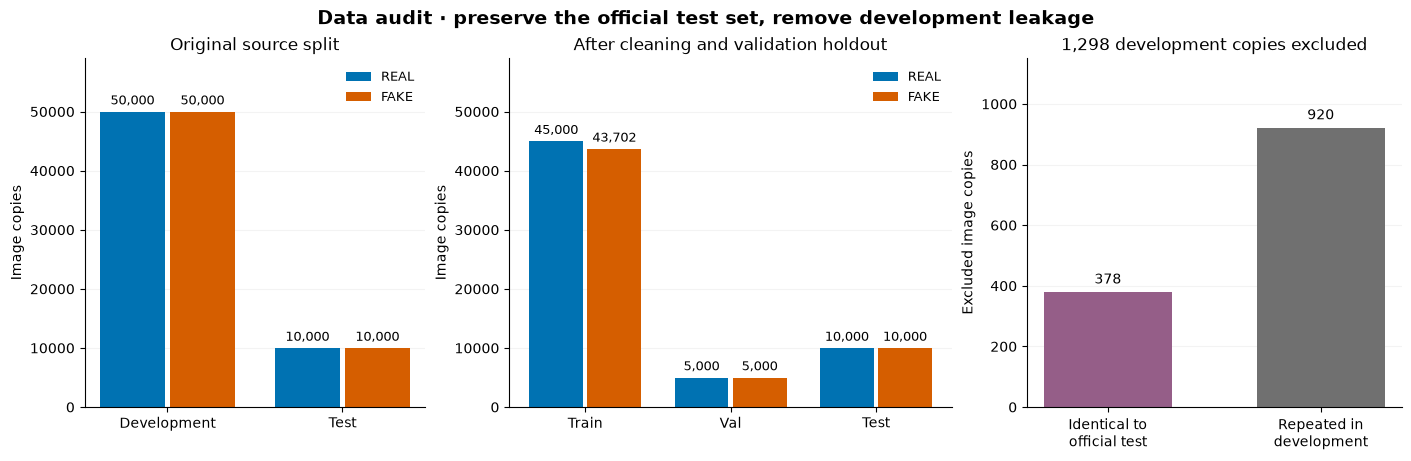

Original development/test overlap: 378 exact pixel hashes.
Final train/validation/test overlap: 0.
Official test contains 38 repeated copies.


In [14]:
if audit:
    if eda_manifest:
        original_counts = {
            source: {
                name: sum(
                    row["source_split"] == source and row["class_name"] == name
                    for row in eda_manifest
                )
                for name, _ in EDA_CLASS_ORDER
            }
            for source in ("train", "test")
        }
        before_hashes = {
            source: {
                r["pixel_sha256"] for r in eda_manifest if r["source_split"] == source
            }
            for source in ("train", "test")
        }
        overlap_before = len(before_hashes["train"] & before_hashes["test"])
        assert overlap_before == audit["exclusion_counts"]["identical_to_official_test"]
    else:
        original_counts = {
            "train": {
                name: sum(
                    audit["split_counts"][s].get(name, 0)
                    for s in ("train", "val", "excluded")
                )
                for name, _ in EDA_CLASS_ORDER
            },
            "test": audit["split_counts"]["test"],
        }
        overlap_before = audit["exclusion_counts"]["identical_to_official_test"]
    fig, axes = plt.subplots(
        1,
        3,
        figsize=(14, 4.5),
        layout="constrained",
        gridspec_kw={"width_ratios": [1, 1.3, 1.1]},
    )
    for ax, names, counts, title in [
        (axes[0], ["train", "test"], original_counts, "Original source split"),
        (
            axes[1],
            ["train", "val", "test"],
            audit["split_counts"],
            "After cleaning and validation holdout",
        ),
    ]:
        positions = np.arange(len(names))
        for offset, (name, _) in zip([-0.2, 0.2], EDA_CLASS_ORDER):
            bars = ax.bar(
                positions + offset,
                [counts[s].get(name, 0) for s in names],
                width=0.37,
                label=name,
                color=EDA_COLORS[name],
            )
            ax.bar_label(
                bars,
                labels=[f"{int(b.get_height()):,}" for b in bars],
                padding=3,
                fontsize=9,
            )
        ax.set(
            xticks=positions,
            xticklabels=[
                "Development" if s == "train" and ax is axes[0] else s.title()
                for s in names
            ],
            ylabel="Image copies",
            title=title,
            ylim=(0, 59000),
        )
        ax.legend(frameon=False, fontsize=9)
        style_eda_axes(ax)
    reasons = ["Identical to\nofficial test", "Repeated in\ndevelopment"]
    values = [
        audit["exclusion_counts"]["identical_to_official_test"],
        audit["exclusion_counts"]["repeated_training_image"],
    ]
    bars = axes[2].bar(reasons, values, color=["#955E88", "#707070"], width=0.6)
    axes[2].bar_label(bars, padding=4)
    axes[2].set(
        title=f"{sum(values):,} development copies excluded",
        ylabel="Excluded image copies",
        ylim=(0, max(values) * 1.25),
    )
    style_eda_axes(axes[2])
    fig.suptitle(
        "Data audit · preserve the official test set, remove development leakage",
        fontsize=14,
        fontweight="bold",
    )
    finish_eda_figure(fig, "01_split_audit")
    print(f"Original development/test overlap: {overlap_before:,} exact pixel hashes.")
    print(
        f"Final train/validation/test overlap: {audit['exact_pixel_overlap_across_splits']}."
    )
    print(
        f"Official test contains {audit['official_test_size'] - audit['unique_test_images']} repeated copies."
    )


To make those duplicate counts more concrete, we'll also look at three pairs of images from the original training pool. Each row will place a retained training image beside a repeated copy that was excluded, with the filenames shown above them. We choose these pairs from groups with exactly matching decoded pixels, then check the pixels again before displaying them. This shows why different filenames do not necessarily mean different examples. These are exact duplicates rather than merely similar-looking pictures, and neither side of the comparison comes from the test set.

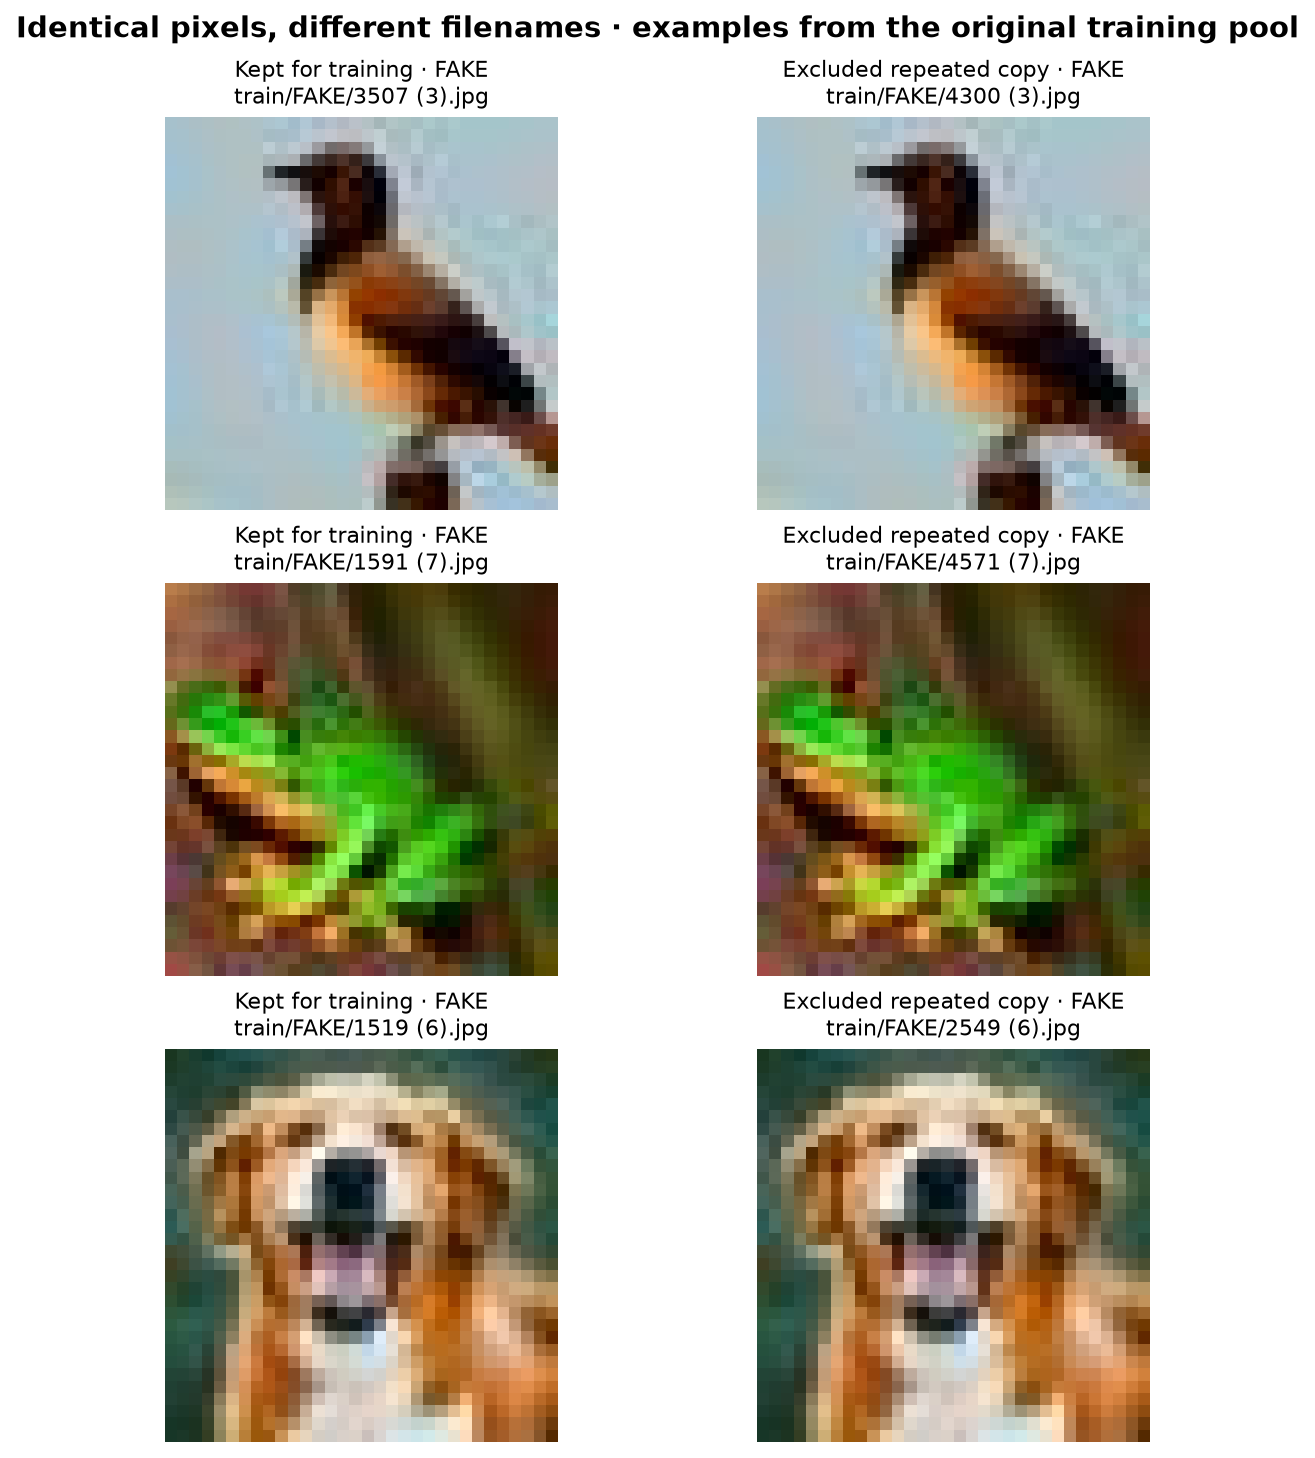

Bundled training-data visualization; no local dataset is required.


In [15]:
# Only display original-development pairs: one kept for TRAIN, one excluded repeat.
# Official test pixels are not opened for this illustration.
if eda_manifest and RAW_DATA.exists():
    duplicate_groups = defaultdict(list)
    for row in eda_manifest:
        if row["source_split"] == "train":
            duplicate_groups[row["pixel_sha256"]].append(row)
    duplicate_pairs = []
    for pixel_hash, group in sorted(duplicate_groups.items()):
        kept = next((r for r in group if r["split"] == "train"), None)
        excluded = next(
            (r for r in group if r["exclusion_reason"] == "repeated_training_image"),
            None,
        )
        if kept and excluded:
            duplicate_pairs.append((pixel_hash, kept, excluded))
    pair_rng = np.random.default_rng(EDA_SEED)
    chosen_pairs = [
        duplicate_pairs[i]
        for i in pair_rng.choice(
            len(duplicate_pairs), size=min(3, len(duplicate_pairs)), replace=False
        )
    ]
    fig, axes = plt.subplots(
        len(chosen_pairs),
        2,
        figsize=(7.4, 3.0 * len(chosen_pairs)),
        squeeze=False,
        layout="constrained",
    )
    for row_index, (pixel_hash, kept, excluded) in enumerate(chosen_pairs):
        pair_pixels = []
        for col, (record, role) in enumerate(
            [(kept, "Kept for training"), (excluded, "Excluded repeated copy")]
        ):
            assert record["path"].startswith("train/")
            with PILImage.open(RAW_DATA / record["path"]) as source_image:
                pixels = np.asarray(source_image.convert("RGB"))
            pair_pixels.append(pixels)
            axes[row_index, col].imshow(pixels, interpolation="nearest")
            axes[row_index, col].set_title(
                f"{role} · {record['class_name']}\n{record['path']}", fontsize=10
            )
            axes[row_index, col].axis("off")
        assert np.array_equal(*pair_pixels)
    fig.suptitle(
        "Identical pixels, different filenames · examples from the original training pool",
        fontsize=13,
        fontweight="bold",
    )
    finish_eda_figure(fig, "02_duplicate_examples")
    del duplicate_groups
else:
    show_saved_eda("02_duplicate_examples")


### 4.2 Balanced random gallery

Before reducing the images to numbers, it helps to get a feel for what the dataset actually looks like. We'll randomly select twelve real and twelve fake images from the cleaned training split and display them in a grid, with real images in the first two rows and fake images in the last two. A fixed random seed means everyone sees the same examples when rerunning the notebook. Look at the backgrounds, edges, textures, and overall composition, and consider which images would be difficult to classify by eye. The images are enlarged without smoothing so we can still see their original 32×32 pixels. This is a small random sample; the object categories are not matched between the two groups.

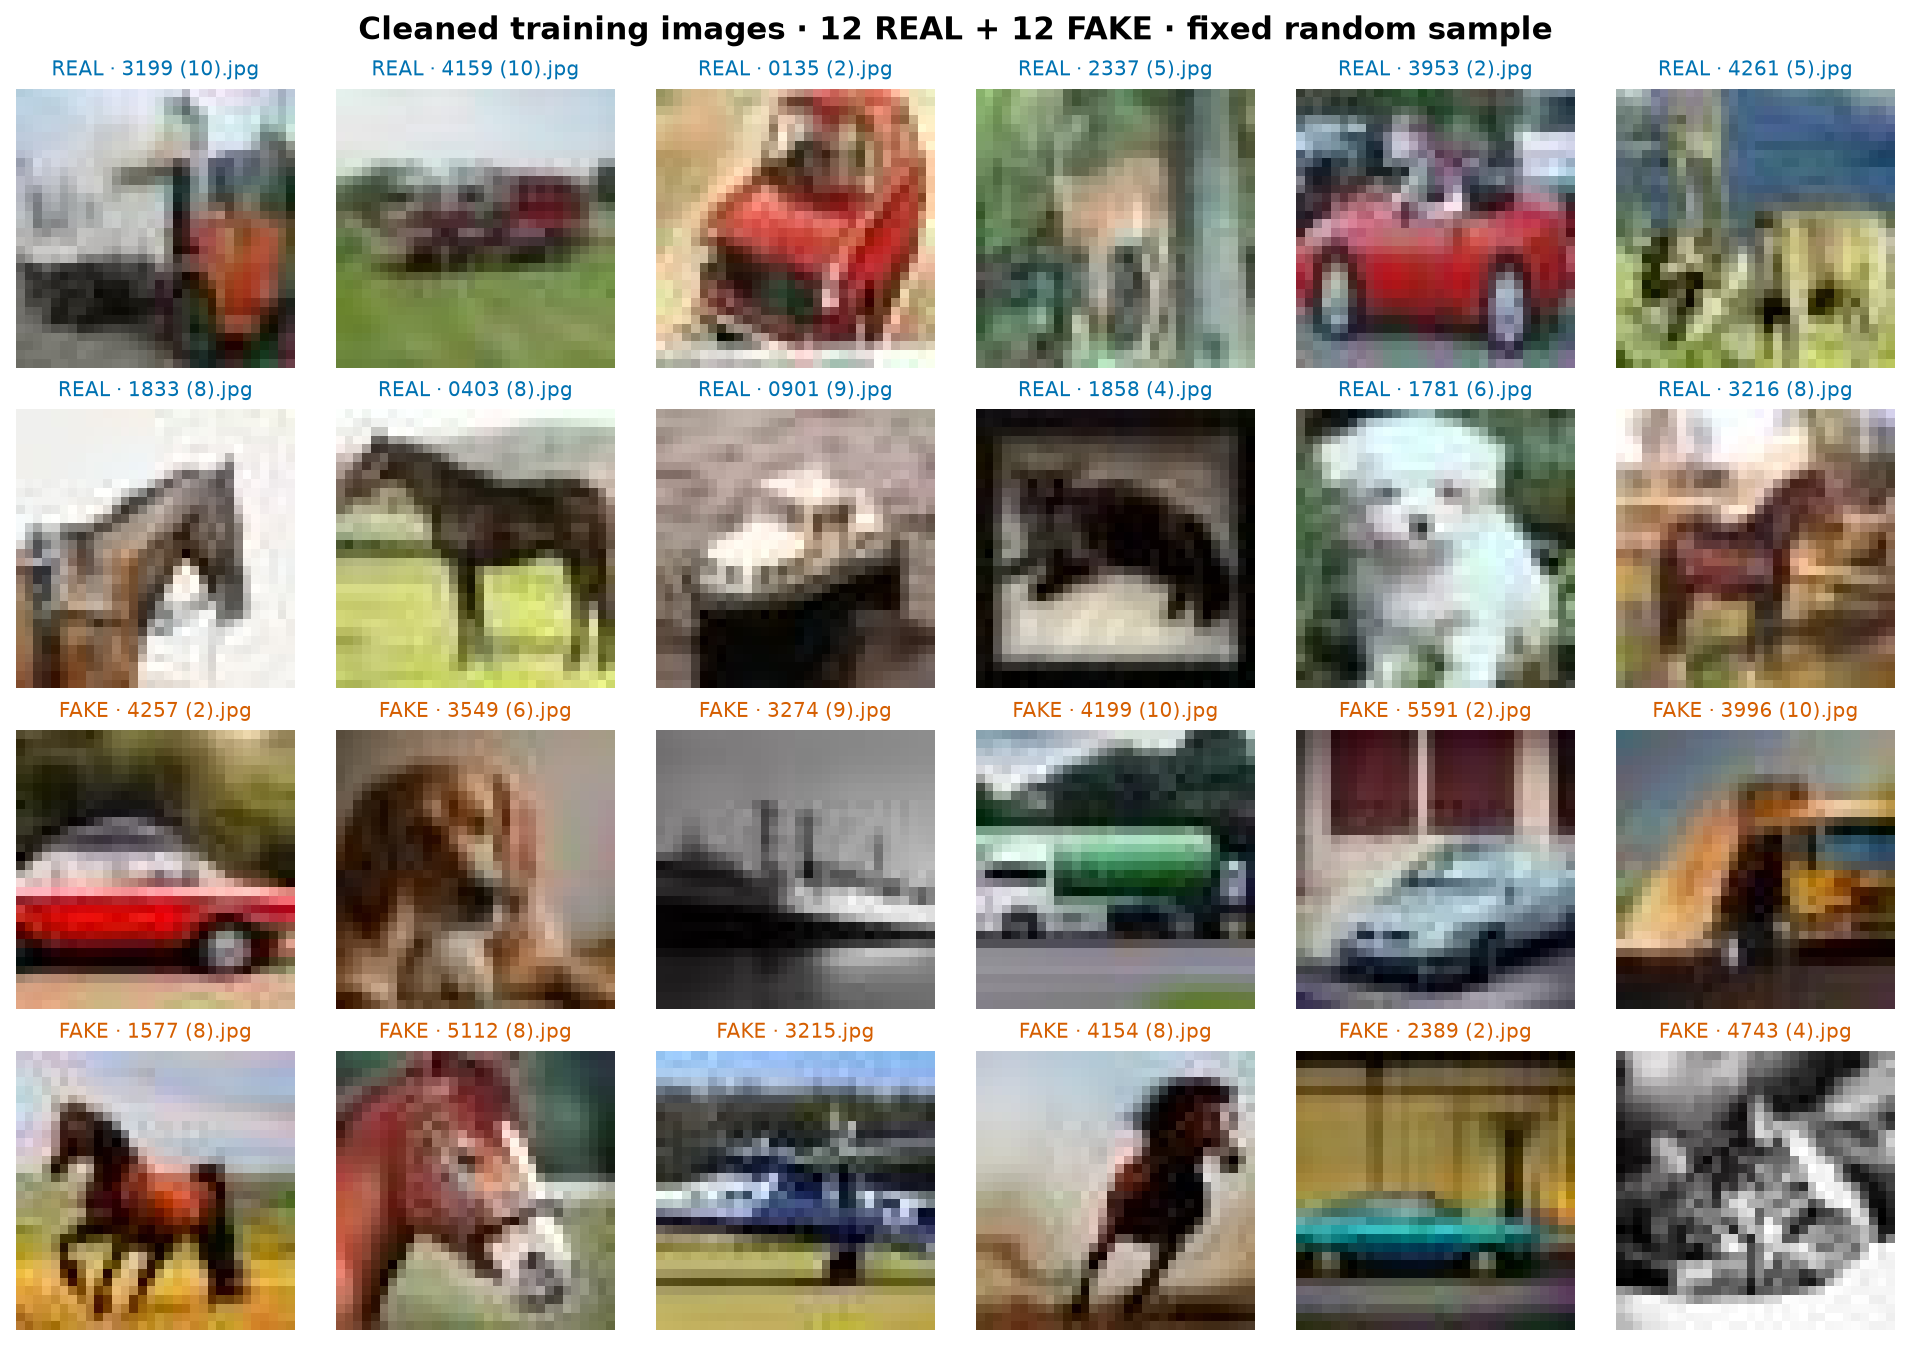

Bundled training-data visualization; no local dataset is required.


In [16]:
if eda_images is not None:
    gallery_rng = np.random.default_rng(EDA_SEED)
    fig, axes = plt.subplots(4, 6, figsize=(12, 8.3), layout="constrained")
    for class_index, (name, label) in enumerate(EDA_CLASS_ORDER):
        chosen = gallery_rng.choice(
            np.flatnonzero(eda_labels == label), size=12, replace=False
        )
        for local_index, image_index in enumerate(chosen):
            ax = axes[class_index * 2 + local_index // 6, local_index % 6]
            ax.imshow(
                eda_images[image_index].transpose(1, 2, 0), interpolation="nearest"
            )
            ax.set_title(
                f"{name} · {Path(eda_rows[image_index]['path']).name}",
                fontsize=9,
                color=EDA_COLORS[name],
            )
            ax.axis("off")
    fig.suptitle(
        "Cleaned training images · 12 REAL + 12 FAKE · fixed random sample",
        fontsize=14,
        fontweight="bold",
    )
    finish_eda_figure(fig, "03_random_gallery")
else:
    show_saved_eda("03_random_gallery")


### 4.3 Image-property distributions

All four properties are calculated on native 32×32 pixels scaled to `[0, 1]`:

- **Brightness:** mean of luma `0.299 R + 0.587 G + 0.114 B`. This is a weighted pixel-value proxy, not calibrated physical luminance.
- **Contrast:** standard deviation of that luma within an image.
- **Saturation:** mean HSV saturation `(max(R,G,B) − min(R,G,B)) / max(R,G,B)`, with zero for black pixels.
- **Sharpness proxy:** variance of the four-neighbour discrete Laplacian, evaluated on the 30×30 interior to avoid padding artifacts. This also responds to noise and compression; it does not measure perceptual sharpness alone.

The sharpness plot uses `log10(variance + 1e-8)` to show its skewed range. Both classes use the same bin edges, and each histogram is normalized separately to density because their training counts differ slightly. No observations are trimmed.

In [17]:
# Measure brightness, colour and texture on training images to understand the data before modeling.
def compute_training_properties(images, labels, batch_size=1024):
    """Four image properties and equal-image-weight, normalized 2-D spectra."""
    properties = np.empty((len(images), 4), dtype=np.float64)
    spectrum_sums = {label: np.zeros((32, 32), dtype=np.float64) for label in (0, 1)}
    spectrum_counts = {label: 0 for label in (0, 1)}
    window = np.outer(np.hanning(32), np.hanning(32)).astype(np.float32)
    weights = np.array([0.299, 0.587, 0.114], dtype=np.float32)
    for start in range(0, len(images), batch_size):
        stop = min(start + batch_size, len(images))
        rgb = images[start:stop].astype(np.float32) / 255
        luma = np.einsum("nchw,c->nhw", rgb, weights)
        channel_max, channel_min = rgb.max(axis=1), rgb.min(axis=1)
        saturation = np.divide(
            channel_max - channel_min,
            channel_max,
            out=np.zeros_like(channel_max),
            where=channel_max > 0,
        )
        laplacian = (
            luma[:, :-2, 1:-1]
            + luma[:, 2:, 1:-1]
            + luma[:, 1:-1, :-2]
            + luma[:, 1:-1, 2:]
            - 4 * luma[:, 1:-1, 1:-1]
        )
        properties[start:stop] = np.column_stack(
            [
                luma.mean(axis=(1, 2)),
                luma.std(axis=(1, 2)),
                saturation.mean(axis=(1, 2)),
                laplacian.var(axis=(1, 2)),
            ]
        )
        # A Hann window limits boundary discontinuities; weighted centering removes DC.
        weighted_mean = (luma * window).sum(axis=(1, 2), keepdims=True) / window.sum()
        transformed = np.fft.fftshift(
            np.fft.fft2((luma - weighted_mean) * window, axes=(-2, -1)), axes=(-2, -1)
        )
        power = np.abs(transformed) ** 2
        power[:, 16, 16] = 0
        total_energy = power.sum(axis=(1, 2), keepdims=True)
        nonconstant = luma.std(axis=(1, 2)) > 1e-7
        valid = nonconstant & (total_energy[:, 0, 0] > 1e-12)
        normalized = np.divide(
            power, total_energy, out=np.zeros_like(power), where=total_energy > 1e-12
        )
        for label in (0, 1):
            mask = (labels[start:stop] == label) & valid
            spectrum_sums[label] += normalized[mask].sum(axis=0, dtype=np.float64)
            spectrum_counts[label] += int(mask.sum())
    spectra = {
        label: spectrum_sums[label] / max(spectrum_counts[label], 1) for label in (0, 1)
    }
    return properties, spectra, spectrum_counts


# Sanity checks have known properties: constant gray, solid red, and a checkerboard.
check_images = np.full((3, 3, 32, 32), 102, dtype=np.uint8)
check_images[1] = 0
check_images[1, 0] = 255
checker = ((np.indices((32, 32)).sum(axis=0) % 2) * 255).astype(np.uint8)
check_images[2] = np.repeat(checker[None, :, :], 3, axis=0)
check_properties, _, check_spectra_counts = compute_training_properties(
    check_images, np.array([0, 0, 1])
)
assert np.allclose(check_properties[0], [0.4, 0, 0, 0], atol=1e-6)
assert np.isclose(check_properties[1, 0], 0.299, atol=1e-6) and np.isclose(
    check_properties[1, 2], 1
)
assert check_properties[2, 3] > check_properties[0, 3]
assert check_spectra_counts == {0: 0, 1: 1}

eda_features, eda_spectra, eda_spectrum_counts = None, None, None
eda_property_stats = {}
if eda_images is not None:
    eda_features, eda_spectra, eda_spectrum_counts = compute_training_properties(
        eda_images, eda_labels
    )
    assert np.isfinite(eda_features).all() and (eda_features >= 0).all()
    assert (eda_features[:, [0, 2]] <= 1 + 1e-6).all()
    assert all(
        np.isclose(spectrum.sum(), 1, atol=1e-5) for spectrum in eda_spectra.values()
    )
    for name, label in EDA_CLASS_ORDER:
        class_features = eda_features[eda_labels == label]
        eda_property_stats[name] = {
            prop: {
                "mean": float(np.mean(class_features[:, col])),
                "median": float(np.median(class_features[:, col])),
                "p10": float(np.quantile(class_features[:, col], 0.1)),
                "p90": float(np.quantile(class_features[:, col], 0.9)),
            }
            for col, prop in enumerate(EDA_PROPERTIES)
        }
    print(
        f"Computed image properties and spectra for all {len(eda_features):,} cleaned training images."
    )
    print("Numerical checks passed; each class-average normalized spectrum sums to 1.")


The next four plots will help us see whether the impressions from the gallery hold across the whole training set. For every image, we'll calculate brightness, contrast, saturation, and a sharpness score, then group the values into bins and overlay the real and fake distributions. Blue represents real images and orange represents fake images. Both groups use the same bins, and each distribution is scaled to have a total area of one so their slightly different image counts do not distort the comparison. The dashed lines mark the medians. Look for shifts in the typical values as well as the amount of overlap; a difference in the medians does not mean that a property can reliably identify every image. Sharpness is shown on a logarithmic scale to make its wide range easier to read.

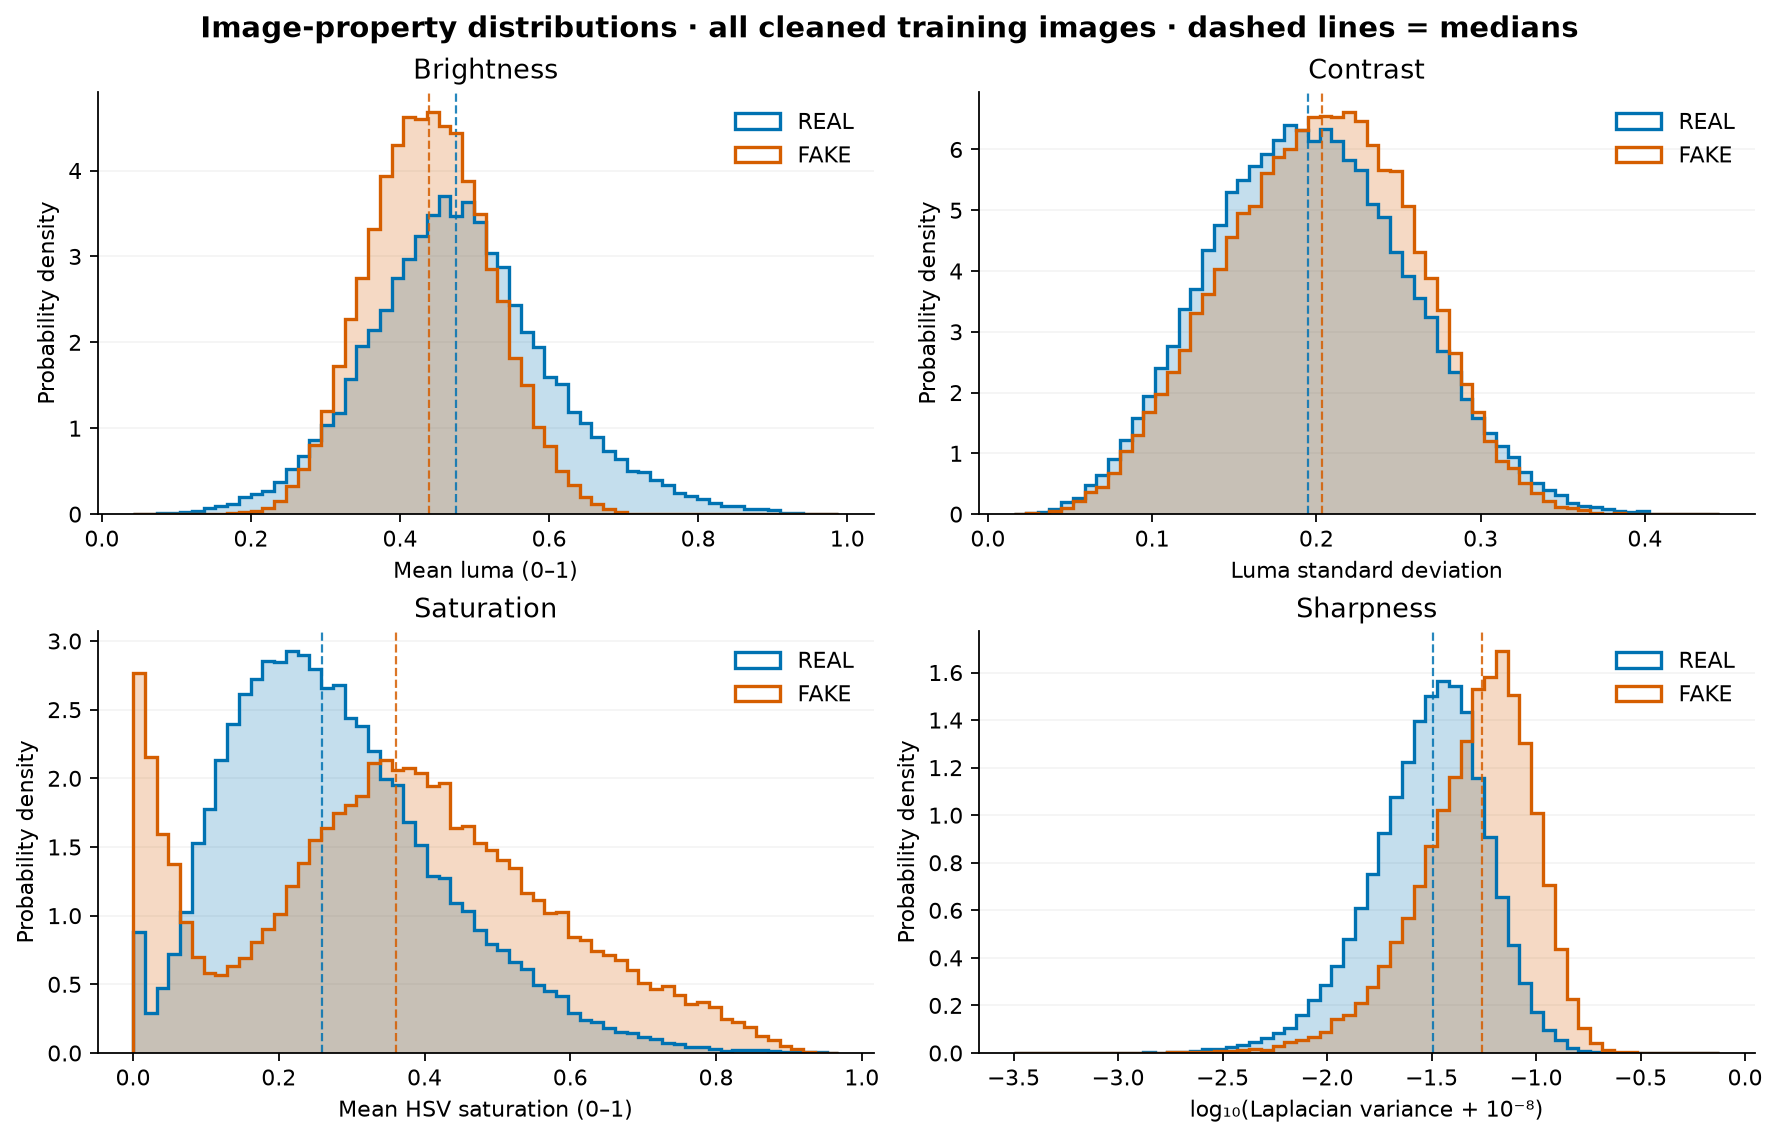

Bundled training-data visualization; no local dataset is required.


In [18]:
if eda_features is not None:
    fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout="constrained")
    for col, (prop, ax) in enumerate(zip(EDA_PROPERTIES, axes.flat)):
        values = (
            np.log10(eda_features[:, col] + 1e-8)
            if prop == "sharpness"
            else eda_features[:, col]
        )
        bins = np.linspace(values.min(), values.max(), 61)
        for name, label in EDA_CLASS_ORDER:
            group = values[eda_labels == label]
            ax.hist(
                group,
                bins=bins,
                density=True,
                histtype="stepfilled",
                alpha=0.23,
                color=EDA_COLORS[name],
            )
            ax.hist(
                group,
                bins=bins,
                density=True,
                histtype="step",
                lw=1.5,
                color=EDA_COLORS[name],
                label=name,
            )
            ax.axvline(
                np.median(group), color=EDA_COLORS[name], ls="--", lw=1, alpha=0.85
            )
        key = "log_sharpness" if prop == "sharpness" else prop
        ax.set(
            title=prop.title(),
            xlabel=EDA_PROPERTY_LABELS[key],
            ylabel="Probability density",
        )
        ax.legend(frameon=False)
        style_eda_axes(ax)
    fig.suptitle(
        "Image-property distributions · all cleaned training images · dashed lines = medians",
        fontsize=13,
        fontweight="bold",
    )
    finish_eda_figure(fig, "04_property_distributions")
    show_table(
        [
            "Property (original units)",
            "Class",
            "Mean",
            "Median",
            "10th–90th percentile",
        ],
        [
            [
                prop,
                name,
                f"{eda_property_stats[name][prop]['mean']:.4g}",
                f"{eda_property_stats[name][prop]['median']:.4g}",
                f"{eda_property_stats[name][prop]['p10']:.4g}–{eda_property_stats[name][prop]['p90']:.4g}",
            ]
            for prop in EDA_PROPERTIES
            for name, _ in EDA_CLASS_ORDER
        ],
    )
else:
    show_saved_eda("04_property_distributions")


### 4.4 Connect the sharpness proxy to actual images

A sharpness score is easier to understand when we can see the images behind it. We'll rank the training images by Laplacian variance and display the four lowest-scoring and four highest-scoring examples separately for real and fake images. The low-score rows will let us inspect images with little variation in local edges, while the high-score rows will show what produces a strong response. As we compare them, we'll look for blur, detailed textures, repeated patterns, or noise that might explain the scores. These examples were deliberately chosen from the extremes, so they should not be treated as typical real or fake images. A high value also does not automatically mean better image quality.

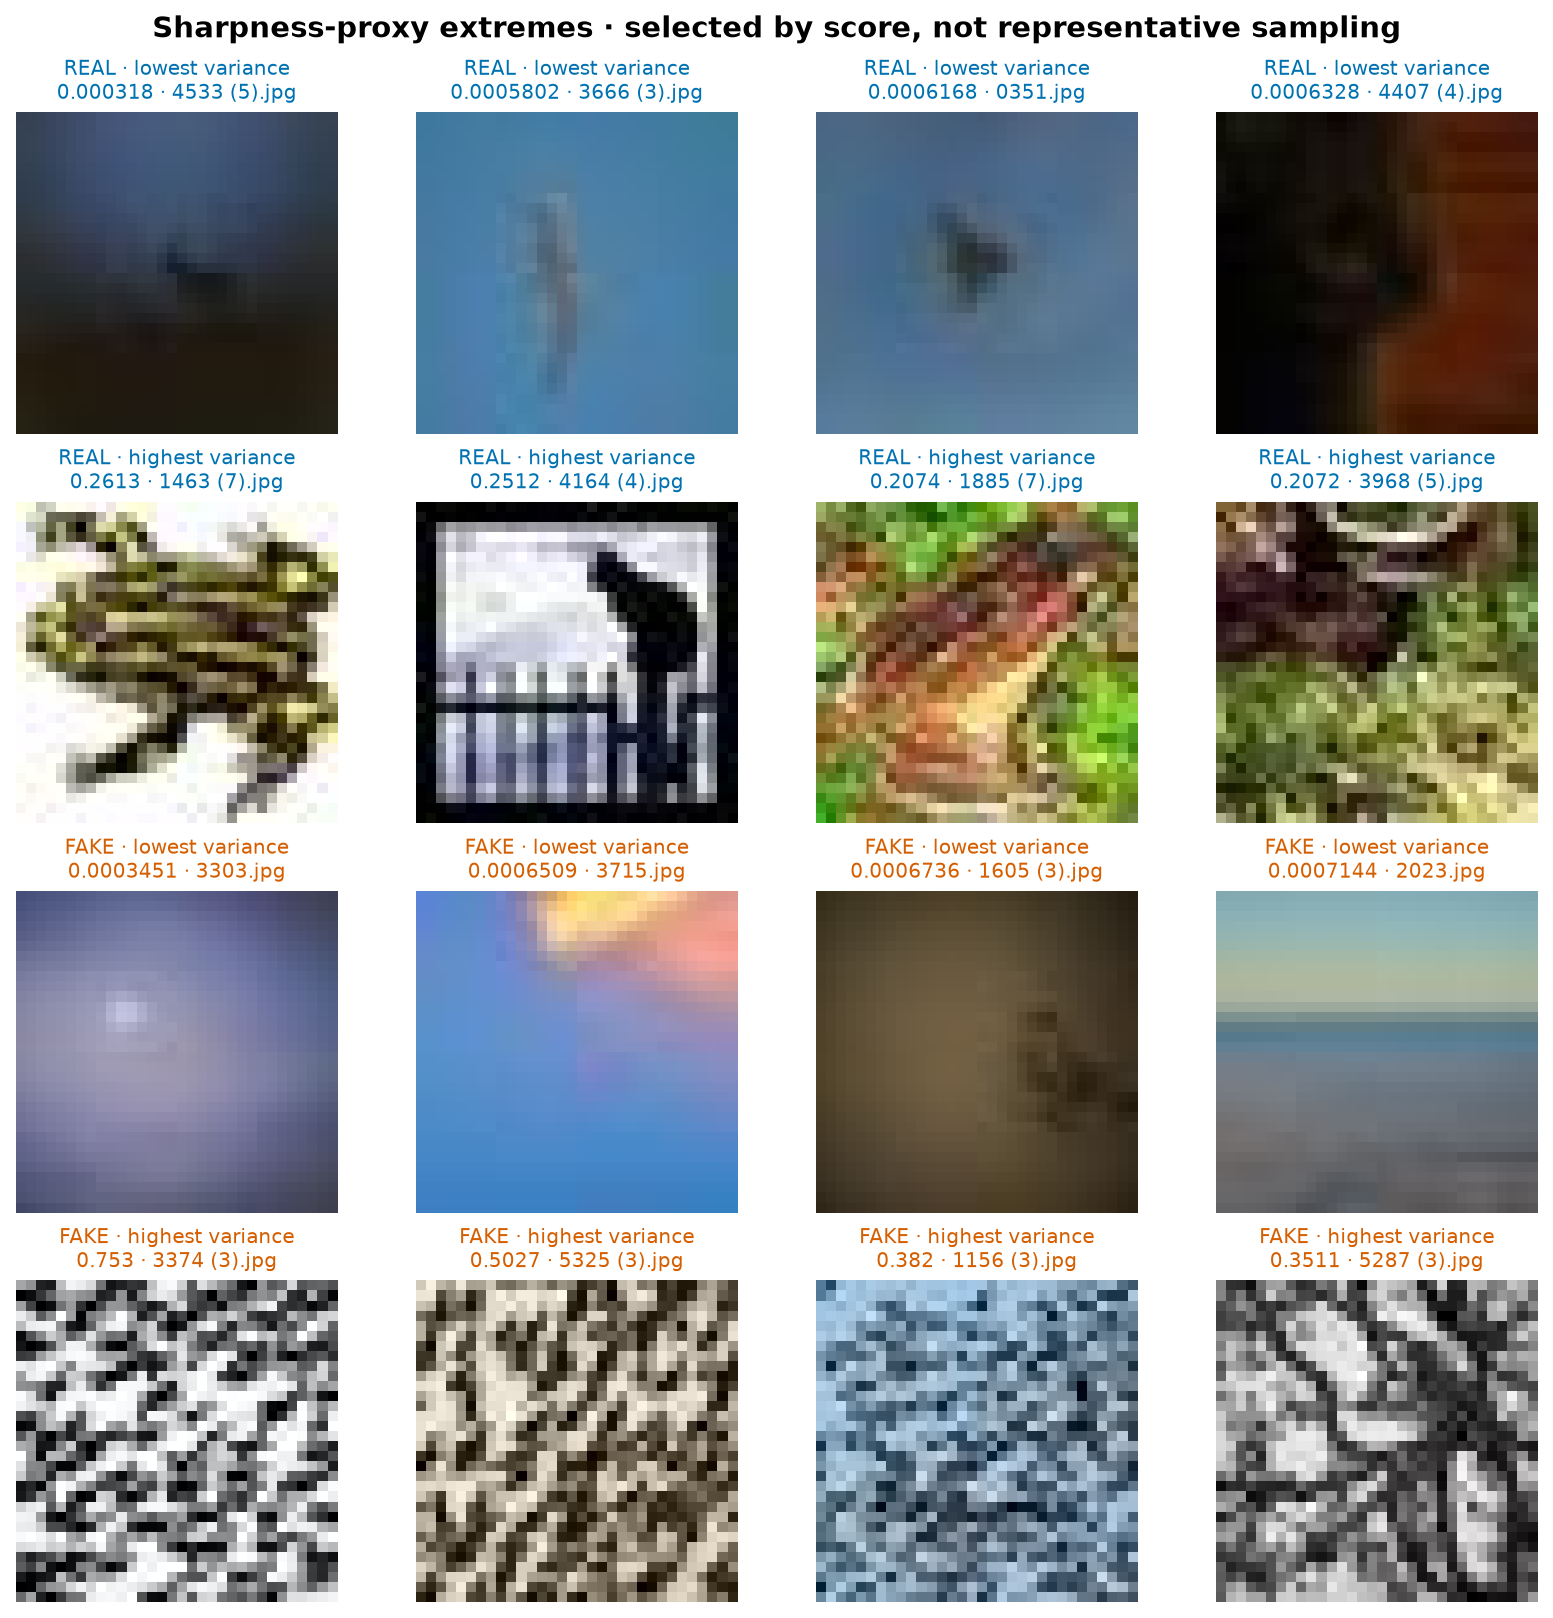

Bundled training-data visualization; no local dataset is required.


In [19]:
if eda_features is not None:
    fig, axes = plt.subplots(4, 4, figsize=(10, 10), layout="constrained")
    for class_index, (name, label) in enumerate(EDA_CLASS_ORDER):
        members = np.flatnonzero(eda_labels == label)
        ordered = members[np.argsort(eda_features[members, 3], kind="stable")]
        for which, selected in enumerate([ordered[:4], ordered[-4:][::-1]]):
            for col, index in enumerate(selected):
                ax = axes[2 * class_index + which, col]
                ax.imshow(eda_images[index].transpose(1, 2, 0), interpolation="nearest")
                ax.set_title(
                    f"{name} · {'lowest' if which == 0 else 'highest'} variance\n{eda_features[index, 3]:.4g} · {Path(eda_rows[index]['path']).name}",
                    fontsize=9,
                    color=EDA_COLORS[name],
                )
                ax.axis("off")
    fig.suptitle(
        "Sharpness-proxy extremes · selected by score, not representative sampling",
        fontsize=13,
        fontweight="bold",
    )
    finish_eda_figure(fig, "05_sharpness_extremes")
else:
    show_saved_eda("05_sharpness_extremes")


### 4.5 Link image properties to thumbnails

The histograms show one property at a time, but two properties may tell a different story when we look at them together. Here we'll plot the sharpness score on the horizontal axis, using a logarithmic scale, and contrast on the vertical axis. Each point represents one training image, with blue for real images and orange for fake images. We'll use a fixed random sample of 800 images from each group to keep the plot readable and give both classes equal representation. Look for any relationship between contrast and sharpness, for points that sit far from the others, and for regions where the two colours overlap. The colours show the dataset labels; no model predictions are involved in this plot.

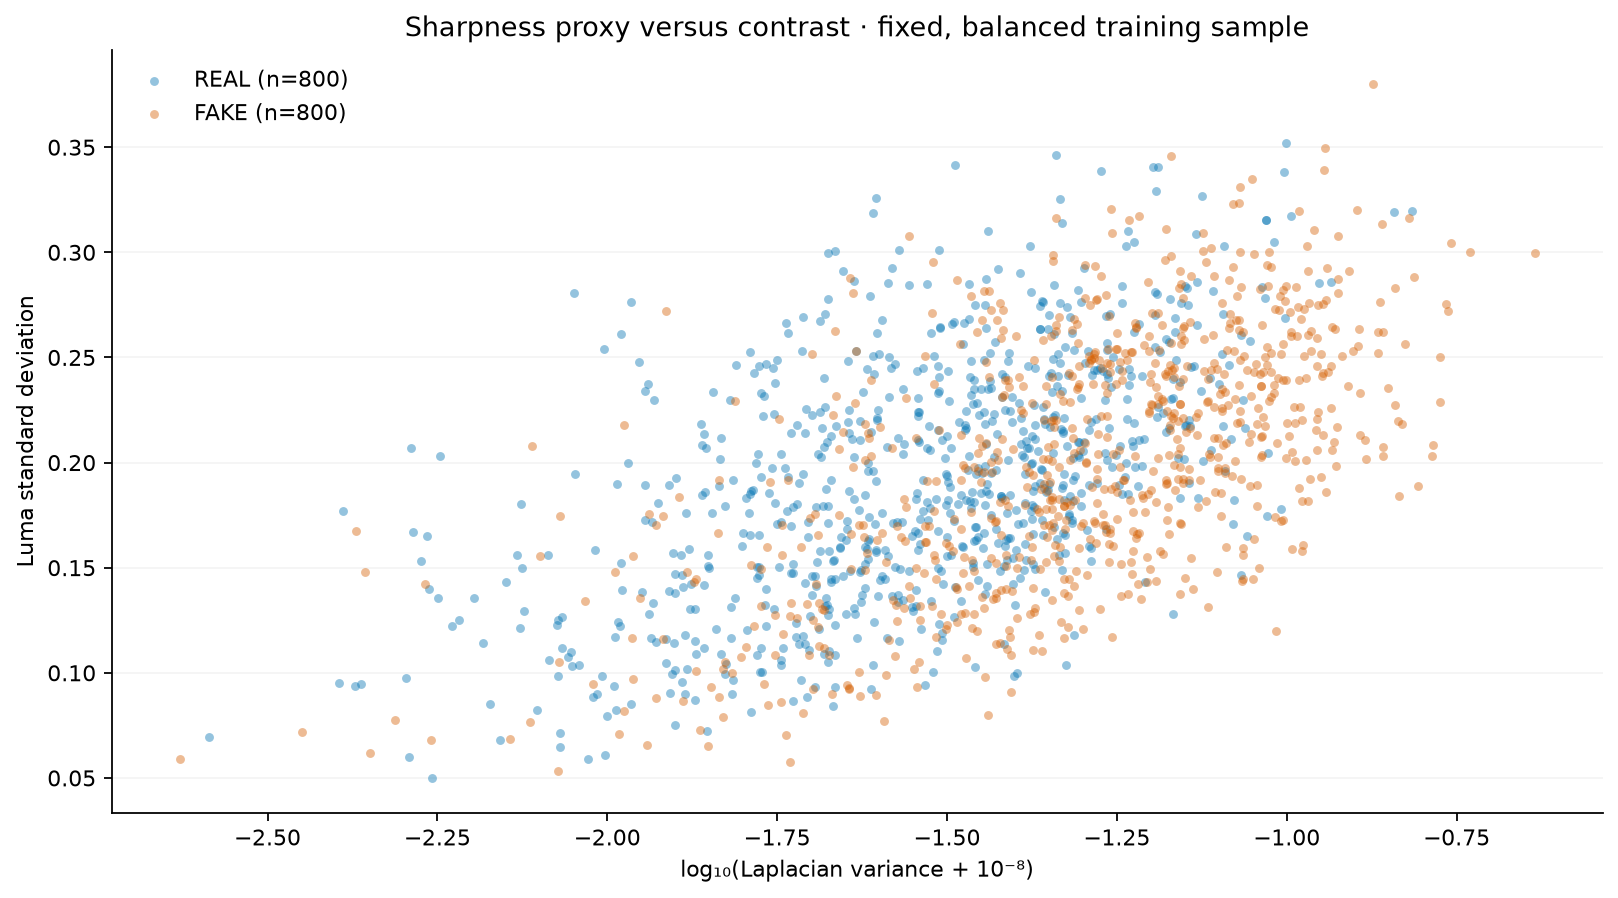

Bundled training-data visualization; no local dataset is required.


In [20]:
eda_scatter_indices = None
if eda_features is not None:
    scatter_rng = np.random.default_rng(EDA_SEED)
    eda_scatter_indices = np.concatenate(
        [
            scatter_rng.choice(
                np.flatnonzero(eda_labels == label),
                size=min(800, int((eda_labels == label).sum())),
                replace=False,
            )
            for _, label in EDA_CLASS_ORDER
        ]
    )
    eda_plot_values = {
        prop: eda_features[:, col] for col, prop in enumerate(EDA_PROPERTIES)
    }
    eda_plot_values["log_sharpness"] = np.log10(eda_features[:, 3] + 1e-8)
    fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
    for name, label in EDA_CLASS_ORDER:
        ids = eda_scatter_indices[eda_labels[eda_scatter_indices] == label]
        ax.scatter(
            eda_plot_values["log_sharpness"][ids],
            eda_plot_values["contrast"][ids],
            c=EDA_COLORS[name],
            s=16,
            alpha=0.42,
            linewidths=0,
            label=f"{name} (n={len(ids)})",
        )
    ax.set(
        xlabel=EDA_PROPERTY_LABELS["log_sharpness"],
        ylabel=EDA_PROPERTY_LABELS["contrast"],
        title="Sharpness proxy versus contrast · fixed, balanced training sample",
    )
    style_eda_axes(ax)
    ax.legend(frameon=False)
    finish_eda_figure(fig, "06_scatter_overview")
else:
    show_saved_eda("06_scatter_overview")


We can now connect those points back to the actual pictures. The interactive version uses the same sampled images, but lets us change the properties on either axis, zoom into a region, and hide or show a class through the legend. Clicking a point will display its image, filename, and measurements below the chart. For example, we can select a point with unusually high sharpness and inspect whether it contains fine texture or a noisy pattern. This gives us a way to investigate patterns rather than guess what an isolated point represents. Run the cell with a live notebook kernel and the prepared training data to enable the interactions; the static plot above remains available on GitHub.

In [21]:
if eda_scatter_indices is not None:
    try:
        import plotly.graph_objects as go
        import ipywidgets as widgets
        import anywidget  # FigureWidget's Jupyter widget backend
    except ImportError:
        print(
            "Install the pinned requirements and restart the kernel for the clickable explorer. The static scatterplot remains available above."
        )
    else:
        explorer_ids = {
            name: eda_scatter_indices[eda_labels[eda_scatter_indices] == label]
            for name, label in EDA_CLASS_ORDER
        }
        axis_options = [
            (EDA_PROPERTY_LABELS[key], key)
            for key in ("brightness", "contrast", "saturation", "log_sharpness")
        ]
        explorer_x = widgets.Dropdown(
            options=axis_options,
            value="log_sharpness",
            description="X axis:",
            layout=widgets.Layout(width="47%"),
        )
        explorer_y = widgets.Dropdown(
            options=axis_options,
            value="contrast",
            description="Y axis:",
            layout=widgets.Layout(width="47%"),
        )
        explorer_figure = go.FigureWidget()
        for name, _ in EDA_CLASS_ORDER:
            ids = explorer_ids[name]
            explorer_figure.add_scatter(
                x=eda_plot_values[explorer_x.value][ids],
                y=eda_plot_values[explorer_y.value][ids],
                name=name,
                mode="markers",
                customdata=[eda_rows[int(i)]["path"] for i in ids],
                marker=dict(size=6, color=EDA_COLORS[name], opacity=0.55),
                hovertemplate="%{customdata}<br>x=%{x:.4f}<br>y=%{y:.4f}<extra>%{fullData.name}</extra>",
            )
        explorer_figure.add_scatter(
            x=[],
            y=[],
            name="Selected",
            mode="markers",
            hoverinfo="skip",
            showlegend=False,
            marker=dict(
                size=16, color="#242424", symbol="circle-open", line=dict(width=2)
            ),
        )
        explorer_figure.update_layout(
            template="plotly_white",
            height=440,
            margin=dict(l=65, r=20, t=55, b=60),
            title="Click a training-image point to inspect it below",
            clickmode="event",
            xaxis_title=EDA_PROPERTY_LABELS[explorer_x.value],
            yaxis_title=EDA_PROPERTY_LABELS[explorer_y.value],
            legend=dict(orientation="h", y=1.05, x=0.75),
        )
        explorer_image = widgets.Image(format="png", width=160, height=160)
        explorer_details = widgets.HTML(layout=widgets.Layout(margin="0 0 0 18px"))
        explorer_selection = {"index": int(explorer_ids["REAL"][0])}

        def select_training_image(index):
            index = int(index)
            assert eda_rows[index]["split"] == "train"
            explorer_selection["index"] = index
            buffer = BytesIO()
            PILImage.fromarray(eda_images[index].transpose(1, 2, 0)).resize(
                (160, 160), resample=PILImage.Resampling.NEAREST
            ).save(buffer, format="PNG")
            explorer_image.value = buffer.getvalue()
            name = "REAL" if eda_labels[index] == 1 else "FAKE"
            stats_html = "<br>".join(
                f"{html.escape(EDA_PROPERTY_LABELS[prop])}: <b>{eda_features[index, col]:.4f}</b>"
                for col, prop in enumerate(EDA_PROPERTIES)
            )
            explorer_details.value = (
                f"<b style='color:{EDA_COLORS[name]}'>{name}</b> · training image<br>"
                f"<code>{html.escape(eda_rows[index]['path'])}</code><br><br>{stats_html}"
                "<br><small>32×32 source, enlarged with nearest-neighbor sampling.</small>"
            )
            with explorer_figure.batch_update():
                explorer_figure.data[2].x = [eda_plot_values[explorer_x.value][index]]
                explorer_figure.data[2].y = [eda_plot_values[explorer_y.value][index]]

        def on_training_image_click(trace, points, selector):
            if points.point_inds:
                select_training_image(explorer_ids[trace.name][points.point_inds[0]])

        def update_explorer_axes(change):
            with explorer_figure.batch_update():
                for trace in explorer_figure.data[:2]:
                    ids = explorer_ids[trace.name]
                    trace.x = eda_plot_values[explorer_x.value][ids]
                    trace.y = eda_plot_values[explorer_y.value][ids]
                explorer_figure.layout.xaxis.title = EDA_PROPERTY_LABELS[
                    explorer_x.value
                ]
                explorer_figure.layout.yaxis.title = EDA_PROPERTY_LABELS[
                    explorer_y.value
                ]
                index = explorer_selection["index"]
                explorer_figure.data[2].x = [eda_plot_values[explorer_x.value][index]]
                explorer_figure.data[2].y = [eda_plot_values[explorer_y.value][index]]

        for trace in explorer_figure.data[:2]:
            trace.on_click(on_training_image_click)
        explorer_x.observe(update_explorer_axes, names="value")
        explorer_y.observe(update_explorer_axes, names="value")
        select_training_image(explorer_selection["index"])
        display(
            widgets.VBox(
                [
                    widgets.HBox([explorer_x, explorer_y]),
                    explorer_figure,
                    widgets.HBox([explorer_image, explorer_details]),
                ]
            )
        )
        print(
            "Requires a running notebook kernel for thumbnail clicks and axis changes. The static plot above works in GitHub previews."
        )
else:
    print(
        "Interactive thumbnails need the prepared training data. Saved static plots above can be reviewed without it."
    )


Interactive thumbnails need the prepared training data. Saved static plots above can be reviewed without it.


### 4.6 Spatial-frequency patterns

Next we'll compare how broad shapes and fine detail are distributed across the two groups. We'll convert each training image to a single brightness channel and use a Fourier transform to describe its spatial-frequency content. Slowly changing areas contribute to lower frequencies, while finer textures and rapid changes between neighbouring pixels contribute to higher frequencies. Averaging the results separately for real and fake images will give us the two heatmaps below. Their centres represent low frequencies, and positions farther from the centre represent finer detail. Both heatmaps use the same colour scale, so their intensities can be compared directly.

To make the comparison fair, we subtract each image's Hann-weighted mean, apply a Hann window to soften boundary effects, and remove the zero-frequency bin, which represents the average brightness. We then scale each usable image's remaining power to sum to one before averaging, so high-contrast images do not dominate the result. Constant or effectively zero-energy images are excluded and counted below. The colours use a logarithmic scale so weaker frequency components remain visible.

The line plot on the right will make the comparison easier to follow by averaging bins at similar distances from the centre. Moving right corresponds to finer detail; a higher curve means more normalized power per frequency bin at that distance. This is not the total energy in each ring. Frequencies are measured in cycles per pixel, and diagonal distances can exceed 0.5. We'll look for ranges where the curves differ, while keeping in mind that image content, compression, and other processing can also produce these differences. The plots alone cannot tell us whether the CNN uses them.

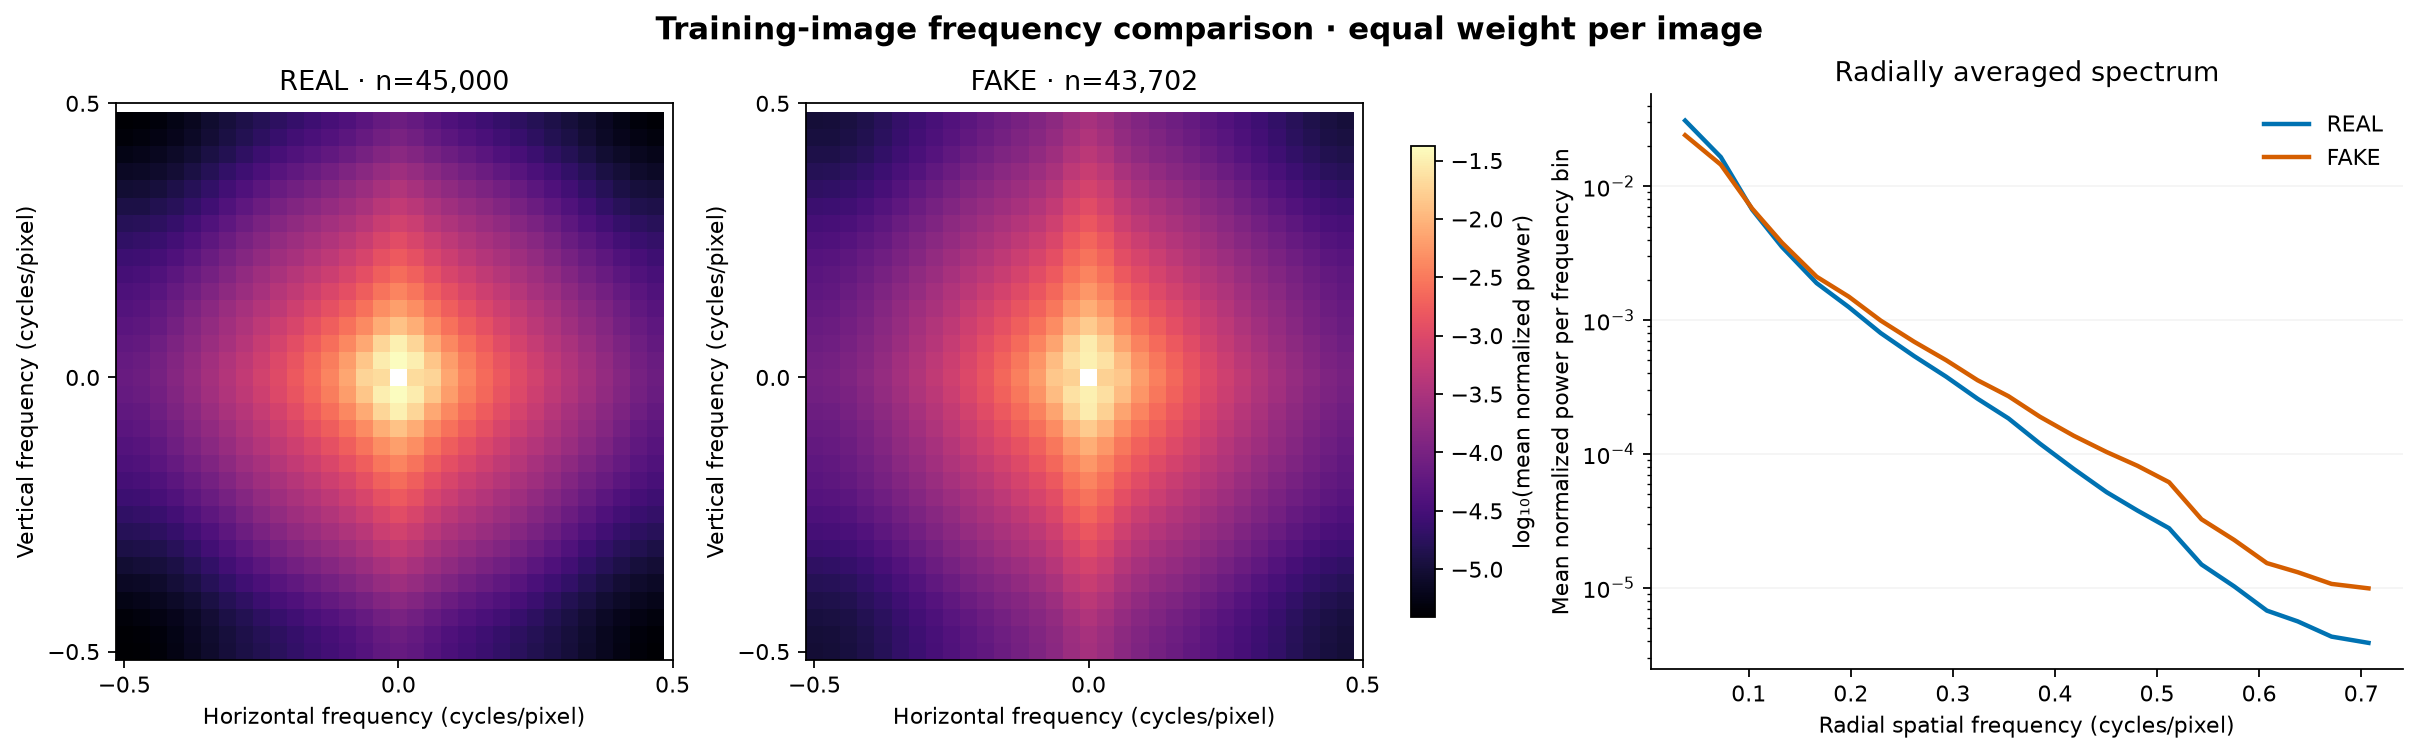

Bundled training-data visualization; no local dataset is required.


In [22]:
# Average spatial-frequency profiles over training images to compare fine detail between the classes.
if eda_spectra is not None:
    frequencies = np.fft.fftshift(np.fft.fftfreq(32))
    freq_x, freq_y = np.meshgrid(frequencies, frequencies)
    eda_frequency_radius = np.hypot(freq_x, freq_y)
    rings = np.floor(eda_frequency_radius * 32).astype(int)
    ring_counts = np.bincount(rings.ravel())
    ring_radius = (
        np.bincount(rings.ravel(), weights=eda_frequency_radius.ravel()) / ring_counts
    )
    nonzero_rings = (ring_counts > 0) & (np.arange(len(ring_counts)) > 0)
    log_spectra = {
        label: np.ma.masked_where(eda_frequency_radius == 0, np.log10(spectrum + 1e-12))
        for label, spectrum in eda_spectra.items()
    }
    color_min = min(float(s.min()) for s in log_spectra.values())
    color_max = max(float(s.max()) for s in log_spectra.values())
    fig, axes = plt.subplots(
        1,
        3,
        figsize=(15, 4.6),
        layout="constrained",
        gridspec_kw={"width_ratios": [1, 1, 1.35]},
    )
    for ax, (name, label) in zip(axes[:2], EDA_CLASS_ORDER):
        heat = ax.imshow(
            log_spectra[label],
            origin="lower",
            cmap="magma",
            vmin=color_min,
            vmax=color_max,
            extent=(-0.5 - 1 / 64, 0.5 - 1 / 64, -0.5 - 1 / 64, 0.5 - 1 / 64),
            interpolation="nearest",
        )
        ax.set(
            title=f"{name} · n={eda_spectrum_counts[label]:,}",
            xlabel="Horizontal frequency (cycles/pixel)",
            ylabel="Vertical frequency (cycles/pixel)",
            xticks=[-0.5, 0, 0.5],
            yticks=[-0.5, 0, 0.5],
        )
    colorbar = fig.colorbar(heat, ax=list(axes[:2]), shrink=0.82, pad=0.025)
    colorbar.set_label("log₁₀(mean normalized power)")
    for name, label in EDA_CLASS_ORDER:
        profile = (
            np.bincount(rings.ravel(), weights=eda_spectra[label].ravel()) / ring_counts
        )
        axes[2].plot(
            ring_radius[nonzero_rings],
            profile[nonzero_rings],
            color=EDA_COLORS[name],
            label=name,
            linewidth=2,
        )
    axes[2].set(
        xlabel="Radial spatial frequency (cycles/pixel)",
        ylabel="Mean normalized power per frequency bin",
        title="Radially averaged spectrum",
        yscale="log",
    )
    axes[2].legend(frameon=False)
    style_eda_axes(axes[2])
    fig.suptitle(
        "Training-image frequency comparison · equal weight per image",
        fontweight="bold",
        fontsize=14,
    )
    finish_eda_figure(fig, "07_frequency_comparison")
    for name, label in EDA_CLASS_ORDER:
        excluded = int((eda_labels == label).sum()) - eda_spectrum_counts[label]
        print(
            f"{name}: {eda_spectrum_counts[label]:,} usable spectra; {excluded} constant/zero-energy images excluded."
        )
else:
    show_saved_eda("07_frequency_comparison")


### 4.7 Record the observations

The completed figures and numerical summary are bundled inside this notebook. Set `SAVE_FIGURES = True` to also save recalculated figures locally in `results/eda_baseline_seed1/`. Galleries and the scatterplot use seed 2026; property distributions and frequency averages use the entire cleaned training split. Thumbnail enlargement is for display only and is not training augmentation.

Read the property medians together with the distributions and example images. Class distributions can overlap substantially even when their medians differ. These plots generate hypotheses for later validation-set experiments, such as blur or color perturbations; they do not establish which cues the CNN learned. Keep the completed baseline and test results fixed when designing those follow-up experiments.

In [23]:
eda_summary = None
if eda_features is not None:
    eda_summary = {
        "source_split": "train",
        "split_seed": SPLIT_SEED,
        "sampling_seed": EDA_SEED,
        "manifest_sha256": file_sha256(DATA_DIR / "manifest.csv"),
        "image_shape_chw": list(eda_images.shape[1:]),
        "image_count": len(eda_images),
        "class_counts": {
            name: int((eda_labels == label).sum()) for name, label in EDA_CLASS_ORDER
        },
        "property_definitions": {
            "brightness": "Mean of 0.299R + 0.587G + 0.114B, RGB scaled to [0,1]",
            "contrast": "Population standard deviation of luma",
            "saturation": "Mean HSV saturation: (max(RGB)-min(RGB))/max(RGB), zero for black pixels",
            "sharpness": "Population variance of the four-neighbor luma Laplacian over the 30x30 interior",
        },
        "property_statistics": eda_property_stats,
        "frequency_method": "Hann-weighted centering, 2-D Hann window, FFT power, DC removed, per-image unit-sum normalization, class mean",
        "spectrum_counts": {
            name: eda_spectrum_counts[label] for name, label in EDA_CLASS_ORDER
        },
        "excluded_spectrum_counts": {
            name: int((eda_labels == label).sum()) - eda_spectrum_counts[label]
            for name, label in EDA_CLASS_ORDER
        },
        "mean_energy_fraction_radius_ge_0_25": {
            name: float(eda_spectra[label][eda_frequency_radius >= 0.25].sum())
            for name, label in EDA_CLASS_ORDER
        },
        "gallery_images_per_class": 12,
        "scatter_images_per_class": 800,
        "figures": [p.name for p in sorted(EDA_DIR.glob("*.png"))],
        "scope": "Training pixels only; split audit also reads metadata for all splits. Added after the baseline run; no model or test-result changes.",
        "limitations": [
            "Descriptive class associations do not establish model reliance or causation.",
            "Sharpness is a resolution-dependent proxy, not a direct measure of image quality.",
            "Near-duplicates and semantic-category balance were not audited.",
        ],
    }
    if SAVE_FIGURES:
        write_json(EDA_DIR / "summary.json", eda_summary)
        print("Saved seven figures and summary:", EDA_DIR.relative_to(ROOT))
    else:
        print(
            "Figures and observations are displayed inline; SAVE_FIGURES enables optional local copies."
        )
else:
    eda_summary = (
        read_json(EDA_DIR / "summary.json")
        if (EDA_DIR / "summary.json").exists()
        else None
    )
    if eda_summary is None and SPLIT_SEED == 1:
        eda_summary = json.loads(
            embedded_bytes("results/eda_baseline_seed1/summary.json")
        )

if eda_summary:
    property_stats = eda_summary["property_statistics"]
    real_median = property_stats["REAL"]["sharpness"]["median"]
    fake_median = property_stats["FAKE"]["sharpness"]["median"]
    display(
        Markdown(
            f"**Observed in {eda_summary['image_count']:,} training images:** median Laplacian variance is "
            f"**{real_median:.4f} for REAL** and **{fake_median:.4f} for FAKE**. "
            "Use the distributions and extreme-image gallery above to interpret that difference; "
            "this is an image statistic, not a model attribution."
        )
    )


**Observed in 88,702 training images:** median Laplacian variance is **0.0321 for REAL** and **0.0553 for FAKE**. Use the distributions and extreme-image gallery above to interpret that difference; this is an image statistic, not a model attribution.

## 5. The baseline network

The architecture follows the small-CNN direction in [the CIFAKE paper, Section 4.2 and Figure 5](https://arxiv.org/html/2303.14126v1): two convolutional layers with 32 filters and a 64-unit dense layer. Our kernel/pooling choices, split, Adam optimizer, and stopping settings are documented implementation choices, so this is **paper-inspired**, not an exact reproduction.

`32×32 RGB → Conv(32) → ReLU → MaxPool → Conv(32) → ReLU → MaxPool → Flatten → Dense(64) → ReLU → 1 logit`

There are **84,001 trainable parameters**. Preprocessing is only `float32 / 255`. There is no pretraining, dropout, batch normalization, weight decay, or augmentation. `FAKE=0`, `REAL=1`; the sigmoid of the output is **P(REAL)**. Training uses `BCEWithLogitsLoss`, which includes the sigmoid internally.

The model class is defined in the notebook implementation above. The next cell displays its layers and checks its parameter count.

In [24]:
architecture_preview = BaselineCNN()
print(architecture_preview)
print(
    "Trainable parameters:",
    f"{sum(p.numel() for p in architecture_preview.parameters()):,}",
)
print("Label mapping:", LABELS)
del architecture_preview


BaselineCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1152, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)
Trainable parameters: 84,001
Label mapping: {'FAKE': 0, 'REAL': 1}


## 6. Training and automatic checkpoints

Training uses Adam with the settings above. The learning rate is halved after a validation-loss plateau; early stopping triggers after five epochs without an improvement of at least 0.0001. The checkpoint with the **lowest validation BCE**, rather than the highest accuracy, is selected.

Every completed epoch saves model weights, optimizer, scheduler, random states, and metrics. `last.pt` is the recovery point; `best.pt` is the validation-selected model. Saves use a temporary file and atomic replacement. Interrupting the kernel can lose the unfinished epoch; completed epochs stay on disk.

The cell calls `train_model`, defined entirely in this notebook. A copy of the notebook and executed-code history is saved with each new run. Progress is printed here and written to `training.log`. Training never loads test images. In `review` mode, the cell reads the existing result.

In [25]:
if MODE == "train":
    train_model(data_dir=DATA_DIR, output=RUN_DIR, device=DEVICE, **TRAINING)
elif MODE == "resume":
    train_model(data_dir=DATA_DIR, output=RUN_DIR, device=DEVICE, resume=True)
else:
    print("Review mode: loading saved training results; no new training was run.")

run_summary = read_result("summary.json")
if run_summary:
    selected_epoch = run_summary.get("best_epoch", run_summary.get("selected_epoch"))
    print(
        f"Completed epochs: {run_summary['epochs_run']} | Selected epoch: {selected_epoch}"
    )
    print(
        f"Validation accuracy of selected model: {run_summary['validation']['accuracy']:.2%}"
    )
else:
    selected_epoch = None
    print("No completed result for this run yet.")


Review mode: loading saved training results; no new training was run.
Completed epochs: 24 | Selected epoch: 19
Validation accuracy of selected model: 94.54%


## 7. Training report and checkpoint recovery

The table below is the saved record of the completed run. Each row is one full pass through the training images, followed by evaluation on the untouched validation split. We show the training and validation loss, both accuracies, the learning rate used during that epoch and its duration. The selected row is the lowest validation loss, which is not necessarily the row with the highest validation accuracy. The learning rate falls when validation loss stalls, and early stopping ends the run after five epochs without enough improvement.

The epoch log underneath presents those same measurements in a compact text format. It is rebuilt from the saved history, so teammates can read it even without the original `runs/` directory. The original live messages are written to `runs/<RUN_NAME>/training.log`. A local recovery checkpoint includes the optimizer and random states as well as weights; the bundled inference weights are enough for review but do not replace that full recovery checkpoint.

To continue an interrupted experiment, set `MODE = "resume"` with its original `RUN_NAME`. This completed, test-evaluated baseline stays fixed; use a new run name for another experiment.

In [26]:
# Read saved measurements; this report does not launch training or evaluate images.
history = read_result("history.csv") or []
if history:
    elapsed = sum(float(r["seconds"]) for r in history)
    print(
        f"Recorded epochs: {len(history)} | Selected epoch: {selected_epoch} | Sum of epoch times: {elapsed / 60:.2f} min"
    )
    print("Epoch times exclude some saving/setup overhead.")
    if run_summary and "stop_reason" in run_summary:
        print(
            "Stop reason:",
            run_summary.get("stop_reason", "not recorded").replace("_", " "),
        )
    show_table(
        [
            "Epoch",
            "Train loss",
            "Val loss",
            "Train accuracy",
            "Val accuracy",
            "Learning rate",
            "Seconds",
            "Selected",
        ],
        [
            [
                r["epoch"],
                f"{float(r['train_loss']):.4f}",
                f"{float(r['val_loss']):.4f}",
                f"{float(r['train_accuracy']):.2%}",
                f"{float(r['val_accuracy']):.2%}",
                f"{float(r['learning_rate']):.2g}",
                f"{float(r['seconds']):.1f}",
                "yes" if int(r["epoch"]) == selected_epoch else "",
            ]
            for r in history
        ],
    )
    # A compact log remains available even when only this notebook was downloaded.
    from html import escape
    from IPython.display import HTML

    epoch_lines = [
        f"Epoch {int(r['epoch']):02d} | train loss {float(r['train_loss']):.4f} acc {float(r['train_accuracy']):.2%}"
        f" | val loss {float(r['val_loss']):.4f} acc {float(r['val_accuracy']):.2%}"
        f" | lr {float(r['learning_rate']):.2g} | {float(r['seconds']):.1f}s"
        + (" | SELECTED" if int(r["epoch"]) == selected_epoch else "")
        for r in history
    ]
    display(
        HTML(
            "<details><summary>Open the epoch log (from saved history)</summary><pre>"
            + escape("\n".join(epoch_lines))
            + "</pre></details>"
        )
    )
    print(
        "Best checkpoint:",
        (
            "available locally"
            if (RUN_DIR / "best.pt").exists()
            else "inference weights bundled; full archive needed for recovery"
        ),
    )
    print(
        "Last checkpoint:",
        (
            "available locally"
            if (RUN_DIR / "last.pt").exists()
            else "full archive needed to resume"
        ),
    )


Recorded epochs: 24 | Selected epoch: 19 | Sum of epoch times: 2.33 min
Epoch times exclude some saving/setup overhead.
Stop reason: early stopping


| Epoch | Train loss | Val loss | Train accuracy | Val accuracy | Learning rate | Seconds | Selected |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 0.3926 | 0.2891 | 82.04% | 87.55% | 0.001 | 6.0 |  |
| 2 | 0.2719 | 0.2422 | 88.83% | 89.81% | 0.001 | 4.0 |  |
| 3 | 0.2255 | 0.2036 | 90.90% | 92.12% | 0.001 | 3.9 |  |
| 4 | 0.2003 | 0.1838 | 92.04% | 92.81% | 0.001 | 4.0 |  |
| 5 | 0.1862 | 0.1820 | 92.66% | 92.82% | 0.001 | 4.1 |  |
| 6 | 0.1727 | 0.1732 | 93.06% | 93.22% | 0.001 | 3.9 |  |
| 7 | 0.1629 | 0.1698 | 93.61% | 93.22% | 0.001 | 3.9 |  |
| 8 | 0.1558 | 0.1872 | 93.90% | 92.77% | 0.001 | 5.1 |  |
| 9 | 0.1484 | 0.1621 | 94.14% | 93.83% | 0.001 | 5.0 |  |
| 10 | 0.1445 | 0.1540 | 94.29% | 94.03% | 0.001 | 4.2 |  |
| 11 | 0.1342 | 0.1581 | 94.74% | 93.82% | 0.001 | 3.9 |  |
| 12 | 0.1308 | 0.1566 | 94.84% | 93.85% | 0.001 | 3.9 |  |
| 13 | 0.1249 | 0.1780 | 95.07% | 93.28% | 0.001 | 3.9 |  |
| 14 | 0.1032 | 0.1553 | 95.98% | 93.98% | 0.0005 | 3.9 |  |
| 15 | 0.1007 | 0.1427 | 96.15% | 94.49% | 0.0005 | 5.0 |  |
| 16 | 0.0987 | 0.1496 | 96.18% | 94.30% | 0.0005 | 8.6 |  |
| 17 | 0.0936 | 0.1542 | 96.42% | 94.38% | 0.0005 | 8.8 |  |
| 18 | 0.0917 | 0.1599 | 96.46% | 94.01% | 0.0005 | 8.6 |  |
| 19 | 0.0791 | 0.1421 | 97.04% | 94.54% | 0.00025 | 7.6 | yes |
| 20 | 0.0761 | 0.1641 | 97.17% | 94.30% | 0.00025 | 8.4 |  |
| 21 | 0.0745 | 0.1445 | 97.19% | 94.37% | 0.00025 | 8.7 |  |
| 22 | 0.0726 | 0.1469 | 97.28% | 94.72% | 0.00025 | 8.5 |  |
| 23 | 0.0662 | 0.1493 | 97.65% | 94.68% | 0.00013 | 7.8 |  |
| 24 | 0.0652 | 0.1481 | 97.64% | 94.68% | 0.00013 | 8.2 |  |

Best checkpoint: inference weights bundled; full archive needed for recovery
Last checkpoint: full archive needed to resume


## 8. Learning curves

We'll use the recorded training history to see how the network's performance changed over the epochs. The left plot will compare training and validation loss, where lower values are better, and the right plot will compare their accuracies, where higher values are better. Showing both datasets together helps us see whether improvements on the training images also carry over to validation images. If training performance keeps improving while validation performance stalls or gets worse, that is a reason to examine possible overfitting. The dashed vertical line marks the checkpoint selected by the lowest validation loss, which need not be the last epoch or the one with the highest accuracy. Training metrics are accumulated during each epoch; validation metrics are calculated using the weights at the end of the epoch. In review mode, these plots use the saved history without running training again.

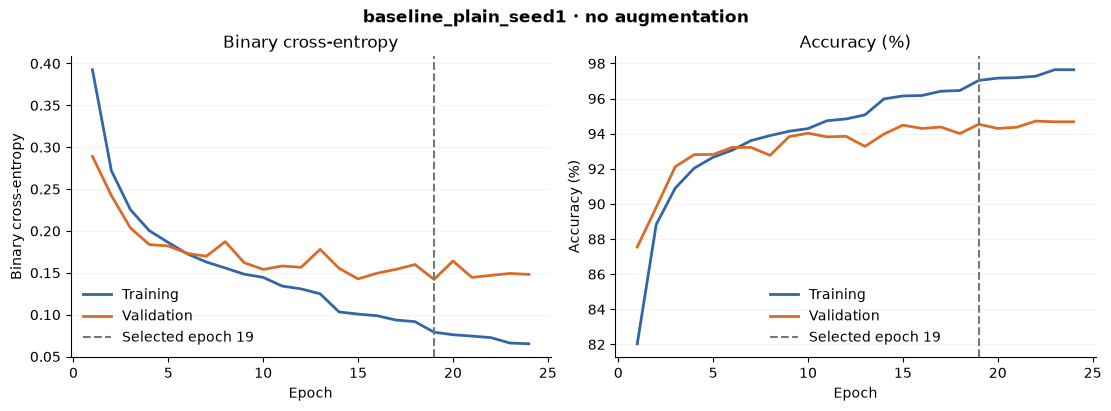

In [27]:
learning_fig = None
if history:
    epochs = [int(row["epoch"]) for row in history]
    learning_fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
    for ax, metric, scale, title in zip(
        axes, ["loss", "accuracy"], [1, 100], ["Binary cross-entropy", "Accuracy (%)"]
    ):
        ax.plot(
            epochs,
            [float(row[f"train_{metric}"]) * scale for row in history],
            label="Training",
            color="#3465a4",
            lw=2,
        )
        ax.plot(
            epochs,
            [float(row[f"val_{metric}"]) * scale for row in history],
            label="Validation",
            color="#d96b27",
            lw=2,
        )
        ax.axvline(
            selected_epoch,
            color="#777777",
            ls="--",
            label=f"Selected epoch {selected_epoch}",
        )
        ax.set(xlabel="Epoch", ylabel=title, title=title)
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", alpha=0.15)
        ax.legend(frameon=False)
    learning_fig.suptitle(f"{RUN_NAME} · no augmentation", fontweight="bold")
    plt.show()
else:
    print("Training history will appear after this run completes.")


## 9. Load the selected model for analysis

For the completed baseline, the trained weights are included **inside this notebook** and can be loaded on a CPU. No retraining, dataset download, sibling `.py` file, or separate model file is required. If a local full run is present, its selected `best.pt` is used. New named runs use their own selected checkpoints; they never silently fall back to the bundled baseline.

The loaded `model` is ready for later analysis. Inputs must be `[batch, 3, 32, 32]` RGB float tensors scaled to `[0,1]` on `device`. `torch.sigmoid(model(inputs))` gives P(REAL). Full optimizer and recovery states stay in local training checkpoints; the bundled weights are for inference.

In [28]:
# Load the selected checkpoint, falling back to the trained weights stored inside this notebook.
checkpoint = None
model = None
checkpoint_path = RUN_DIR / "best.pt"
if checkpoint_path.exists():
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    checkpoint_source = checkpoint_path.relative_to(ROOT).as_posix()
elif MODEL_PATH.exists():
    exported_summary = read_json(RESULTS_DIR / "summary.json")
    assert file_sha256(MODEL_PATH) == exported_summary["model_sha256"]
    checkpoint = torch.load(MODEL_PATH, map_location="cpu", weights_only=True)
    checkpoint_source = MODEL_PATH.relative_to(ROOT).as_posix()
elif RUN_NAME == EMBEDDED_RUN and SPLIT_SEED == 1:
    raw_weights = embedded_bytes(f"models/{EMBEDDED_RUN}.pt")
    assert (
        hashlib.sha256(raw_weights).hexdigest()
        == read_result("summary.json")["model_sha256"]
    )
    checkpoint = torch.load(BytesIO(raw_weights), map_location="cpu", weights_only=True)
    checkpoint_source = "the weights bundled inside this notebook"

if checkpoint is not None:
    model = BaselineCNN().to(device)
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    model.eval()
    assert checkpoint["epoch"] == selected_epoch
    print(f"Loaded epoch {checkpoint['epoch']} from {checkpoint_source}")
    print("Output convention: p_real = sigmoid(logit); p_fake = 1 - p_real.")
else:
    print("No selected checkpoint exists for this named run. Finish training first.")


Loaded epoch 19 from the weights bundled inside this notebook
Output convention: p_real = sigmoid(logit); p_fake = 1 - p_real.


## 10. Inspect a few validation predictions

The learning curves summarize many images, so we'll also look at a few individual predictions to see what those results mean in practice. We'll select four real and four fake images from the validation split with a fixed random seed and pass them through the selected model. Each thumbnail will show its true label, predicted label, and the model's probability score for FAKE. Comparing these lets us spot both mistakes and cases where the model is uncertain, as well as confident mistakes that may be worth investigating later. The thumbnails are enlarged without smoothing for display, while the model still receives the original 32×32 images. These examples come from validation, not the test set, and eight images cannot represent the full error pattern.

This optional cell needs the locally prepared validation data. Without it, the notebook still loads the trained model and displays the other saved results.

In [29]:
if model is not None and (DATA_DIR / "val_images.npy").exists():
    expected_manifest = checkpoint.get(
        "manifest_sha256", checkpoint.get("config", {}).get("manifest_sha256")
    )
    assert file_sha256(DATA_DIR / "manifest.csv") == expected_manifest
    val_images, val_labels, val_rows = load_split(DATA_DIR, "val")
    sample_rng = np.random.default_rng(42)
    sample_indices = np.concatenate(
        [
            sample_rng.choice(
                np.flatnonzero(val_labels == label), size=4, replace=False
            )
            for label in (0, 1)
        ]
    )
    inputs = (
        torch.from_numpy(val_images[sample_indices]).to(
            device=device, dtype=torch.float32
        )
        / 255
    )
    with torch.inference_mode():
        p_fake = (1 - torch.sigmoid(model(inputs))).cpu().numpy()
    fig, axes = plt.subplots(2, 4, figsize=(10, 5), layout="constrained")
    for ax, index, probability in zip(axes.flat, sample_indices, p_fake):
        truth = "FAKE" if val_labels[index] == 0 else "REAL"
        predicted = "FAKE" if probability > 0.5 else "REAL"
        ax.imshow(val_images[index].transpose(1, 2, 0), interpolation="nearest")
        ax.set_title(
            f"True: {truth} · Pred: {predicted}\nP(fake) = {probability:.1%}",
            fontsize=10,
            color="#28734e" if truth == predicted else "#a63434",
        )
        ax.axis("off")
    fig.suptitle("Validation examples · selected checkpoint", fontweight="bold")
    plt.show()
    del val_images, val_labels, val_rows, inputs
else:
    print(
        "Validation preview skipped: a trained model and local validation cache are required."
    )


Validation preview skipped: a trained model and local validation cache are required.


## 11. How does the CNN react when we change the images?

Here we'll use the trained CNN to explore its behaviour under changes to the input. We'll apply JPEG compression, blur, resizing, and noise to the **same 10,000 validation images**, keeping the model weights and the decision threshold fixed. For each type of change, we'll compare four strengths with the untouched original. This lets us follow a particular image as its prediction changes, as well as see whether real and fake images are affected differently across the full validation set.

The recorded probe uses **5,000 FAKE and 5,000 REAL images**, the selected epoch-19 baseline, and a fixed seed of 2026. The original images are the control: they are not re-encoded or resized. All modified inputs remain 32×32 RGB. JPEG quality is 95, 80, 60, or 40 with fixed 4:4:4 chroma sampling; blur standard deviation is 0.3, 0.6, 1.0, or 1.5 pixels; resizing goes from 32 to 28, 24, 20, or 16 pixels and back with bilinear interpolation; Gaussian noise has standard deviation 0.01, 0.03, 0.05, or 0.10 on RGB values in `[0,1]`. Noise is clipped and rounded back to 8-bit pixels, and each image uses the same noise pattern at every strength.

These are exploratory **validation** results. They help us choose what to investigate before the later model comparison; the existing test evaluation is not repeated. The figures and explorer below work from bundled prediction scores and 27 preview images, even without a local dataset. Set `RUN_BEHAVIOR_PROBE = True` in Section 2 to recompute the full probe from the local validation data. The bundled cell can stay collapsed.

**Defining the image changes.** We use named, fixed strengths of JPEG compression, blur, resizing and noise. Each modification is applied at the original image resolution so the input change can be inspected directly.

In [30]:
from io import BytesIO
from PIL import Image, ImageFilter, features as pillow_features
import hashlib
import importlib.metadata
import time

PROBE_SEED = 2026
PROBE_FAMILIES = {
    "JPEG": {
        "values": [95, 80, 60, 40],
        "axis": "JPEG quality",
        "labels": ["q95", "q80", "q60", "q40"],
    },
    "Blur": {
        "values": [0.3, 0.6, 1.0, 1.5],
        "axis": "Blur standard deviation (pixels)",
        "labels": ["0.3 px", "0.6 px", "1.0 px", "1.5 px"],
    },
    "Resize": {
        "values": [28, 24, 20, 16],
        "axis": "Intermediate image width (pixels)",
        "labels": ["28 px", "24 px", "20 px", "16 px"],
    },
    "Noise": {
        "values": [0.01, 0.03, 0.05, 0.10],
        "axis": "Noise standard deviation (RGB in [0, 1])",
        "labels": ["0.01", "0.03", "0.05", "0.10"],
    },
}


def behavior_conditions():
    """Use the same named modification strengths for every image and model."""
    conditions = [
        {"family": "Original", "value": None, "label": "Original", "level": 0}
    ]
    for family, spec in PROBE_FAMILIES.items():
        for level, (value, label) in enumerate(
            zip(spec["values"], spec["labels"]), start=1
        ):
            conditions.append(
                {"family": family, "value": value, "label": label, "level": level}
            )
    return conditions


def behavior_model_digest(model):
    """Identify the exact trained weights used by the saved behaviour probe."""
    digest = hashlib.sha256()
    for key, tensor in sorted(model.state_dict().items()):
        array = tensor.detach().cpu().contiguous().numpy()
        digest.update(key.encode())
        digest.update(str(array.dtype).encode())
        digest.update(str(array.shape).encode())
        digest.update(array.tobytes())
    return digest.hexdigest()


def modify_behavior_image(image, family, value, image_index, seed=PROBE_SEED):
    """Pure pixel transformation: uint8 CHW in/out, always 3x32x32."""
    assert image.dtype == np.uint8 and image.shape == (3, 32, 32)
    if family == "Original":
        return image.copy()
    if family == "Noise":
        # Reuse one noise field per image at every strength and in the explorer.
        rng = np.random.default_rng(np.random.SeedSequence([seed, int(image_index)]))
        noise = rng.standard_normal(image.shape, dtype=np.float32)
        changed = np.clip(image.astype(np.float32) / 255 + float(value) * noise, 0, 1)
        return np.rint(changed * 255).astype(np.uint8)
    source = Image.fromarray(image.transpose(1, 2, 0))
    if family == "JPEG":
        stream = BytesIO()
        # Keep chroma sampling fixed at 4:4:4; vary quality only.
        source.save(
            stream,
            format="JPEG",
            quality=int(value),
            subsampling=0,
            optimize=False,
            progressive=False,
        )
        stream.seek(0)
        with Image.open(stream) as decoded:
            result = np.array(decoded.convert("RGB"), dtype=np.uint8)
    elif family == "Blur":
        result = np.array(
            source.filter(ImageFilter.GaussianBlur(radius=float(value))), dtype=np.uint8
        )
    elif family == "Resize":
        width = int(value)
        result = np.array(
            source.resize((width, width), resample=Image.Resampling.BILINEAR).resize(
                (32, 32), resample=Image.Resampling.BILINEAR
            ),
            dtype=np.uint8,
        )
    else:
        raise ValueError(f"Unknown modification: {family}")
    return result.transpose(2, 0, 1).copy()


**Measuring the frozen CNN.** These helpers predict on original and modified validation images and record both aggregate metrics and individual scores. The network stays fixed throughout the comparison.

In [31]:
@torch.inference_mode()
def behavior_predict(model, images, device, batch_size=256):
    """Collect fixed-model predictions in batches for one image condition."""
    model.eval()
    scores = []
    for start in range(0, len(images), batch_size):
        inputs = (
            torch.from_numpy(
                np.ascontiguousarray(images[start : start + batch_size])
            ).to(device=device, dtype=torch.float32)
            / 255
        )
        scores.append((1 - torch.sigmoid(model(inputs))).cpu().numpy())
    result = np.concatenate(scores).astype(np.float32)
    assert result.shape == (len(images),) and np.isfinite(result).all()
    return result


def behavior_metrics(probabilities, labels):
    """Summarize saved FAKE probabilities without changing the classification threshold."""
    truth_fake = labels == 0
    predicted_fake = probabilities > 0.5  # A tie is REAL, matching the baseline.
    correct = predicted_fake == truth_fake[None, :]
    clean_correct = correct[0]
    return {
        "accuracy": correct.mean(axis=1),
        "fake_detected": predicted_fake[:, truth_fake].mean(axis=1),
        "real_accepted": (~predicted_fake[:, ~truth_fake]).mean(axis=1),
        "real_false_alarm": predicted_fake[:, ~truth_fake].mean(axis=1),
        "changed_label": (predicted_fake != predicted_fake[0]).mean(axis=1),
        "new_mistake": (clean_correct[None, :] & ~correct).mean(axis=1),
        "corrected_mistake": (~clean_correct[None, :] & correct).mean(axis=1),
    }


def run_behavior_probe(model, data_dir, device, selected_epoch, expected_manifest):
    """Frozen-model exploration on every validation image, never test pixels."""
    started = time.perf_counter()
    if file_sha256(data_dir / "manifest.csv") != expected_manifest:
        raise ValueError(
            "Validation split differs from the selected model training split."
        )
    images, labels, rows = load_split(data_dir, "val")
    assert all(row["split"] == "val" and row["source_split"] == "train" for row in rows)
    assert set(np.unique(labels)) == {0, 1}
    digest_before = behavior_model_digest(model)
    conditions = behavior_conditions()
    scores = [behavior_predict(model, images, device)]
    mean_pixel_changes = [0.0]
    print(
        f'Original: n={len(labels):,}, accuracy={behavior_metrics(np.stack(scores), labels)["accuracy"][0]:.2%}',
        flush=True,
    )
    for condition in conditions[1:]:
        changed = np.stack(
            [
                modify_behavior_image(image, condition["family"], condition["value"], i)
                for i, image in enumerate(images)
            ]
        )
        assert changed.shape == images.shape and changed.dtype == np.uint8
        scores.append(behavior_predict(model, changed, device))
        mean_pixel_changes.append(
            float(
                np.abs(changed.astype(np.float32) - images.astype(np.float32)).mean()
                / 255
            )
        )
        report = behavior_metrics(np.stack([scores[0], scores[-1]]), labels)
        print(
            f"{condition['family']:6} {condition['label']:7} | accuracy {report['accuracy'][1]:.2%} | fake detected {report['fake_detected'][1]:.2%} | real false alarm {report['real_false_alarm'][1]:.2%} | changed label {report['changed_label'][1]:.2%}",
            flush=True,
        )
        del changed
    probabilities = np.stack(scores)
    assert digest_before == behavior_model_digest(model)
    truth_fake = labels == 0
    clean_correct = (probabilities[0] > 0.5) == truth_fake
    gallery_indices = {}
    preview_ids = []
    for family in PROBE_FAMILIES:
        condition_index = next(
            i
            for i, c in enumerate(conditions)
            if c["family"] == family and c["level"] == 2
        )
        gallery_indices[family] = {}
        for class_name, label in [("FAKE", 0), ("REAL", 1)]:
            candidates = np.flatnonzero((labels == label) & clean_correct)
            # Largest movement toward the wrong class among clean-correct images.
            direction = -1 if label == 0 else 1
            change = direction * (
                probabilities[condition_index, candidates]
                - probabilities[0, candidates]
            )
            chosen = int(candidates[np.argmax(change)])
            gallery_indices[family][class_name] = chosen
            preview_ids.append(chosen)
            incorrect = np.flatnonzero((labels == label) & ~clean_correct)
            if len(incorrect):
                recovery = -direction * (
                    probabilities[condition_index, incorrect]
                    - probabilities[0, incorrect]
                )
                preview_ids.append(int(incorrect[np.argmax(recovery)]))
    rng = np.random.default_rng(PROBE_SEED)
    for label in [0, 1]:
        preview_ids.extend(
            rng.choice(np.flatnonzero(labels == label), size=6, replace=False).tolist()
        )
    preview_ids = np.array(list(dict.fromkeys(preview_ids)), dtype=np.int32)
    arrays = {
        "labels": labels.astype(np.int8),
        "p_fake": probabilities,
        "paths": np.asarray([row["path"] for row in rows]),
        "preview_indices": preview_ids,
        "preview_images": images[preview_ids],
        "mean_absolute_pixel_change": np.asarray(mean_pixel_changes, dtype=np.float32),
    }
    metadata = {
        "split": "val",
        "n": len(labels),
        "class_counts": {
            "FAKE": int((labels == 0).sum()),
            "REAL": int((labels == 1).sum()),
        },
        "model_state_sha256": digest_before,
        "selected_epoch": int(selected_epoch),
        "manifest_sha256": expected_manifest,
        "seed": PROBE_SEED,
        "conditions": conditions,
        "gallery_indices": gallery_indices,
        "gallery_selection": "For each class and family, choose the largest shift toward the wrong class at level 2 among clean-correct validation images.",
        "preview_selection": "Gallery cases, largest score recoveries among clean-wrong images at level 2, and six seeded random examples per class; duplicates removed.",
        "decision_rule": "FAKE if P(FAKE)>0.5; otherwise REAL.",
        "transforms": {
            "JPEG": "Re-encode decoded RGB in memory, quality 95/80/60/40; fixed 4:4:4 chroma sampling, no optimization/progressive mode. Original control is not re-encoded.",
            "Blur": "Pillow GaussianBlur, standard deviation 0.3/0.6/1.0/1.5 pixels.",
            "Resize": "32 -> 28/24/20/16 -> 32 with Pillow bilinear interpolation in both directions.",
            "Noise": "Independent Gaussian RGB noise in [0,1], sigma 0.01/0.03/0.05/0.10; clipped to [0,1], rounded to uint8. Same seeded noise field per image across strengths.",
        },
        "environment": {
            "torch": str(torch.__version__),
            "numpy": np.__version__,
            "pillow": importlib.metadata.version("pillow"),
            "jpeg_codec": pillow_features.version_codec("jpg"),
            "device": str(device),
        },
        "elapsed_seconds": time.perf_counter() - started,
        "scope": "Exploratory validation-set model behavior. Fixed selected model; no training, no test evaluation, no causal claim about learned features.",
    }
    return arrays, metadata


**Saved review data.** The trained weights and saved measurements are stored in notebook metadata, so there is no long encoded string to scroll through. This short loader checks and decodes the data when needed. Keep the complete `.ipynb` file when sharing it.

In [32]:
# Saved validation predictions and a small preview set; no training runs here.
BEHAVIOR_METADATA_JSON = json.dumps(
    {
        "split": "val",
        "n": 10000,
        "class_counts": {"FAKE": 5000, "REAL": 5000},
        "model_state_sha256": "2b73e9f88f029ae7f9d33935864ceeefbd443b7d80a87e532301909a3c0a90a8",
        "selected_epoch": 19,
        "manifest_sha256": "098210d89f9441376008d520f72aeef5f65a7aa6b5e0073ba4e875c979e1f205",
        "seed": 2026,
        "conditions": [
            {"family": "Original", "value": None, "label": "Original", "level": 0},
            {"family": "JPEG", "value": 95, "label": "q95", "level": 1},
            {"family": "JPEG", "value": 80, "label": "q80", "level": 2},
            {"family": "JPEG", "value": 60, "label": "q60", "level": 3},
            {"family": "JPEG", "value": 40, "label": "q40", "level": 4},
            {"family": "Blur", "value": 0.3, "label": "0.3 px", "level": 1},
            {"family": "Blur", "value": 0.6, "label": "0.6 px", "level": 2},
            {"family": "Blur", "value": 1.0, "label": "1.0 px", "level": 3},
            {"family": "Blur", "value": 1.5, "label": "1.5 px", "level": 4},
            {"family": "Resize", "value": 28, "label": "28 px", "level": 1},
            {"family": "Resize", "value": 24, "label": "24 px", "level": 2},
            {"family": "Resize", "value": 20, "label": "20 px", "level": 3},
            {"family": "Resize", "value": 16, "label": "16 px", "level": 4},
            {"family": "Noise", "value": 0.01, "label": "0.01", "level": 1},
            {"family": "Noise", "value": 0.03, "label": "0.03", "level": 2},
            {"family": "Noise", "value": 0.05, "label": "0.05", "level": 3},
            {"family": "Noise", "value": 0.1, "label": "0.10", "level": 4},
        ],
        "gallery_indices": {
            "JPEG": {"FAKE": 752, "REAL": 9255},
            "Blur": {"FAKE": 3571, "REAL": 7473},
            "Resize": {"FAKE": 1358, "REAL": 7473},
            "Noise": {"FAKE": 50, "REAL": 6193},
        },
        "gallery_selection": "For each class and family, choose the largest shift "
        "toward the wrong class at level 2 among clean-correct "
        "validation images.",
        "preview_selection": "Gallery cases, largest score recoveries among "
        "clean-wrong images at level 2, and six seeded random "
        "examples per class; duplicates removed.",
        "decision_rule": "FAKE if P(FAKE)>0.5; otherwise REAL.",
        "transforms": {
            "JPEG": "Re-encode decoded RGB in memory, quality 95/80/60/40; "
            "fixed 4:4:4 chroma sampling, no "
            "optimization/progressive mode. Original control is "
            "not re-encoded.",
            "Blur": "Pillow GaussianBlur, standard deviation "
            "0.3/0.6/1.0/1.5 pixels.",
            "Resize": "32 -> 28/24/20/16 -> 32 with Pillow bilinear "
            "interpolation in both directions.",
            "Noise": "Independent Gaussian RGB noise in [0,1], sigma "
            "0.01/0.03/0.05/0.10; clipped to [0,1], rounded to "
            "uint8. Same seeded noise field per image across "
            "strengths.",
        },
        "environment": {
            "torch": "2.15.0",
            "numpy": "2.5.4",
            "pillow": "13.0.0",
            "jpeg_codec": "6.2",
            "device": "mps",
        },
        "elapsed_seconds": 10.356811792124063,
        "scope": "Exploratory validation-set model behavior. Fixed selected model; no "
        "training, no test evaluation, no causal claim about learned "
        "features.",
    }
)
BEHAVIOR_BUNDLE_SHA256 = (
    "c57176388e6d839f96c1fa443fd1b09079e9c2b72085b1ee8bd978fa1e8046bd"
)
BEHAVIOR_BUNDLE = notebook_payload("baseline_validation_bundle")


def load_behavior_bundle():
    """Decode and check the saved validation predictions used by the figures."""
    raw = base64.b64decode(BEHAVIOR_BUNDLE, validate=True)
    assert hashlib.sha256(raw).hexdigest() == BEHAVIOR_BUNDLE_SHA256
    with np.load(BytesIO(raw), allow_pickle=False) as archive:
        arrays = {key: archive[key].copy() for key in archive.files}
    report = json.loads(BEHAVIOR_METADATA_JSON)
    assert arrays["p_fake"].shape == (len(report["conditions"]), report["n"])
    assert len(arrays["labels"]) == len(arrays["paths"]) == report["n"]
    assert np.isfinite(arrays["p_fake"]).all()
    assert ((arrays["p_fake"] >= 0) & (arrays["p_fake"] <= 1)).all()
    assert arrays["preview_images"].shape == (len(arrays["preview_indices"]), 3, 32, 32)
    assert arrays["preview_images"].dtype == np.uint8
    assert len(np.unique(arrays["preview_indices"])) == len(arrays["preview_indices"])
    assert report["conditions"] == behavior_conditions()
    return arrays, report


In [33]:
# Use saved validation predictions by default; recomputing the probe is an explicit option.
behavior_arrays, behavior_report = None, None
if model is None:
    print("Load the selected model in Section 9 before exploring its behaviour.")
elif RUN_BEHAVIOR_PROBE:
    expected_manifest = checkpoint.get(
        "manifest_sha256", checkpoint.get("config", {}).get("manifest_sha256")
    )
    behavior_arrays, behavior_report = run_behavior_probe(
        model, DATA_DIR, device, checkpoint["epoch"], expected_manifest
    )
else:
    candidate_arrays, candidate_report = load_behavior_bundle()
    expected_manifest = checkpoint.get(
        "manifest_sha256", checkpoint.get("config", {}).get("manifest_sha256")
    )
    if (
        behavior_model_digest(model) == candidate_report["model_state_sha256"]
        and expected_manifest == candidate_report["manifest_sha256"]
    ):
        behavior_arrays, behavior_report = candidate_arrays, candidate_report
        print(
            "Loaded the saved validation probe; the selected model and split match its fingerprints."
        )
    else:
        print(
            "The saved probe belongs to a different model or split. Enable RUN_BEHAVIOR_PROBE to explore the current run."
        )

if behavior_arrays is not None:
    behavior_scores = behavior_arrays["p_fake"]
    behavior_labels = behavior_arrays["labels"]
    behavior_conditions_list = behavior_report["conditions"]
    behavior_groups = {
        family: [0]
        + [i for i, c in enumerate(behavior_conditions_list) if c["family"] == family]
        for family in PROBE_FAMILIES
    }
    behavior_stats = behavior_metrics(behavior_scores, behavior_labels)
    behavior_previews = {
        int(index): image
        for index, image in zip(
            behavior_arrays["preview_indices"], behavior_arrays["preview_images"]
        )
    }
    behavior_colors = {"REAL": "#0072B2", "FAKE": "#D55E00"}
    print(
        f"Validation images: {behavior_report['n']:,} · Conditions: {len(behavior_conditions_list)} · Selected epoch: {behavior_report['selected_epoch']}"
    )
    print(
        f"Original accuracy: {behavior_stats['accuracy'][0]:.2%} · Fake detected: {behavior_stats['fake_detected'][0]:.2%} · Real false alarms: {behavior_stats['real_false_alarm'][0]:.2%}"
    )


def finish_behavior_figure(fig, filename):
    if SAVE_FIGURES:
        destination = ROOT / "results" / f"{RUN_NAME}_validation_behavior"
        destination.mkdir(parents=True, exist_ok=True)
        fig.savefig(
            destination / f"{filename}.png",
            dpi=160,
            bbox_inches="tight",
            facecolor="white",
        )
    plt.show()
    plt.close(fig)


def behavior_axes_style(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(alpha=0.15)
    ax.set_axisbelow(True)


def plot_behavior_gallery(class_name):
    fig, axes = plt.subplots(4, 5, figsize=(12.5, 10.7), layout="constrained")
    for row, family in enumerate(PROBE_FAMILIES):
        index = behavior_report["gallery_indices"][family][class_name]
        original = behavior_previews[index]
        for column, condition_index in enumerate(behavior_groups[family]):
            condition = behavior_conditions_list[condition_index]
            changed = modify_behavior_image(
                original, condition["family"], condition["value"], index
            )
            score = float(behavior_scores[condition_index, index])
            predicted = "FAKE" if score > 0.5 else "REAL"
            color = "#28734e" if predicted == class_name else "#a63434"
            ax = axes[row, column]
            ax.imshow(changed.transpose(1, 2, 0), interpolation="nearest")
            label = "Original" if column == 0 else condition["label"]
            ax.set_title(
                f"{family} · {label}\nP(fake)={score:.1%} · {predicted}",
                fontsize=9,
                color=color,
            )
            ax.axis("off")
            if column == 0:
                ax.text(
                    0.5,
                    -0.045,
                    Path(str(behavior_arrays["paths"][index])).name,
                    transform=ax.transAxes,
                    ha="center",
                    va="top",
                    fontsize=8,
                )
    fig.suptitle(
        f"True label: {class_name} · selected sensitive validation examples\nGreen title = correct; red title = wrong",
        fontsize=13,
        fontweight="bold",
    )
    finish_behavior_figure(fig, f"gallery_{class_name.lower()}")


Loaded the saved validation probe; the selected model and split match its fingerprints.
Validation images: 10,000 · Conditions: 17 · Selected epoch: 19
Original accuracy: 94.54% · Fake detected: 94.60% · Real false alarms: 5.52%


### 11.1 Watch the same fake image change

We'll first look at one fake image for each kind of modification, with the original on the left and four changed versions beside it. Each row follows the same image, so differences in its score cannot be explained by switching to a different picture. The title above each thumbnail gives P(FAKE) and the predicted label; green titles are correct and red titles are mistakes. To make sensitivity visible, each example was chosen from images the CNN originally classified correctly, using the largest drop in P(FAKE) at the second tested strength. These are deliberately selected cases rather than a random sample. Look for the point where the prediction changes, how much the image has visibly changed by then, and whether the score continues in the same direction as the modification becomes stronger.

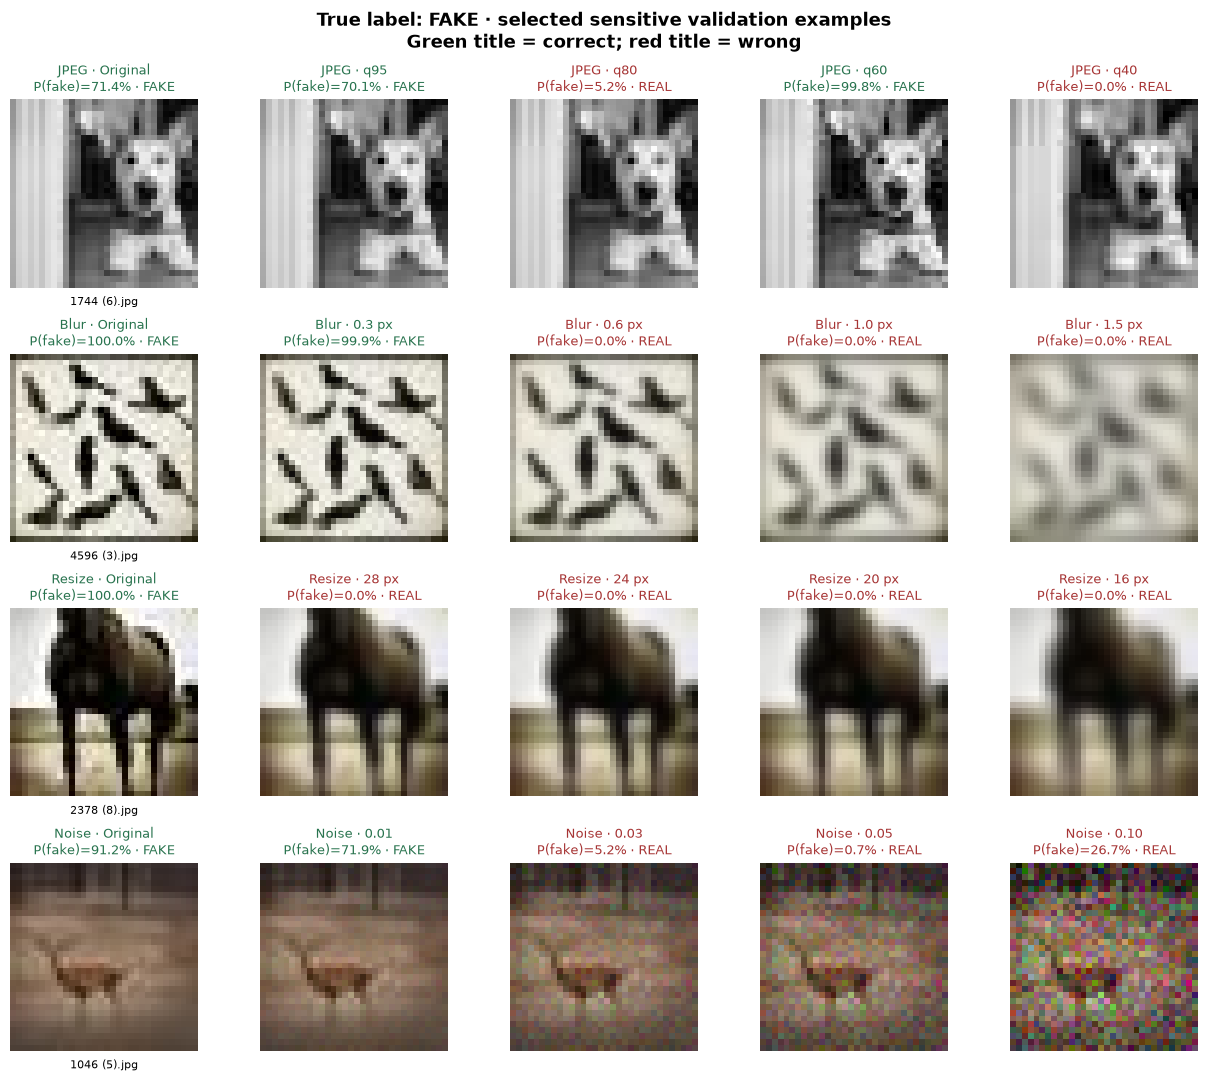

In [34]:
if behavior_arrays is not None:
    plot_behavior_gallery("FAKE")


### 11.2 What happens to real images?

The same changes can also cause a different kind of mistake: a real image may start to look fake to the model. We'll use the same layout for real validation images, again showing the original and all four strengths. Here the chosen examples have the largest rise in P(FAKE) at the second tested strength among images that were originally classified correctly. Comparing these rows with the fake-image gallery helps us see whether a modification shifts both classes in the same direction or affects them differently. An example may remain correctly classified even after a large score change, and a stronger modification may sometimes reverse an earlier change. The full-set plots below will show how common these behaviours are.

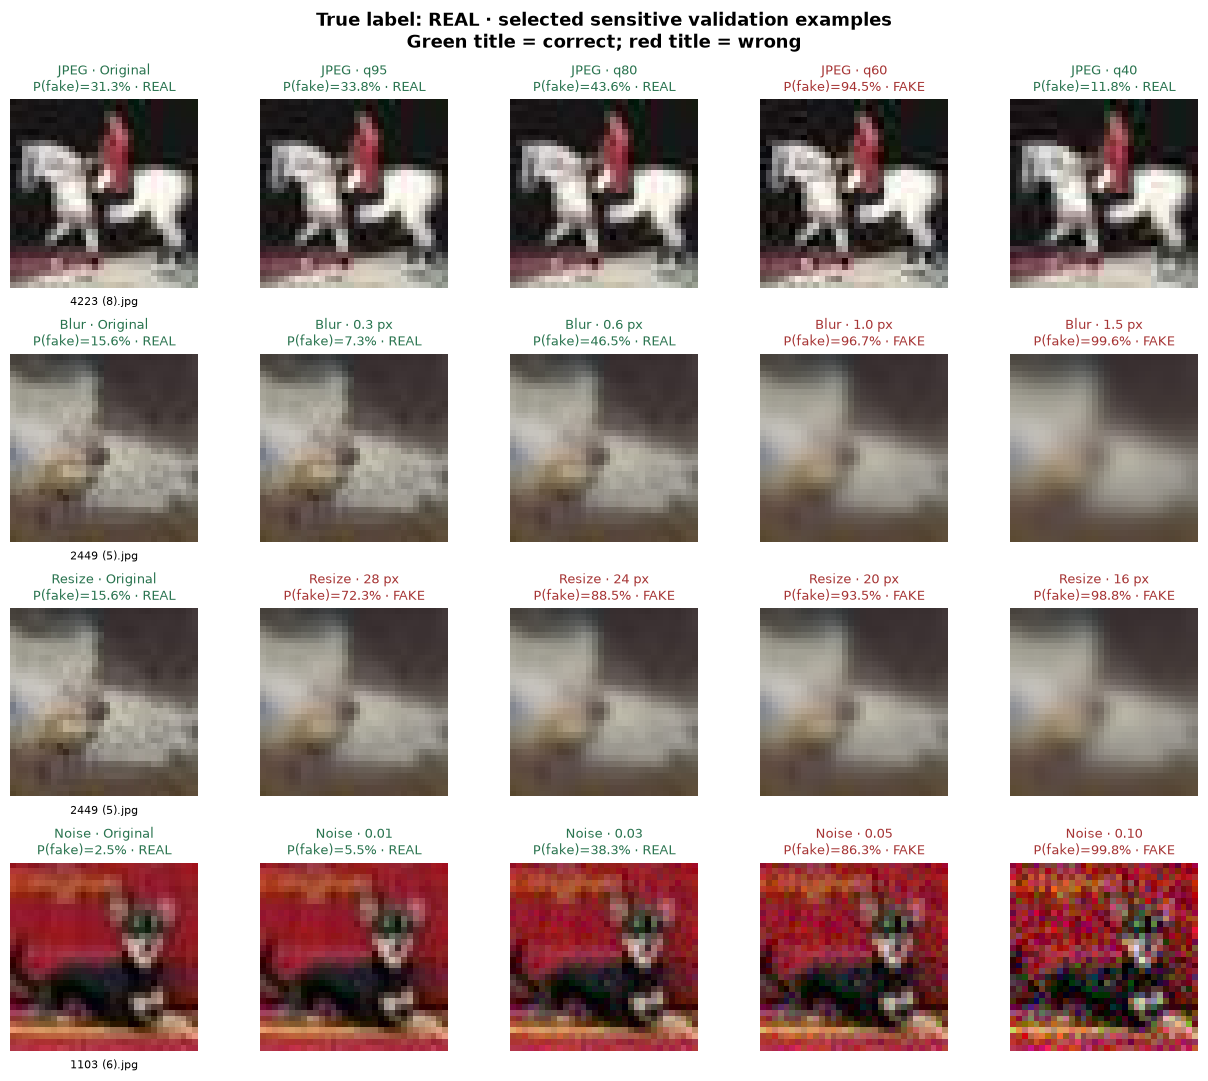

In [35]:
if behavior_arrays is not None:
    plot_behavior_gallery("REAL")


### 11.3 Compare behaviour across all validation images

The galleries make individual changes visible, but they were chosen to show sensitivity. We'll now use all 10,000 validation images to put those examples in context. Each panel will plot the original input and the four tested settings for one modification. The orange line shows the percentage of fake images correctly detected, the blue line shows the percentage of real images correctly accepted, and the dashed line shows overall accuracy. All three lines use the same percentage scale. If one class stays accurate while the other drops, the model may be shifting toward one predicted label, which an overall accuracy curve alone would hide. The horizontal settings are specific to each modification; the same position in different panels does not mean an equally strong visual change. Lines connect measured settings and do not represent results for untested strengths.

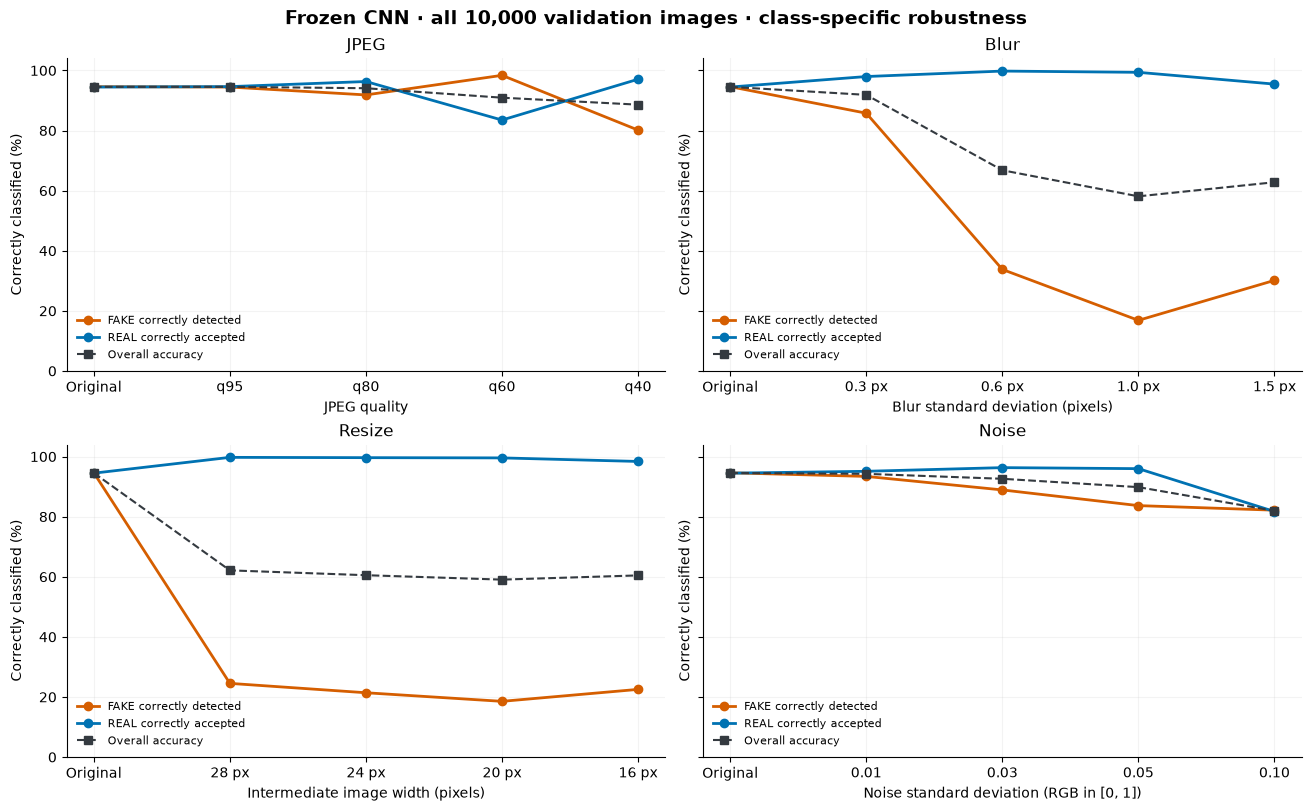

In [36]:
# Compare aggregate behaviour across all validation images, rather than only the selected gallery examples.
if behavior_arrays is not None:
    fig, axes = plt.subplots(2, 2, figsize=(13, 8), layout="constrained", sharey=True)
    for ax, (family, indices) in zip(axes.flat, behavior_groups.items()):
        x = np.arange(len(indices))
        ax.plot(
            x,
            100 * behavior_stats["fake_detected"][indices],
            color=behavior_colors["FAKE"],
            marker="o",
            label="FAKE correctly detected",
            lw=2,
        )
        ax.plot(
            x,
            100 * behavior_stats["real_accepted"][indices],
            color=behavior_colors["REAL"],
            marker="o",
            label="REAL correctly accepted",
            lw=2,
        )
        ax.plot(
            x,
            100 * behavior_stats["accuracy"][indices],
            color="#343a40",
            marker="s",
            ls="--",
            label="Overall accuracy",
            lw=1.5,
        )
        ax.set(
            title=family,
            xlabel=PROBE_FAMILIES[family]["axis"],
            ylabel="Correctly classified (%)",
            ylim=(0, 104),
            xticks=x,
            xticklabels=["Original"] + PROBE_FAMILIES[family]["labels"],
        )
        behavior_axes_style(ax)
        ax.legend(frameon=False, fontsize=8, loc="lower left")
    fig.suptitle(
        "Frozen CNN · all 10,000 validation images · class-specific robustness",
        fontsize=14,
        fontweight="bold",
    )
    finish_behavior_figure(fig, "robustness_curves")


### 11.4 See how the probability scores move

A label only tells us which side of the decision threshold an image falls on. To see the size and direction of the change, we'll plot each image's original P(FAKE) on the horizontal axis and its modified P(FAKE) on the vertical axis. Points on the diagonal have unchanged scores; points below it moved toward REAL and points above it moved toward FAKE. The horizontal and vertical lines at 0.5 divide the plot into regions where predictions stayed the same or switched labels. We'll show the same seeded sample of 400 real and 400 fake validation images in each panel, using the second tested setting for each modification. These settings are labelled explicitly and are not assumed to have equivalent severity. This view makes it possible to distinguish a general shift in scores from a few isolated label changes.

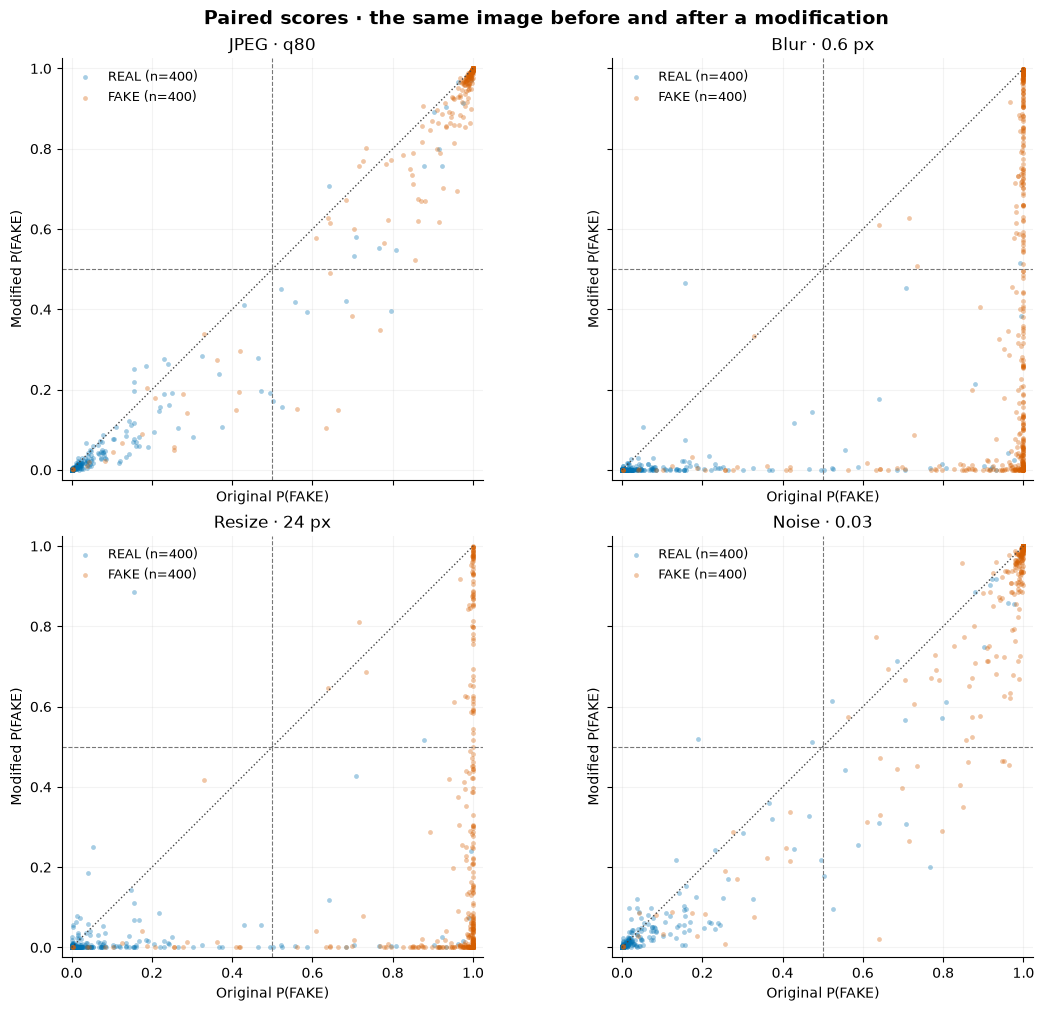

In [37]:
if behavior_arrays is not None:
    score_rng = np.random.default_rng(PROBE_SEED)
    behavior_scatter_ids = np.concatenate(
        [
            score_rng.choice(
                np.flatnonzero(behavior_labels == label), 400, replace=False
            )
            for label in [0, 1]
        ]
    )
    fig, axes = plt.subplots(
        2, 2, figsize=(11, 10), layout="constrained", sharex=True, sharey=True
    )
    for ax, (family, indices) in zip(axes.flat, behavior_groups.items()):
        condition_index = indices[2]
        for name, label in [("REAL", 1), ("FAKE", 0)]:
            ids = behavior_scatter_ids[behavior_labels[behavior_scatter_ids] == label]
            ax.scatter(
                behavior_scores[0, ids],
                behavior_scores[condition_index, ids],
                s=12,
                alpha=0.35,
                color=behavior_colors[name],
                linewidths=0,
                label=f"{name} (n=400)",
            )
        ax.plot([0, 1], [0, 1], ls=":", color="#444444", lw=1)
        ax.axvline(0.5, ls="--", color="#777777", lw=0.8)
        ax.axhline(0.5, ls="--", color="#777777", lw=0.8)
        ax.set(
            title=f"{family} · {behavior_conditions_list[condition_index]['label']}",
            xlabel="Original P(FAKE)",
            ylabel="Modified P(FAKE)",
            xlim=(-0.025, 1.025),
            ylim=(-0.025, 1.025),
            aspect="equal",
        )
        ax.legend(frameon=False, fontsize=9, loc="upper left")
        behavior_axes_style(ax)
    fig.suptitle(
        "Paired scores · the same image before and after a modification",
        fontsize=14,
        fontweight="bold",
    )
    finish_behavior_figure(fig, "paired_probability_scores")


### 11.5 Follow individual images across all modifications

We'll also display a small map of prediction changes to see whether the same images are sensitive to several modifications. Each row represents one validation image and each column represents one tested setting. Orange means an originally correct prediction became wrong, green means an originally wrong prediction became correct, and grey means the predicted label stayed the same. Grey therefore does not necessarily mean correct. We'll use a fixed random sample of 100 fake and 100 real images, and place images whose original scores were closer to 0.5 near the top of each class group. Reading across a row shows an image's pattern of changes; reading down a column shows which examples were affected by that setting. The image selection is illustrative, while the preceding robustness curves use the entire validation set.

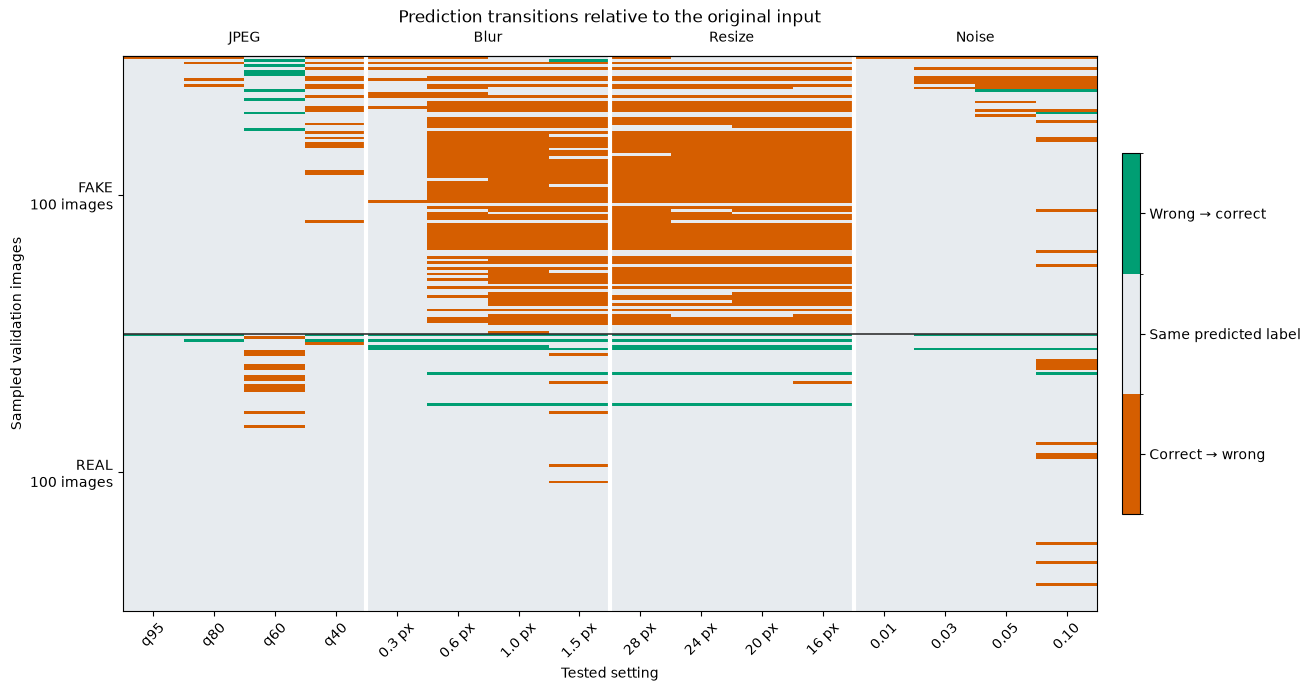

In [38]:
if behavior_arrays is not None:
    from matplotlib.colors import ListedColormap, BoundaryNorm

    transition_rng = np.random.default_rng(PROBE_SEED + 1)
    transition_ids = []
    for label in [0, 1]:
        ids = transition_rng.choice(
            np.flatnonzero(behavior_labels == label), 100, replace=False
        )
        ids = ids[np.argsort(np.abs(behavior_scores[0, ids] - 0.5), kind="stable")]
        transition_ids.extend(ids.tolist())
    transition_ids = np.asarray(transition_ids)
    all_correct = (behavior_scores > 0.5) == (behavior_labels == 0)[None, :]
    changes = all_correct[1:, transition_ids].astype(np.int8) - all_correct[
        0, transition_ids
    ].astype(np.int8)
    cmap = ListedColormap(["#D55E00", "#e7ebef", "#009E73"])
    fig, ax = plt.subplots(figsize=(13, 6.8), layout="constrained")
    heat = ax.imshow(
        changes.T,
        aspect="auto",
        interpolation="nearest",
        cmap=cmap,
        norm=BoundaryNorm([-1.5, -0.5, 0.5, 1.5], 3),
    )
    for boundary in [3.5, 7.5, 11.5]:
        ax.axvline(boundary, color="white", lw=3)
    ax.axhline(99.5, color="#333333", lw=1.2)
    ax.set(
        xticks=np.arange(16),
        xticklabels=[c["label"] for c in behavior_conditions_list[1:]],
        yticks=[49.5, 149.5],
        yticklabels=["FAKE\n100 images", "REAL\n100 images"],
        xlabel="Tested setting",
        ylabel="Sampled validation images",
        title="Prediction transitions relative to the original input",
    )
    ax.tick_params(axis="x", labelrotation=45)
    top = ax.secondary_xaxis("top")
    top.set_xticks([1.5, 5.5, 9.5, 13.5], list(PROBE_FAMILIES))
    top.tick_params(length=0, pad=8)
    colorbar = fig.colorbar(heat, ax=ax, ticks=[-1, 0, 1], shrink=0.65, pad=0.025)
    colorbar.ax.set_yticklabels(
        ["Correct → wrong", "Same predicted label", "Wrong → correct"]
    )
    finish_behavior_figure(fig, "prediction_transitions")


### 11.6 Try the changes yourself

The explorer below lets us inspect these behaviours one image at a time. Choose an image, select a modification, and move the strength slider from the original to one of the four tested settings. The two thumbnails will show the original and modified pixels side by side, while the score plot will show that image's P(FAKE) across all settings of the selected modification. The highlighted point follows the slider, and the dashed line marks the decision threshold. The preview set includes the sensitive gallery cases, examples with large score movements toward the correct label among initially incorrect predictions, and a few randomly selected images. It is designed for inspection rather than estimating how often a behaviour occurs. The preview images and measured scores are bundled in this notebook, so these controls work with a live kernel even without the full dataset; moving them does not train or reevaluate the model.

In [39]:
if behavior_arrays is not None:
    import html
    import ipywidgets as widgets

    preview_choices = [
        (
            f"{'FAKE' if behavior_labels[int(index)]==0 else 'REAL'} · {behavior_arrays['paths'][int(index)]}",
            int(index),
        )
        for index in behavior_arrays["preview_indices"]
    ]
    behavior_image_choice = widgets.Dropdown(
        options=preview_choices,
        description="Image:",
        layout=widgets.Layout(width="95%"),
    )
    behavior_family_choice = widgets.Dropdown(
        options=list(PROBE_FAMILIES), description="Change:"
    )
    behavior_level_choice = widgets.IntSlider(
        value=2, min=0, max=4, step=1, description="Strength:", continuous_update=False
    )
    behavior_original_widget = widgets.Image(format="png", width=192, height=192)
    behavior_modified_widget = widgets.Image(format="png", width=192, height=192)
    behavior_original_label = widgets.HTML()
    behavior_modified_label = widgets.HTML()
    behavior_details_widget = widgets.HTML()
    behavior_trajectory_widget = widgets.Image(format="png")
    behavior_explorer_state = {}

    def behavior_png(image, size=192):
        stream = BytesIO()
        Image.fromarray(image.transpose(1, 2, 0)).resize(
            (size, size), Image.Resampling.NEAREST
        ).save(stream, format="PNG")
        return stream.getvalue()

    def update_behavior_explorer(change=None):
        index = int(behavior_image_choice.value)
        family = behavior_family_choice.value
        level = int(behavior_level_choice.value)
        indices = behavior_groups[family]
        condition_index = indices[level]
        condition = behavior_conditions_list[condition_index]
        original = behavior_previews[index]
        changed = modify_behavior_image(
            original, condition["family"], condition["value"], index
        )
        original_score = float(behavior_scores[0, index])
        changed_score = float(behavior_scores[condition_index, index])
        truth = "FAKE" if behavior_labels[index] == 0 else "REAL"
        predicted_original = "FAKE" if original_score > 0.5 else "REAL"
        predicted_changed = "FAKE" if changed_score > 0.5 else "REAL"
        behavior_original_widget.value = behavior_png(original)
        behavior_modified_widget.value = behavior_png(changed)
        behavior_original_label.value = (
            f"<b>Original</b><br>P(FAKE): {original_score:.1%} · {predicted_original}"
        )
        setting = "Original" if level == 0 else f"{family} · {condition['label']}"
        behavior_modified_label.value = (
            f"<b>{setting}</b><br>P(FAKE): {changed_score:.1%} · {predicted_changed}"
        )
        behavior_details_widget.value = (
            f"<b>True label: {truth}</b> · <code>{html.escape(str(behavior_arrays['paths'][index]))}</code><br>"
            f"Score change: {100*(changed_score-original_score):+.1f} percentage points · "
            f"Prediction {'changed' if predicted_original!=predicted_changed else 'stayed the same'}. "
            "Images are enlarged for viewing; the model input stays 32×32."
        )
        fig, ax = plt.subplots(figsize=(6.5, 3.0), layout="constrained")
        ax.plot(
            np.arange(5),
            behavior_scores[indices, index],
            marker="o",
            lw=2,
            color=behavior_colors[truth],
        )
        ax.scatter(
            [level],
            [changed_score],
            s=110,
            facecolors="none",
            edgecolors="#222222",
            linewidths=2,
            zorder=5,
        )
        ax.axhline(0.5, ls="--", color="#777777", lw=1)
        ax.set(
            xticks=np.arange(5),
            xticklabels=["Original"] + PROBE_FAMILIES[family]["labels"],
            ylim=(-0.04, 1.04),
            ylabel="P(FAKE)",
            xlabel=PROBE_FAMILIES[family]["axis"],
            title=f"{family} · score trajectory",
        )
        behavior_axes_style(ax)
        stream = BytesIO()
        fig.savefig(
            stream, format="png", dpi=120, bbox_inches="tight", facecolor="white"
        )
        plt.close(fig)
        behavior_trajectory_widget.value = stream.getvalue()
        behavior_explorer_state.update(
            index=index,
            condition_index=condition_index,
            score=changed_score,
            pixels=changed,
        )

    for control in [
        behavior_image_choice,
        behavior_family_choice,
        behavior_level_choice,
    ]:
        control.observe(update_behavior_explorer, names="value")
    update_behavior_explorer()
    display(
        widgets.VBox(
            [
                behavior_image_choice,
                widgets.HBox([behavior_family_choice, behavior_level_choice]),
                widgets.HBox(
                    [
                        widgets.VBox(
                            [behavior_original_label, behavior_original_widget]
                        ),
                        widgets.VBox(
                            [behavior_modified_label, behavior_modified_widget]
                        ),
                    ],
                    layout=widgets.Layout(gap="24px"),
                ),
                behavior_details_widget,
                behavior_trajectory_widget,
            ]
        )
    )
    print(
        "Run this cell with a live kernel to use the controls. The static figures above are available on GitHub."
    )


Run this cell with a live kernel to use the controls. The static figures above are available on GitHub.


### 11.7 What is worth investigating next?

The table below will bring a few measured settings back together so we can connect the image-level views with the full validation results. We'll compare overall accuracy, the fraction of fake images detected, false alarms on real images, and the fraction of all images whose predicted label changed from the original. The settings are examples from this exploratory sweep, not equally severe or optimized attacks. We can use these observations to choose image sequences, score trajectories, and before/after feature visualizations for the next part of the course. They describe how this fixed CNN responds under the specified processing choices; they do not establish why it learned that behaviour or how another model will respond.

In [40]:
if behavior_arrays is not None:
    example_indices = [
        0,
        behavior_groups["JPEG"][3],
        behavior_groups["Blur"][2],
        behavior_groups["Resize"][1],
        behavior_groups["Noise"][4],
    ]
    show_table(
        [
            "Input",
            "Accuracy",
            "FAKE detected",
            "REAL flagged FAKE",
            "Changed predicted label",
        ],
        [
            [
                (
                    "Original"
                    if i == 0
                    else f"{behavior_conditions_list[i]['family']} · {behavior_conditions_list[i]['label']}"
                ),
                f"{behavior_stats['accuracy'][i]:.2%}",
                f"{behavior_stats['fake_detected'][i]:.2%}",
                f"{behavior_stats['real_false_alarm'][i]:.2%}",
                f"{behavior_stats['changed_label'][i]:.2%}",
            ]
            for i in example_indices
        ],
    )
    resize_i, blur_i, jpeg_i = (
        behavior_groups["Resize"][1],
        behavior_groups["Blur"][2],
        behavior_groups["JPEG"][3],
    )
    display(
        Markdown(
            f"With **32 → 28 → 32 resizing**, accuracy changes from **{behavior_stats['accuracy'][0]:.2%}** to "
            f"**{behavior_stats['accuracy'][resize_i]:.2%}**, and **{behavior_stats['changed_label'][resize_i]:.2%}** of images switch predicted labels. "
            f"At **0.6-pixel blur**, fake detection is **{behavior_stats['fake_detected'][blur_i]:.2%}**, while "
            f"**{behavior_stats['real_accepted'][blur_i]:.2%}** of real images are still accepted as real. "
            f"At **JPEG quality 60**, fake detection is **{behavior_stats['fake_detected'][jpeg_i]:.2%}**, but "
            f"**{behavior_stats['real_false_alarm'][jpeg_i]:.2%}** of real images are flagged as fake. "
            "These class-specific movements give us concrete cases to follow in the galleries, paired-score plots, and explorer."
        )
    )


| Input | Accuracy | FAKE detected | REAL flagged FAKE | Changed predicted label |
| --- | --- | --- | --- | --- |
| Original | 94.54% | 94.60% | 5.52% | 0.00% |
| JPEG · q60 | 90.94% | 98.38% | 16.50% | 7.44% |
| Blur · 0.6 px | 66.79% | 33.78% | 0.20% | 33.09% |
| Resize · 28 px | 62.13% | 24.52% | 0.26% | 37.73% |
| Noise · 0.10 | 81.94% | 82.16% | 18.28% | 16.16% |

With **32 → 28 → 32 resizing**, accuracy changes from **94.54%** to **62.13%**, and **37.73%** of images switch predicted labels. At **0.6-pixel blur**, fake detection is **33.78%**, while **99.80%** of real images are still accepted as real. At **JPEG quality 60**, fake detection is **98.38%**, but **16.50%** of real images are flagged as fake. These class-specific movements give us concrete cases to follow in the galleries, paired-score plots, and explorer.

## 12. Which regions and neurons influence the prediction?

The previous section showed that a small edit can change the prediction. Here we will look inside the same trained CNN to see how that happens for individual images. We will compare each original image with its modified version using three complementary views: a Grad-CAM heatmap, the contributions of the last 64 hidden neurons, and an occlusion map made by covering small regions. All calculations use the frozen baseline and the validation previews already included in this notebook, so this section works without downloading the dataset or training again.

There is an important distinction between the three views. The neuron chart gives an **exact breakdown of the final linear score**. Grad-CAM gives an approximate regional explanation, while occlusion measures how the score responds to a particular covering operation. Neither heatmap is a complete explanation of the network. The inputs are only 32×32, so we will keep the native Grad-CAM grid visible and avoid interpreting the enlarged maps as fine object boundaries.

This model has one output, a **REAL logit** called $z$: $P(\mathrm{REAL})=\mathrm{sigmoid}(z)$ and $P(\mathrm{FAKE})=1-P(\mathrm{REAL})$. Both regional methods will keep **FAKE, with score $-z$, as their target**, even when the predicted class changes. The neuron charts use the model's original REAL logit, with the direction clearly marked. Logits are scores before the probability conversion; they are not percentage points.

The Grad-CAM calculation follows [Selvaraju et al.](https://arxiv.org/abs/1610.02391): spatially averaged gradients weight the last convolution's feature maps, followed by a ReLU. The occlusion calculation uses overlapping patches and averages their effects as described in the [Captum occlusion documentation](https://captum.ai/api/occlusion.html). Both are implemented below with PyTorch; no extra attribution package is needed.

**Calculating explanations.** We collect intermediate activations and gradients, reconstruct the output from its final-layer contributions, and measure score changes under occlusion. These are complementary views of the same frozen model.

In [41]:
import torch.nn.functional as F
from matplotlib.colors import LinearSegmentedColormap, Normalize


def baseline_image_explanations(net, images, selected_device):
    """Grad-CAM for FAKE=-REAL logit and exact last-layer contributions."""
    if not isinstance(net, BaselineCNN):
        raise TypeError("These layer choices are specific to BaselineCNN.")
    net.eval()
    with torch.inference_mode(False), torch.enable_grad():
        x = (
            torch.tensor(
                np.ascontiguousarray(images),
                device=selected_device,
                dtype=torch.float32,
            )
            / 255
        )
        x.requires_grad_(True)
        # Use the actual model layers; do not replace its forward computation.
        conv = net.features[:4](x)  # Second convolution, before ReLU: N x 32 x 13 x 13.
        pooled = net.features[4:](conv)  # ReLU then max pooling.
        hidden = net.classifier[:3](pooled)  # Flatten, dense(64), ReLU.
        z_real = net.classifier[3](hidden).squeeze(1)
        gradient = torch.autograd.grad((-z_real).sum(), conv)[0]
        channel_weights = gradient.mean(dim=(2, 3), keepdim=True)
        raw_cam = torch.relu((channel_weights * conv).sum(dim=1))
        resized_cam = F.interpolate(
            raw_cam[:, None], size=(32, 32), mode="bilinear", align_corners=False
        )[:, 0]
        output_weights = net.classifier[3].weight[0].detach()
        contributions = hidden.detach() * output_weights[None, :]
        bias = net.classifier[3].bias[0].detach()
        result = {
            "cam13": raw_cam.detach().cpu().numpy().copy(),
            "cam32": resized_cam.detach().cpu().numpy().copy(),
            "activation64": hidden.detach().cpu().numpy().copy(),
            "weight64": output_weights.cpu().numpy().copy(),
            "contribution_real": contributions.cpu().numpy().copy(),
            "bias_real": float(bias.cpu()),
            "z_real": z_real.detach().cpu().numpy().copy(),
            "p_fake": (1 - torch.sigmoid(z_real.detach())).cpu().numpy().copy(),
        }
    assert result["cam13"].shape == (len(images), 13, 13)
    assert result["activation64"].shape == (len(images), 64)
    reconstruction = (
        result["contribution_real"].sum(axis=1, dtype=np.float64) + result["bias_real"]
    )
    assert np.allclose(reconstruction, result["z_real"], atol=3e-5, rtol=1e-5)
    return result


@torch.inference_mode()
def fake_occlusion_map(
    net, image, reference_rgb, selected_device, patch_size=4, stride=2, batch_size=128
):
    """Average overlapping patch effects: S_fake(image)-S_fake(occluded)."""
    if not 1 <= stride <= patch_size <= 32:
        raise ValueError("Require 1 <= stride <= patch size <= 32.")
    net.eval()
    x = (
        torch.tensor(
            np.ascontiguousarray(image), device=selected_device, dtype=torch.float32
        )[None]
        / 255
    )
    fill = torch.as_tensor(reference_rgb, device=selected_device, dtype=torch.float32)
    if (
        fill.shape != (3,)
        or not bool(torch.isfinite(fill).all())
        or not bool(((fill >= 0) & (fill <= 1)).all())
    ):
        raise ValueError("Reference must be three finite RGB values in [0,1].")
    starts = list(range(0, 33 - patch_size, stride))
    if starts[-1] != 32 - patch_size:
        starts.append(32 - patch_size)
    positions = [(y, xpos) for y in starts for xpos in starts]
    original_real = float(net(x).cpu()[0])
    masked_real = []
    for offset in range(0, len(positions), batch_size):
        current = positions[offset : offset + batch_size]
        batch = x.expand(len(current), -1, -1, -1).clone()
        for i, (y, xpos) in enumerate(current):
            batch[i, :, y : y + patch_size, xpos : xpos + patch_size] = fill[
                :, None, None
            ]
        masked_real.extend(net(batch).cpu().numpy().tolist())
    # The network outputs REAL logits, so FAKE score is their negative.
    drops = (-original_real) - (-np.asarray(masked_real, dtype=np.float64))
    accumulated = np.zeros((32, 32), dtype=np.float64)
    coverage = np.zeros((32, 32), dtype=np.int32)
    for (y, xpos), drop in zip(positions, drops):
        accumulated[y : y + patch_size, xpos : xpos + patch_size] += drop
        coverage[y : y + patch_size, xpos : xpos + patch_size] += 1
    assert (coverage > 0).all()
    return {
        "map": (accumulated / coverage).astype(np.float32),
        "patch_drops": drops,
        "positions": np.asarray(positions, dtype=np.int16),
        "coverage": coverage,
        "reference_rgb": np.asarray(reference_rgb, dtype=np.float32),
        "original_real": original_real,
        "patch_size": patch_size,
        "stride": stride,
    }


explanation_cache = {}
occlusion_cache = {}


**Preparing explanation pairs.** The same image identity is used on both sides of a comparison. These helpers attach the modification, label and scores to the images shown below.

In [42]:
def get_explanation_pair(index, family, level, patch_size=4, include_occlusion=True):
    """Keep image identity fixed while comparing an original and modified input."""
    index, level, patch_size = int(index), int(level), int(patch_size)
    condition_index = behavior_groups[family][level]
    condition = behavior_conditions_list[condition_index]
    original = behavior_previews[index]
    changed = modify_behavior_image(
        original, condition["family"], condition["value"], index
    )
    images = np.stack([original, changed])
    digest = behavior_model_digest(model)
    image_hashes = [hashlib.sha256(image.tobytes()).hexdigest() for image in images]
    key = (digest, *image_hashes)
    if key not in explanation_cache:
        explanation_cache[key] = baseline_image_explanations(model, images, device)
    values = explanation_cache[key]
    pair = {
        "index": index,
        "family": family,
        "level": level,
        "condition_index": condition_index,
        "setting": "Original" if level == 0 else f"{family} · {condition['label']}",
        "images": images,
        "values": values,
        "model_digest": digest,
        "truth": "FAKE" if behavior_labels[index] == 0 else "REAL",
        "path": str(behavior_arrays["paths"][index]),
        "patch_size": patch_size,
        "stride": patch_size // 2,
        "occlusion": {},
    }
    if include_occlusion:
        # The same reference is used for original and modified versions of a pair.
        references = {
            "Original-image mean RGB": original.mean(axis=(1, 2)).astype(np.float32)
            / 255,
            "Mid-grey RGB (0.5)": np.full(3, 0.5, dtype=np.float32),
        }
        for reference_name, reference in references.items():
            pair["occlusion"][reference_name] = []
            for image, image_hash in zip(images, image_hashes):
                occ_key = (
                    digest,
                    image_hash,
                    reference.tobytes(),
                    patch_size,
                    patch_size // 2,
                )
                if occ_key not in occlusion_cache:
                    occlusion_cache[occ_key] = fake_occlusion_map(
                        model, image, reference, device, patch_size, patch_size // 2
                    )
                pair["occlusion"][reference_name].append(occlusion_cache[occ_key])
    assert behavior_model_digest(model) == digest
    return pair


real_contribution_cmap = LinearSegmentedColormap.from_list(
    "real_contribution", ["#D55E00", "#f7f7f7", "#0072B2"]
)
fake_occlusion_cmap = LinearSegmentedColormap.from_list(
    "fake_support", ["#0072B2", "#f7f7f7", "#D55E00"]
)


def explanation_image(ax, image, title):
    ax.imshow(image.transpose(1, 2, 0), interpolation="nearest")
    ax.set_title(title, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)


def explanation_score_label(pair, side):
    p = float(pair["values"]["p_fake"][side])
    predicted = "FAKE" if p > 0.5 else "REAL"
    return (
        f"{'Original' if side==0 else pair['setting']} | P(FAKE)={p:.1%} | {predicted}"
    )


**Drawing the explanation figures.** The plotting functions arrange original and modified results on shared scales. They display regional evidence, individual neuron contributions and the effects of covering a small patch.

In [43]:
def gradcam_pair_figure(pair):
    fig, axes = plt.subplots(2, 3, figsize=(11.5, 7), layout="constrained")
    values = pair["values"]
    vmax = max(float(values["cam13"].max()), 1e-12)
    norm = Normalize(vmin=0, vmax=vmax)
    heat = None
    for side in range(2):
        explanation_image(
            axes[side, 0], pair["images"][side], explanation_score_label(pair, side)
        )
        heat = axes[side, 1].imshow(
            values["cam13"][side], cmap="magma", norm=norm, interpolation="nearest"
        )
        axes[side, 1].set(title="Native Grad-CAM · 13×13", xticks=[], yticks=[])
        explanation_image(axes[side, 2], pair["images"][side], "FAKE Grad-CAM overlay")
        mask = np.ma.masked_where(values["cam32"][side] <= 0, values["cam32"][side])
        axes[side, 2].imshow(
            mask, cmap="magma", norm=norm, alpha=0.55, interpolation="nearest"
        )
        if not np.any(values["cam13"][side] > 0):
            axes[side, 1].text(
                6,
                6,
                "No positive\nGrad-CAM values",
                ha="center",
                va="center",
                color="white",
                fontsize=10,
            )
    colorbar = fig.colorbar(heat, ax=list(axes[:, 1:].flat), shrink=0.8, pad=0.02)
    colorbar.set_label("Positive FAKE Grad-CAM · same scale for both images")
    fig.suptitle(
        f"Fixed target: FAKE (−REAL logit) · true label {pair['truth']}\n{pair['path']}",
        fontweight="bold",
        fontsize=12,
    )
    return fig


def contribution_pair_figure(pair):
    values = pair["values"]
    contributions = values["contribution_real"].astype(np.float64)
    delta = contributions[1] - contributions[0]
    selected = np.argsort(-np.abs(delta), kind="stable")[:12]
    remainder = np.ones(64, dtype=bool)
    remainder[selected] = False
    bar_values = np.append(delta[selected], delta[remainder].sum())
    bar_labels = [f"Neuron {i}" for i in selected] + ["Other 52 neurons"]
    fig, axes = plt.subplots(
        2,
        1,
        figsize=(12.5, 7.9),
        layout="constrained",
        gridspec_kw={"height_ratios": [1, 2.8]},
    )
    vmax = max(float(np.max(np.abs(contributions))), 1e-12)
    heat = axes[0].imshow(
        contributions,
        aspect="auto",
        cmap=real_contribution_cmap,
        vmin=-vmax,
        vmax=vmax,
        interpolation="nearest",
    )
    axes[0].set(
        xticks=np.arange(0, 64, 4),
        yticks=[0, 1],
        yticklabels=["Original", pair["setting"]],
        xlabel="Hidden neuron index (0–63)",
        title="All 64 activation × output-weight contributions",
    )
    colorbar = fig.colorbar(heat, ax=axes[0], shrink=0.9, pad=0.02)
    colorbar.set_label("Contribution to REAL logit\n← FAKE | REAL →")
    bars = axes[1].barh(
        np.arange(13),
        bar_values,
        color=["#0072B2" if v >= 0 else "#D55E00" for v in bar_values],
    )
    axes[1].bar_label(
        bars, labels=[f"{v:+.2f}" for v in bar_values], padding=4, fontsize=8
    )
    span = max(float(np.max(np.abs(bar_values))), 0.1)
    axes[1].set(
        yticks=np.arange(13),
        yticklabels=bar_labels,
        xlim=(-1.3 * span, 1.3 * span),
        xlabel="Change in contribution to REAL logit · negative → FAKE, positive → REAL",
        title=f"Contributions that changed most · total Δ REAL logit = {delta.sum():+.3f}",
    )
    axes[1].axvline(0, color="#333333", lw=0.9)
    axes[1].invert_yaxis()
    behavior_axes_style(axes[1])
    z0, z1 = values["z_real"]
    p0, p1 = values["p_fake"]
    fig.suptitle(
        f"Exact final-layer accounting · true label {pair['truth']}\n"
        f"REAL logit {z0:+.3f} → {z1:+.3f} | P(FAKE) {p0:.1%} → {p1:.1%} | fixed bias {values['bias_real']:+.4f}",
        fontsize=12,
        fontweight="bold",
    )
    return fig


def occlusion_pair_figure(pair):
    if not pair["occlusion"]:
        raise ValueError("Compute occlusion maps for this pair first.")
    references = list(pair["occlusion"])
    vmax = max(
        max(float(np.abs(result["map"]).max()) for result in results)
        for results in pair["occlusion"].values()
    )
    vmax = max(vmax, 1e-12)
    fig, axes = plt.subplots(2, 3, figsize=(11.5, 7), layout="constrained")
    heat = None
    for side in range(2):
        explanation_image(
            axes[side, 0], pair["images"][side], explanation_score_label(pair, side)
        )
        for col, reference_name in enumerate(references, start=1):
            result = pair["occlusion"][reference_name][side]
            heat = axes[side, col].imshow(
                result["map"],
                cmap=fake_occlusion_cmap,
                vmin=-vmax,
                vmax=vmax,
                interpolation="nearest",
            )
            axes[side, col].set(title=reference_name, xticks=[], yticks=[])
    colorbar = fig.colorbar(heat, ax=list(axes[:, 1:].flat), shrink=0.8, pad=0.02)
    colorbar.set_label(
        "FAKE score before − after covering\nOrange: supports FAKE · blue: opposes FAKE"
    )
    count = len(pair["occlusion"][references[0]][0]["positions"])
    fig.suptitle(
        f"Occlusion · {pair['patch_size']}×{pair['patch_size']} patches · stride {pair['stride']} · {count} positions per image\n"
        "Same reference within each before/after pair; one shared colour scale across all four maps",
        fontweight="bold",
        fontsize=12,
    )
    return fig


def finish_explanation_figure(fig, name):
    if SAVE_FIGURES:
        destination = ROOT / "results" / f"{RUN_NAME}_explanations"
        destination.mkdir(parents=True, exist_ok=True)
        fig.savefig(
            destination / f"{name}.png", dpi=160, bbox_inches="tight", facecolor="white"
        )
    plt.show()
    plt.close(fig)


In [44]:
explanation_default_pair = None
explanation_comparison_pair = None
if behavior_arrays is not None and isinstance(model, BaselineCNN):
    explanation_default_index = int(
        behavior_report["gallery_indices"]["Resize"]["FAKE"]
    )
    explanation_comparison_index = int(
        behavior_report["gallery_indices"]["JPEG"]["REAL"]
    )
    explanation_default_pair = get_explanation_pair(
        explanation_default_index, "Resize", 1
    )
    explanation_comparison_pair = get_explanation_pair(
        explanation_comparison_index, "JPEG", 3, include_occlusion=False
    )
    print(
        "Selected validation examples (these are illustrative sensitive cases, not a random sample):"
    )
    for pair in [explanation_default_pair, explanation_comparison_pair]:
        before, after = pair["values"]["p_fake"]
        print(
            f"  {pair['truth']} · {pair['path']} · {pair['setting']}: P(FAKE) {before:.6%} → {after:.6%}"
        )
    print(
        "These identities come from the preceding prediction-based galleries; heatmaps did not select them."
    )
    print(
        "All attribution values are calculated from the loaded model; cached results stay in memory."
    )
else:
    print(
        "Load a BaselineCNN and its matching validation probe in Sections 9 and 11 to use these views."
    )


Selected validation examples (these are illustrative sensitive cases, not a random sample):
  FAKE · train/FAKE/2378 (8).jpg · Resize · 28 px: P(FAKE) 99.999982% → 0.000167%
  REAL · train/REAL/4223 (8).jpg · JPEG · q60: P(FAKE) 31.341016% → 94.504213%
These identities come from the preceding prediction-based galleries; heatmaps did not select them.
All attribution values are calculated from the loaded model; cached results stay in memory.


### 12.1 Grad-CAM: where is there positive support for FAKE?

We will start with the fake image selected in the resize gallery. The first row shows the original; the second shows the same image reduced to 28×28 and then returned to 32×32. In each row, the left panel gives the image and prediction, the middle panel shows Grad-CAM at its actual **13×13 resolution**, and the right panel overlays a bilinearly enlarged copy on the image. Brighter colours indicate larger positive Grad-CAM values for the fixed FAKE target. Both rows use the same colour scale, so a faint map stays faint rather than being stretched to fill the colour range.

We obtain this map from the second convolution, just before its ReLU. Grad-CAM averages the target's gradients over each feature map, combines the maps with those weights, and removes negative values. That compression loses information: **brightness is not a probability, and the map does not add up to the final score**. An image can contain a bright positive region while other contributions push the prediction strongly toward REAL. A dark region also does not prove that the model ignores it. The enlarged overlay helps us locate broad areas, but it adds no spatial detail to the 13×13 calculation.

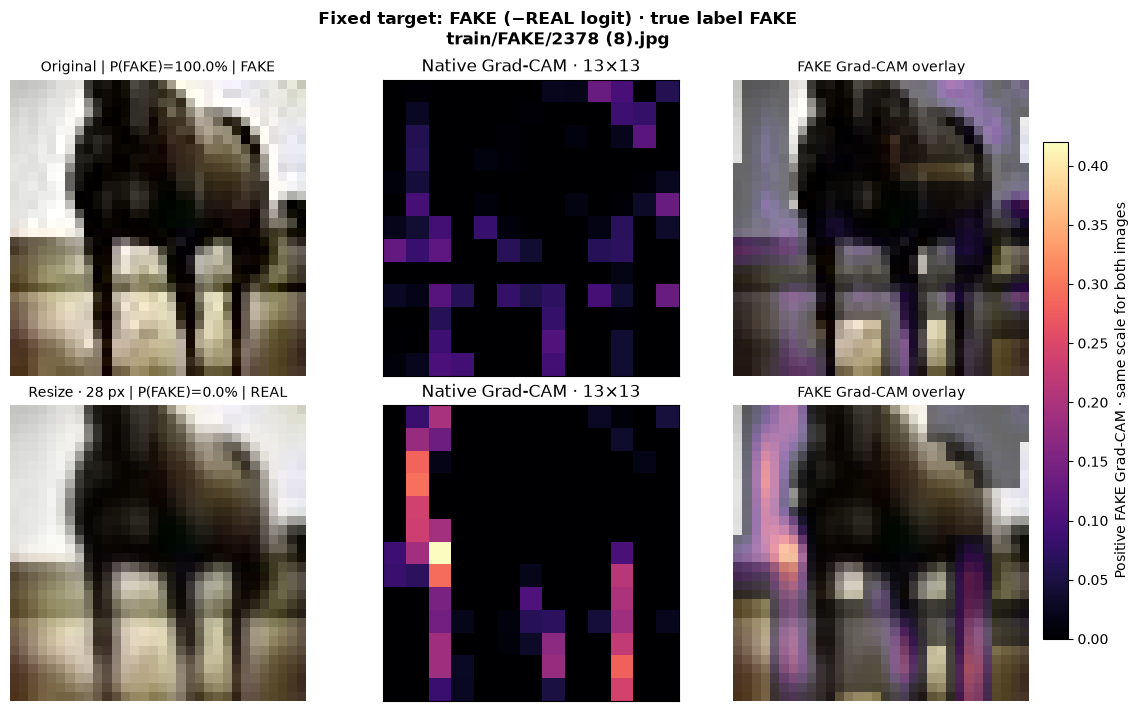

In [45]:
if explanation_default_pair is not None:
    finish_explanation_figure(
        gradcam_pair_figure(explanation_default_pair), "gradcam_fake_resize"
    )


For a second example, we will use the real image selected in the JPEG gallery and compare it with a quality-60 compressed version. This lets us inspect a change in the opposite direction: a real image receiving a higher FAKE probability. We will keep FAKE as the target in both rows, rather than switching the explanation to whichever class wins. The colour scale is shared within this pair, but is fitted separately from the resize example above. These are deliberately sensitive examples chosen from validation predictions, so they illustrate possible behaviour rather than its frequency across the dataset; Section 11 supplies the population-level results.

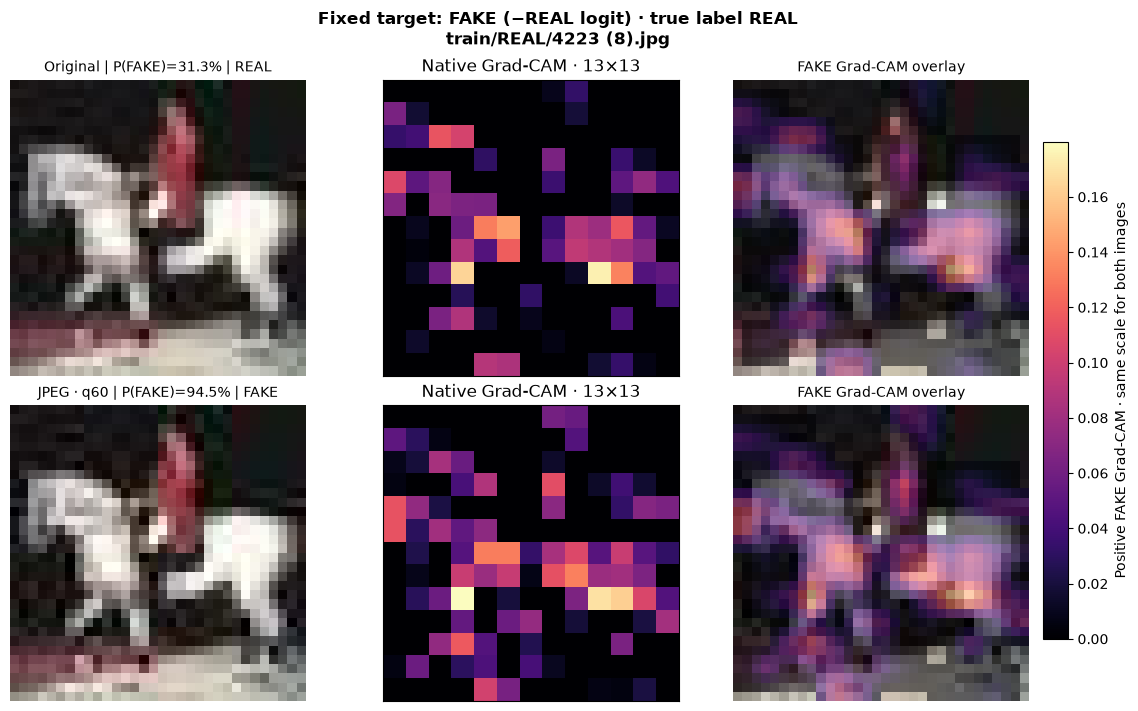

In [46]:
if explanation_comparison_pair is not None:
    finish_explanation_figure(
        gradcam_pair_figure(explanation_comparison_pair), "gradcam_real_jpeg"
    )


### 12.2 Neuron contributions: how do the weights produce the score?

Now we will return to the resize example and inspect the final decision directly. After the convolutions, this CNN has 64 hidden neurons. For a particular image, each neuron produces an activation $a_j$ and has a learned output weight $w_j$. Its contribution is **activation × weight**, and the output is exactly $z=b+\sum_{j=0}^{63}a_jw_j$. The weights and bias remain fixed when we edit an image; the activations change. A large weight alone therefore does not tell us how much a neuron contributes to this particular prediction.

The top heatmap shows all 64 contributions for the original and resized image on one shared scale: blue pushes the REAL logit up, while orange pushes it down toward FAKE. The bars underneath show the changes for the 12 neurons with the largest absolute changes, with the remaining 52 summed into a final bar. Together, all bars account for the complete change in logit; the unchanged bias cancels out. The small table then shows the actual activation and weight values for the six largest changes. Neuron numbers are identifiers, not labels such as “texture” or “background.”

In the default resize example, parts of the FAKE Grad-CAM map brighten even though the FAKE probability falls. This chart helps explain why we should not read heatmap brightness as confidence: the final decision combines all signed neuron contributions, including opposing evidence that a positive-only Grad-CAM map does not show. Probabilities in figure titles are rounded for readability; the logits reveal changes even when a displayed probability is close to 0% or 100%.

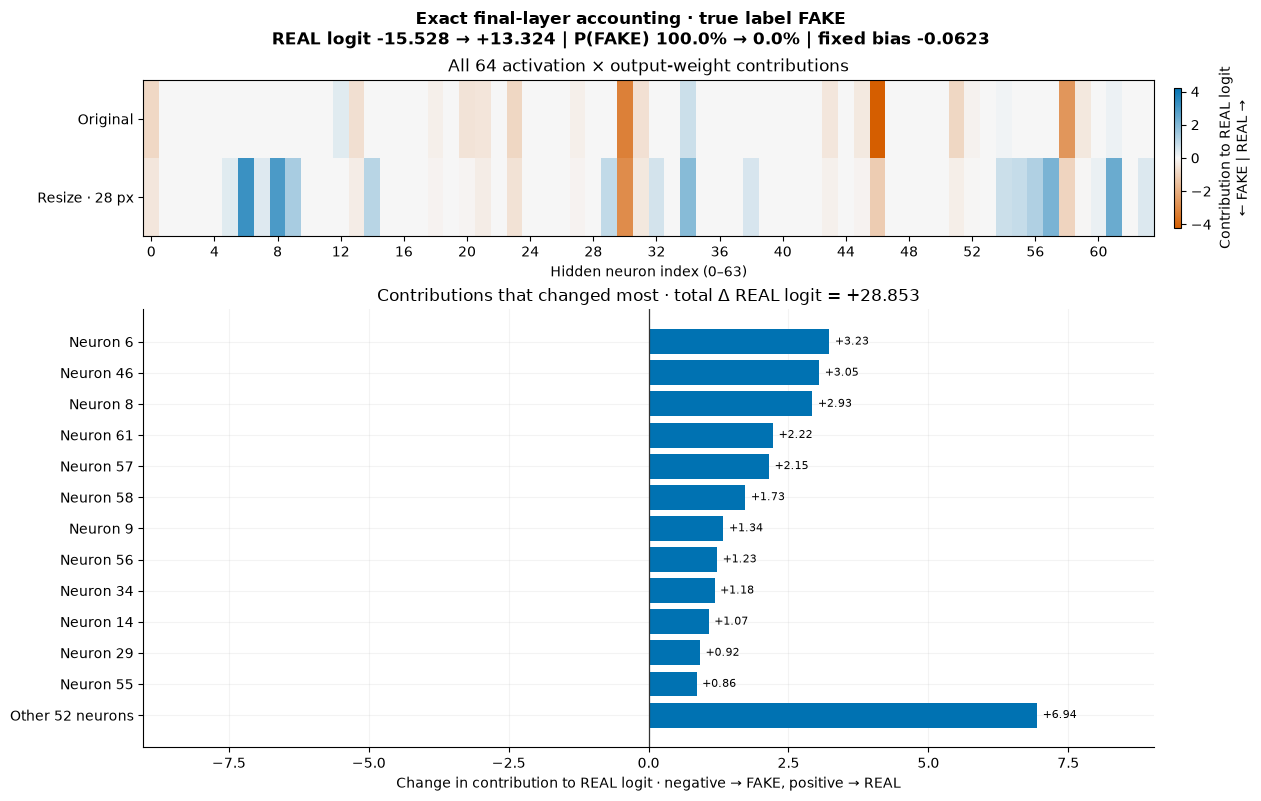

| Neuron | Fixed output weight | Activation: original | Activation: resized | Contribution: original | Contribution: resized | Change in REAL logit |
| --- | --- | --- | --- | --- | --- | --- |
| 6 | +0.7868 | 0.0000 | 4.1064 | +0.0000 | +3.2308 | +3.2308 |
| 46 | -1.1350 | 3.7370 | 1.0503 | -4.2414 | -1.1921 | +3.0493 |
| 8 | +0.9519 | 0.0000 | 3.0753 | +0.0000 | +2.9273 | +2.9273 |
| 61 | +0.6397 | 0.2685 | 3.7464 | +0.1718 | +2.3965 | +2.2247 |
| 57 | +0.5985 | 0.0000 | 3.5974 | +0.0000 | +2.1529 | +2.1529 |
| 58 | -0.7818 | 3.4224 | 1.2096 | -2.6757 | -0.9457 | +1.7300 |

| Image | Sum of 64 contributions | Fixed bias | Sum + bias | Model REAL logit |
| --- | --- | --- | --- | --- |
| Original | -15.46604 | -0.06231 | -15.52836 | -15.52836 |
| Resize · 28 px | +13.38669 | -0.06231 | +13.32437 | +13.32437 |

In [47]:
# Multiply each hidden activation by its output weight; include the bias to reconstruct the REAL logit.
if explanation_default_pair is not None:
    finish_explanation_figure(
        contribution_pair_figure(explanation_default_pair),
        "neuron_contributions_resize",
    )
    values = explanation_default_pair["values"]
    delta = (
        values["contribution_real"][1].astype(np.float64)
        - values["contribution_real"][0]
    )
    largest = np.argsort(-np.abs(delta), kind="stable")[:6]
    show_table(
        [
            "Neuron",
            "Fixed output weight",
            "Activation: original",
            "Activation: resized",
            "Contribution: original",
            "Contribution: resized",
            "Change in REAL logit",
        ],
        [
            (
                int(j),
                f"{values['weight64'][j]:+.4f}",
                f"{values['activation64'][0,j]:.4f}",
                f"{values['activation64'][1,j]:.4f}",
                f"{values['contribution_real'][0,j]:+.4f}",
                f"{values['contribution_real'][1,j]:+.4f}",
                f"{delta[j]:+.4f}",
            )
            for j in largest
        ],
    )
    sums = values["contribution_real"].sum(axis=1, dtype=np.float64)
    show_table(
        [
            "Image",
            "Sum of 64 contributions",
            "Fixed bias",
            "Sum + bias",
            "Model REAL logit",
        ],
        [
            (
                label,
                f"{sums[side]:+.5f}",
                f"{values['bias_real']:+.5f}",
                f"{sums[side]+values['bias_real']:+.5f}",
                f"{values['z_real'][side]:+.5f}",
            )
            for side, label in enumerate(["Original", "Resize · 28 px"])
        ],
    )


### 12.3 Occlusion: what happens when we cover a small region?

Here we will ask the model a direct “what if” question. We will slide a **4×4 patch in steps of two pixels** across the original and resized image, replacing all three colour channels in that patch. This gives 225 covered versions per image and reference colour. At each position we measure the FAKE score before covering minus the FAKE score afterwards. Orange means covering reduced the FAKE score, so that region supported FAKE relative to the chosen replacement; blue means covering increased the FAKE score. Pixels covered by several patches receive the average of those patch effects, so the map describes neighbourhoods rather than isolated pixel contributions.

The replacement itself can affect the result. We will therefore show two choices side by side: the original image's mean RGB colour and a neutral grey of 0.5 in each channel. Each reference is kept identical for the original and resized image, and all four maps share one symmetric colour scale. Agreement between the two columns gives more confidence that an effect is not specific to one fill colour, but it is still a response to an artificial intervention. Covering adds edges and changes local texture, especially at 32×32; it does not prove that a region contains a semantic object or that the model uses a particular shortcut.

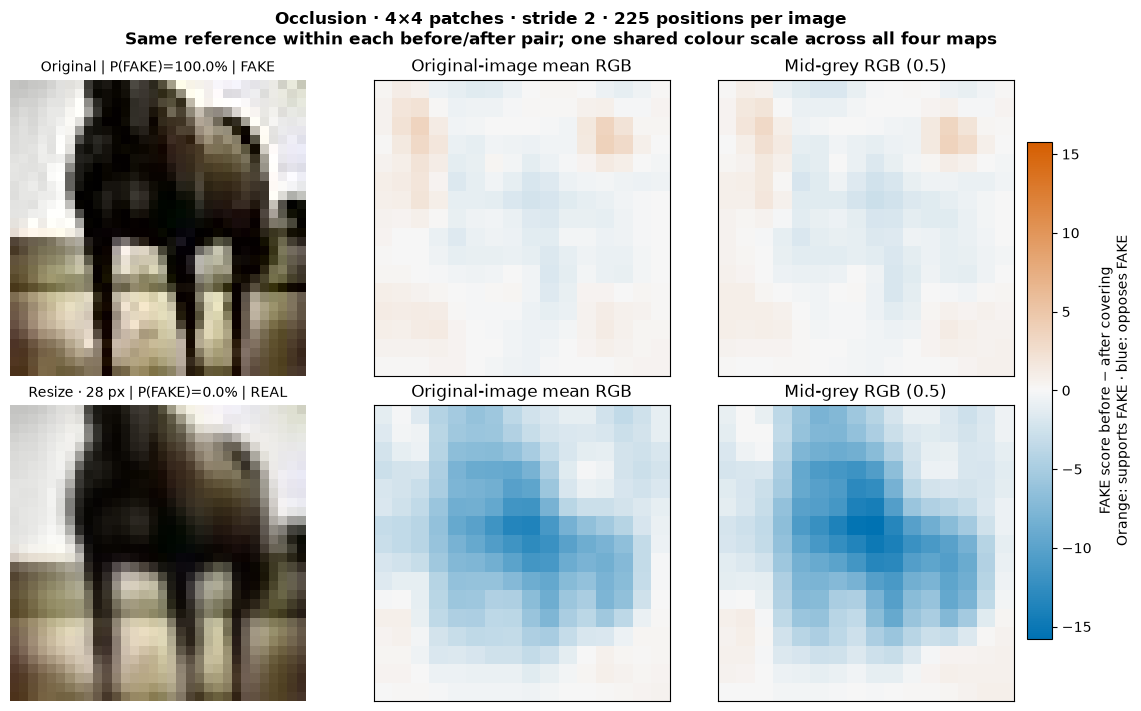

In [48]:
if explanation_default_pair is not None:
    finish_explanation_figure(
        occlusion_pair_figure(explanation_default_pair), "occlusion_fake_resize"
    )


### 12.4 Explore another image or modification

The controls below let us repeat all three views for any of the 27 included validation previews. Choose an image, a modification family, and a strength, then press **Explain pair**. Strength zero compares the original with itself, which is a useful check: its contribution changes should be zero. The patch control switches between 4×4 patches with stride two and 8×8 patches with stride four, so we can see whether a broad occlusion pattern persists at another scale. The tabs separate Grad-CAM, neuron contributions, and occlusion while keeping the same selected image pair.

This explorer computes explanations using the loaded model and caches results in memory. It needs a live notebook kernel; GitHub displays the static examples above. Changing a control marks the existing result as stale until we press the button again. The status line records the image and settings actually shown. These previews include sensitive cases and a seeded sample, so browsing them should generate hypotheses for a later controlled comparison rather than replace the full validation statistics.

In [49]:
if explanation_default_pair is not None:
    import html
    import ipywidgets as widgets

    explain_image_choice = widgets.Dropdown(
        options=[
            (
                f"{'FAKE' if behavior_labels[int(i)]==0 else 'REAL'} · {behavior_arrays['paths'][int(i)]}",
                int(i),
            )
            for i in behavior_arrays["preview_indices"]
        ],
        value=explanation_default_index,
        description="Image:",
        layout=widgets.Layout(width="95%"),
    )
    explain_family_choice = widgets.Dropdown(
        options=list(PROBE_FAMILIES), value="Resize", description="Change:"
    )
    explain_level_choice = widgets.IntSlider(
        value=1, min=0, max=4, description="Strength:", continuous_update=False
    )
    explain_patch_choice = widgets.Dropdown(
        options=[("4×4 · stride 2", 4), ("8×8 · stride 4", 8)],
        value=4,
        description="Patch:",
    )
    explain_button = widgets.Button(
        description="Explain pair", button_style="primary", icon="play"
    )
    explain_status = widgets.HTML()
    explain_details = widgets.HTML()
    explain_plot_widgets = [
        widgets.Image(format="png", layout=widgets.Layout(width="100%"))
        for _ in range(3)
    ]
    explain_tabs = widgets.Tab(children=explain_plot_widgets)
    for i, title in enumerate(["Grad-CAM", "Neuron contributions", "Occlusion"]):
        explain_tabs.set_title(i, title)
    explanation_explorer_state = {}

    def mark_explanation_stale(change=None):
        explain_status.value = "<b>Settings changed.</b> The plots still show the last computed pair. Press Explain pair to update."

    def update_explanation_explorer(button=None):
        explain_button.disabled = True
        explain_status.value = "Computing explanations…"
        try:
            index, family = int(explain_image_choice.value), explain_family_choice.value
            level, patch_size = int(explain_level_choice.value), int(
                explain_patch_choice.value
            )
            pair = get_explanation_pair(index, family, level, patch_size=patch_size)
            rendered = []
            for draw in [
                gradcam_pair_figure,
                contribution_pair_figure,
                occlusion_pair_figure,
            ]:
                fig = draw(pair)
                try:
                    stream = BytesIO()
                    fig.savefig(
                        stream,
                        format="png",
                        dpi=120,
                        bbox_inches="tight",
                        facecolor="white",
                    )
                    rendered.append(stream.getvalue())
                finally:
                    plt.close(fig)
            # Replace the plots together only after every view is ready.
            for target, png in zip(explain_plot_widgets, rendered):
                target.value = png
            p0, p1 = pair["values"]["p_fake"]
            explain_details.value = (
                f"<b>Showing: {pair['truth']}</b> · <code>{html.escape(pair['path'])}</code><br>"
                f"Original → {html.escape(pair['setting'])} · P(FAKE): {p0:.4%} → {p1:.4%}<br>"
                f"Occlusion: {patch_size}×{patch_size}, stride {pair['stride']} · "
                "Grad-CAM and occlusion target FAKE; neuron contributions target the REAL logit."
            )
            explanation_explorer_state.update(
                index=index,
                family=family,
                level=level,
                patch_size=patch_size,
                pair=pair,
            )
            explain_status.value = (
                "<b>Ready.</b> All three tabs show the pair recorded below."
            )
        except Exception as error:
            explain_status.value = f"<b>Could not update.</b> {html.escape(str(error))}. Any existing plots still show the previous result."
            raise
        finally:
            explain_button.disabled = False

    for control in [
        explain_image_choice,
        explain_family_choice,
        explain_level_choice,
        explain_patch_choice,
    ]:
        control.observe(mark_explanation_stale, names="value")
    explain_button.on_click(update_explanation_explorer)
    update_explanation_explorer()
    display(
        widgets.VBox(
            [
                explain_image_choice,
                widgets.HBox([explain_family_choice, explain_level_choice]),
                widgets.HBox([explain_patch_choice, explain_button]),
                explain_status,
                explain_details,
                explain_tabs,
            ]
        )
    )
    print(
        "Run this cell with a live kernel to explore. Static Grad-CAM, contribution and occlusion examples are saved above."
    )


Run this cell with a live kernel to explore. Static Grad-CAM, contribution and occlusion examples are saved above.


## 13. Inside the CNN: filters, responses and failure modes

We will now follow the earlier part of the decision process: **learned weights → feature maps → changes in the prediction**. The first convolution has 32 filters, each with a 3×3 slice for red, green and blue. Sliding these filters across the image gives 32 response maps. ReLU replaces negative responses with zero, and max pooling reduces their size. The second convolution then combines those 32 maps using another set of 32 filters. Each second-layer filter has 32 separate 3×3 slices, so its weights are not an RGB picture. The 64-neuron layer examined in Section 12 receives the features produced by this sequence.

The weights are fixed during this investigation. A filter is not assigned a name such as “edge detector” during training: we will examine its numbers, find image patches that activate it, and test a few controlled inputs before suggesting what it responds to. We will also switch off one output channel at a time, after its ReLU, to measure how that intervention changes predictions. This connects [feature visualization using dataset examples](https://distill.pub/2017/feature-visualization/) with [layer feature ablation](https://captum.ai/api/layer.html#layer-feature-ablation). A strong activation describes a response; the ablation test measures an effect on the output.

The aggregate investigation uses **2,000 validation images: 1,000 FAKE and 1,000 REAL, sampled without replacement with seed 20261103**. Every filter is tested on the same images in three conditions: original, resize 32→28→32, and JPEG quality 60. The last two were chosen because Section 11 showed different failure patterns under them. These sample results should not be confused with Section 11's full 10,000-image validation results. The saved probe and its selected example images are included below; `RUN_INTERNAL_PROBE = True` recomputes it when the prepared validation data are available.

The default filter in each layer is chosen by the largest drop in **clean sample accuracy** when its channel is zeroed. This gives us a useful starting point for inspection, but is an exploratory selection on this sample. It does not establish that a filter has a universal meaning, nor that removing it would be a good model change.

**Following and editing feature maps.** These helpers expose the CNN intermediates and continue the forward pass after a selected channel has been zeroed. This lets us test the effect of an intervention, rather than only looking at a response map.

In [50]:
INTERNAL_SEED = 20261103
INTERNAL_PER_CLASS = 1000
INTERNAL_LAYERS = [
    {
        "name": "Conv 1",
        "activation_index": 1,
        "weight_index": 0,
        "map_size": 30,
        "receptive_field": 3,
        "jump": 1,
    },
    {
        "name": "Conv 2",
        "activation_index": 4,
        "weight_index": 3,
        "map_size": 13,
        "receptive_field": 8,
        "jump": 2,
    },
]


@torch.inference_mode()
def internal_forward(net, images, selected_device):
    """Return post-ReLU maps and REAL logits using the actual baseline modules."""
    if not isinstance(net, BaselineCNN):
        raise TypeError("The filter investigation is specific to BaselineCNN.")
    net.eval()
    x = (
        torch.tensor(
            np.ascontiguousarray(images), device=selected_device, dtype=torch.float32
        )
        / 255
    )
    first = net.features[:2](x)
    second = net.features[3:5](net.features[2](first))
    logits = net.classifier(net.features[5](second)).squeeze(1)
    return [first, second], logits


@torch.inference_mode()
def internal_continue(net, activation, layer_index):
    """Continue the forward pass from a feature map that we may have edited."""
    remaining = net.features[INTERNAL_LAYERS[layer_index]["activation_index"] + 1 :]
    return net.classifier(remaining(activation)).squeeze(1)


@torch.inference_mode()
def internal_ablate_channels(net, activation, layer_index):
    """Zero one complete post-ReLU channel at a time; retain every other channel."""
    results = []
    for channel in range(activation.shape[1]):
        edited = activation.clone()
        edited[:, channel] = 0
        results.append(internal_continue(net, edited, layer_index).cpu().numpy())
    return np.stack(results)


**The fixed internal experiment.** We use a seeded, balanced validation sample for clean, resized and JPEG inputs. The resulting responses and interventions are saved so teammates can inspect them without recomputing the full experiment.

In [51]:
def run_internal_probe(
    net, data_dir, selected_device, expected_manifest, batch_size=128
):
    """Use a fixed balanced validation sample to compare channels across image conditions."""
    started = time.perf_counter()
    if file_sha256(data_dir / "manifest.csv") != expected_manifest:
        raise ValueError("The validation split does not match the selected checkpoint.")
    images, labels, rows = load_split(data_dir, "val")
    assert all(row["split"] == "val" and row["source_split"] == "train" for row in rows)
    rng = np.random.default_rng(INTERNAL_SEED)
    indices = np.sort(
        np.concatenate(
            [
                rng.choice(
                    np.flatnonzero(labels == label), INTERNAL_PER_CLASS, replace=False
                )
                for label in [0, 1]
            ]
        )
    ).astype(np.int32)
    n = len(indices)
    cohort = np.asarray(images[indices])
    conditions = [
        {"name": "Original", "family": "Original", "value": None},
        {"name": "Resize 32→28→32", "family": "Resize", "value": 28},
        {"name": "JPEG quality 60", "family": "JPEG", "value": 60},
    ]
    digest = behavior_model_digest(net)
    logits = np.empty((3, n), dtype=np.float32)
    ablated = np.empty((3, 2, 32, n), dtype=np.float32)
    mean_activation = np.empty((3, 2, 32, n), dtype=np.float32)
    zero_fraction = np.empty_like(mean_activation)
    peak_activation = np.empty((2, 32, n), dtype=np.float32)
    peak_position = np.empty((2, 32, n, 2), dtype=np.int16)
    for ci, condition in enumerate(conditions):
        modified = np.stack(
            [
                modify_behavior_image(
                    im, condition["family"], condition["value"], int(i)
                )
                for im, i in zip(cohort, indices)
            ]
        )
        for start in range(0, n, batch_size):
            stop = min(start + batch_size, n)
            maps, z = internal_forward(net, modified[start:stop], selected_device)
            logits[ci, start:stop] = z.cpu().numpy()
            for li, activation in enumerate(maps):
                ablated[ci, li, :, start:stop] = internal_ablate_channels(
                    net, activation, li
                )
                mean_activation[ci, li, :, start:stop] = (
                    activation.mean((2, 3)).cpu().numpy().T
                )
                zero_fraction[ci, li, :, start:stop] = (
                    (activation == 0).float().mean((2, 3)).cpu().numpy().T
                )
                if ci == 0:
                    flat = activation.flatten(2)
                    peak, where = flat.max(2)
                    peak_activation[li, :, start:stop] = peak.cpu().numpy().T
                    pos = where.cpu().numpy().T
                    peak_position[li, :, start:stop, 0] = pos // activation.shape[-1]
                    peak_position[li, :, start:stop, 1] = pos % activation.shape[-1]
            if start == 0 or stop == n or stop % 512 == 0:
                print(
                    f"{condition['name']}: {stop:,}/{n:,} images · both layers, all 32 channels",
                    flush=True,
                )
        accuracy = ((logits[ci] >= 0) == labels[indices]).mean()
        print(f"  Unablated accuracy: {accuracy:.2%}", flush=True)
    # Stable order makes tied activations reproducible; ties are not evidence of preference.
    top_slots = np.argsort(-peak_activation, axis=2, kind="stable")[:, :, :3].astype(
        np.int32
    )
    example_indices = np.unique(indices[top_slots]).astype(np.int32)
    arrays = {
        "indices": indices,
        "labels": labels[indices].astype(np.int8),
        "paths": np.asarray([rows[int(i)]["path"] for i in indices]),
        "logits_real": logits,
        "ablated_logits_real": ablated,
        "mean_activation": mean_activation.mean(-1),
        "zero_fraction": zero_fraction.mean(-1),
        "class_mean_activation": np.stack(
            [
                mean_activation[:, :, :, labels[indices] == label].mean(-1)
                for label in [0, 1]
            ],
            axis=-1,
        ),
        "top_peak_activation": np.take_along_axis(peak_activation, top_slots, axis=2),
        "top_position": peak_position[
            np.arange(2)[:, None, None], np.arange(32)[None, :, None], top_slots
        ],
        "top_slots": top_slots,
        "example_indices": example_indices,
        "example_images": np.asarray(images[example_indices]),
    }
    assert behavior_model_digest(net) == digest
    metadata = {
        "split": "val",
        "seed": INTERNAL_SEED,
        "per_class": INTERNAL_PER_CLASS,
        "n": n,
        "model_state_sha256": digest,
        "manifest_sha256": expected_manifest,
        "cohort_pixels_sha256": hashlib.sha256(cohort.tobytes()).hexdigest(),
        "conditions": conditions,
        "layers": INTERNAL_LAYERS,
        "intervention": "Set all spatial positions of one channel to zero after its ReLU, before pooling.",
        "top_examples": "Three highest spatial maxima per channel among original cohort images; stable tie order.",
        "elapsed_seconds": time.perf_counter() - started,
        "environment": {
            "torch": str(torch.__version__),
            "numpy": np.__version__,
            "pillow": importlib.metadata.version("pillow"),
            "device": str(selected_device),
        },
    }
    return arrays, metadata


def internal_metrics(arrays, bootstrap_draws=2000):
    labels = arrays["labels"]
    predicted = arrays["logits_real"] >= 0
    removed = arrays["ablated_logits_real"] >= 0
    correct = predicted == labels[None, :]
    removed_correct = removed == labels[None, None, None, :]
    harm = correct[:, None, None, :] & ~removed_correct
    repair = ~correct[:, None, None, :] & removed_correct
    drop = harm.mean(-1) - repair.mean(-1)
    rng = np.random.default_rng(INTERNAL_SEED + 1)
    interval = np.empty(drop.shape + (2,), dtype=np.float64)
    for ci in range(drop.shape[0]):
        for li in range(2):
            for channel in range(32):
                draws = np.zeros(bootstrap_draws)
                for label in [0, 1]:
                    select = labels == label
                    h = int(harm[ci, li, channel, select].sum())
                    r = int(repair[ci, li, channel, select].sum())
                    n = int(select.sum())
                    simulated = rng.multinomial(
                        n, [h / n, r / n, (n - h - r) / n], size=bootstrap_draws
                    )
                    draws += simulated[:, 0] - simulated[:, 1]
                interval[ci, li, channel] = np.quantile(
                    draws / len(labels), [0.025, 0.975]
                )
    return {
        "accuracy": correct.mean(-1),
        "ablated_accuracy": removed_correct.mean(-1),
        "drop": drop,
        "interval": interval,
        "harm": harm.sum(-1),
        "repair": repair.sum(-1),
        "fake_detected": (~predicted[:, labels == 0]).mean(-1),
        "real_false_alarm": (~predicted[:, labels == 1]).mean(-1),
        "ablated_fake_detected": (~removed[:, :, :, labels == 0]).mean(-1),
        "ablated_real_false_alarm": (~removed[:, :, :, labels == 1]).mean(-1),
    }


internal_pair_cache = {}


def get_internal_pair(index, family, level):
    """Collect the original and modified feature maps for the selected preview image."""
    index, level = int(index), int(level)
    condition = behavior_conditions_list[behavior_groups[family][level]]
    original = behavior_previews[index]
    changed = modify_behavior_image(
        original, condition["family"], condition["value"], index
    )
    images = np.stack([original, changed])
    key = (behavior_model_digest(model), hashlib.sha256(images.tobytes()).hexdigest())
    if key not in internal_pair_cache:
        maps, z = internal_forward(model, images, device)
        removed = np.stack(
            [internal_ablate_channels(model, m, li) for li, m in enumerate(maps)]
        )
        internal_pair_cache[key] = {
            "images": images,
            "maps": [m.cpu().numpy().copy() for m in maps],
            "logits_real": z.cpu().numpy().copy(),
            "ablated_logits_real": removed,
        }
    result = dict(internal_pair_cache[key])
    result.update(
        index=index,
        family=family,
        level=level,
        setting="Original" if level == 0 else f"{family} · {condition['label']}",
        path=str(behavior_arrays["paths"][index]),
        truth="FAKE" if behavior_labels[index] == 0 else "REAL",
    )
    return result


**Saved review data.** The trained weights and saved measurements are stored in notebook metadata, so there is no long encoded string to scroll through. This short loader checks and decodes the data when needed. Keep the complete `.ipynb` file when sharing it.

In [52]:
# Saved internal probe and top-activation examples; no dataset download or training is performed.
INTERNAL_REPORT = {
    "split": "val",
    "seed": 20261103,
    "per_class": 1000,
    "n": 2000,
    "model_state_sha256": "2b73e9f88f029ae7f9d33935864ceeefbd443b7d80a87e532301909a3c0a90a8",
    "manifest_sha256": "098210d89f9441376008d520f72aeef5f65a7aa6b5e0073ba4e875c979e1f205",
    "cohort_pixels_sha256": "b87e0ccb3e154156e90d62e6e4de1380f827fba93403726fe5fd964b75880694",
    "conditions": [
        {"name": "Original", "family": "Original", "value": None},
        {"name": "Resize 32→28→32", "family": "Resize", "value": 28},
        {"name": "JPEG quality 60", "family": "JPEG", "value": 60},
    ],
    "layers": [
        {
            "name": "Conv 1",
            "activation_index": 1,
            "weight_index": 0,
            "map_size": 30,
            "receptive_field": 3,
            "jump": 1,
        },
        {
            "name": "Conv 2",
            "activation_index": 4,
            "weight_index": 3,
            "map_size": 13,
            "receptive_field": 8,
            "jump": 2,
        },
    ],
    "intervention": "Set all spatial positions of one channel to zero after its ReLU, before pooling.",
    "top_examples": "Three highest spatial maxima per channel among original cohort images; stable tie order.",
    "elapsed_seconds": 3.5533366668969393,
    "environment": {
        "torch": "2.15.0",
        "numpy": "2.5.4",
        "pillow": "13.0.0",
        "device": "mps",
    },
}
INTERNAL_BUNDLE_SHA256 = (
    "65118d937f6be5afe9d24bb787f60369edfb32ad78b6007e3f22583b49c5e8c8"
)
INTERNAL_PAYLOAD = notebook_payload("baseline_internal_bundle")


def load_internal_bundle():
    """Restore the saved channel experiments and verify their shapes and sample balance."""
    raw = base64.b64decode(INTERNAL_PAYLOAD)
    if hashlib.sha256(raw).hexdigest() != INTERNAL_BUNDLE_SHA256:
        raise ValueError("The internal probe payload failed its integrity check.")
    with np.load(BytesIO(raw), allow_pickle=False) as packed:
        arrays = {key: packed[key] for key in packed.files}
    report = dict(INTERNAL_REPORT)
    n = report["n"]
    assert arrays["logits_real"].shape == (3, n)
    assert arrays["ablated_logits_real"].shape == (3, 2, 32, n)
    assert np.isfinite(arrays["ablated_logits_real"]).all()
    assert len(np.unique(arrays["indices"])) == n
    assert all(
        int((arrays["labels"] == label).sum()) == report["per_class"]
        for label in [0, 1]
    )
    assert arrays["top_slots"].shape == (2, 32, 3) and arrays["top_position"].shape == (
        2,
        32,
        3,
        2,
    )
    return arrays, report


In [53]:
# Load the fixed validation sample and saved channel interventions for the selected CNN.
internal_arrays, internal_report, internal_stats = None, None, None
internal_default_pair = None
internal_examples = {}
if isinstance(model, BaselineCNN) and behavior_arrays is not None:
    expected_manifest = checkpoint.get(
        "manifest_sha256", checkpoint.get("config", {}).get("manifest_sha256")
    )
    if RUN_INTERNAL_PROBE:
        internal_arrays, internal_report = run_internal_probe(
            model, DATA_DIR, device, expected_manifest
        )
    else:
        candidate_arrays, candidate_report = load_internal_bundle()
        if (
            behavior_model_digest(model) == candidate_report["model_state_sha256"]
            and expected_manifest == candidate_report["manifest_sha256"]
        ):
            internal_arrays, internal_report = candidate_arrays, candidate_report
        else:
            print(
                "The saved internal probe belongs to another model or split. Enable RUN_INTERNAL_PROBE after preparing a matching validation probe."
            )
    if internal_arrays is not None:
        internal_stats = internal_metrics(internal_arrays)
        internal_examples = {
            int(i): im
            for i, im in zip(
                internal_arrays["example_indices"], internal_arrays["example_images"]
            )
        }
        internal_default_channel = int(np.argmax(internal_stats["drop"][0, 0]))
        internal_second_channel = int(np.argmax(internal_stats["drop"][0, 1]))
        internal_default_pair = get_internal_pair(
            behavior_report["gallery_indices"]["Resize"]["FAKE"], "Resize", 1
        )
        print(
            f"Loaded internal investigation: {internal_report['n']:,} validation images, three conditions, both convolutional layers."
        )
        print(
            f"Clean-accuracy selection: Conv 1 filter {internal_default_channel}; Conv 2 filter {internal_second_channel}."
        )
        print(
            "Source paths retain the original train/ prefix; all selected images belong to our held-out validation split."
        )
        show_table(
            [
                "Condition",
                "Sample accuracy",
                "Fake images detected",
                "Real images incorrectly flagged",
            ],
            [
                (
                    condition["name"],
                    f"{internal_stats['accuracy'][ci]:.2%}",
                    f"{internal_stats['fake_detected'][ci]:.2%}",
                    f"{internal_stats['real_false_alarm'][ci]:.2%}",
                )
                for ci, condition in enumerate(internal_report["conditions"])
            ],
        )
else:
    print(
        "Load a BaselineCNN and its matching validation probe in Sections 9 and 11 before inspecting filters."
    )


Loaded internal investigation: 2,000 validation images, three conditions, both convolutional layers.
Clean-accuracy selection: Conv 1 filter 11; Conv 2 filter 25.
Source paths retain the original train/ prefix; all selected images belong to our held-out validation split.


| Condition | Sample accuracy | Fake images detected | Real images incorrectly flagged |
| --- | --- | --- | --- |
| Original | 94.80% | 94.90% | 5.30% |
| Resize 32→28→32 | 63.80% | 27.80% | 0.20% |
| JPEG quality 60 | 90.90% | 98.90% | 17.10% |

**Weights and convolution arithmetic.** These views turn the learned numbers into filter grids and a worked convolution example. They show how an input patch produces a channel response.

In [54]:
from matplotlib.patches import Rectangle


def internal_pfake(logits):
    return np.exp(-np.logaddexp(0, np.asarray(logits, dtype=np.float64)))


def internal_weight_figure(layer_index=0, channel=0):
    layer = INTERNAL_LAYERS[layer_index]
    weights = model.features[layer["weight_index"]].weight.detach().cpu().numpy()
    bias = model.features[layer["weight_index"]].bias.detach().cpu().numpy()
    panels = (
        [np.concatenate(list(w), axis=1) for w in weights]
        if layer_index == 0
        else list(weights[channel])
    )
    vmax = max(float(np.max(np.abs(panels))), 1e-9)
    fig, axes = plt.subplots(8, 4, figsize=(12, 10), layout="constrained")
    for i, ax in enumerate(axes.flat):
        heat = ax.imshow(
            panels[i], cmap="RdBu_r", vmin=-vmax, vmax=vmax, interpolation="nearest"
        )
        ax.set_yticks([])
        if layer_index == 0:
            ax.set_xticks([1, 4, 7], ["R", "G", "B"], fontsize=8)
            for x in [2.5, 5.5]:
                ax.axvline(x, color="#777777", lw=0.6)
            ax.set_title(f"Output filter {i} · bias {bias[i]:+.2f}", fontsize=8)
            if i == channel:
                for spine in ax.spines.values():
                    spine.set_color("#18985b")
                    spine.set_linewidth(2)
        else:
            ax.set_xticks([])
            ax.set_title(f"Input channel {i}", fontsize=8)
    colorbar = fig.colorbar(heat, ax=list(axes.flat), shrink=0.75, pad=0.01)
    colorbar.set_label("Learned weight · red positive, blue negative · shared scale")
    title = (
        f"Conv 1: all 32 learned filters · three 3×3 RGB slices per filter\nSelected filter {channel} is outlined in green"
        if layer_index == 0
        else f"Conv 2, output filter {channel}: 32 learned 3×3 input-channel slices · bias {bias[channel]:+.3f}"
    )
    fig.suptitle(title, fontsize=12, fontweight="bold")
    return fig


def internal_operation_values(pair, layer_index, channel, side=0):
    """Work through the multiply-and-add calculation for one convolution response."""
    layer = INTERNAL_LAYERS[layer_index]
    activation = pair["maps"][layer_index][side, channel]
    y, x = np.unravel_index(np.argmax(activation), activation.shape)
    with torch.inference_mode():
        image = (
            torch.tensor(
                pair["images"][side : side + 1], device=device, dtype=torch.float32
            )
            / 255
        )
        inputs = image if layer_index == 0 else model.features[:3](image)
        conv = model.features[layer["weight_index"]]
        expected_pre = float(conv(inputs)[0, channel, y, x].cpu())
        window = inputs[0, :, y : y + 3, x : x + 3].cpu().numpy().copy()
        weights = conv.weight[channel].detach().cpu().numpy().copy()
        bias = float(conv.bias[channel].cpu())
    product = window.astype(np.float64) * weights
    pre = float(product.sum() + bias)
    assert np.isclose(pre, expected_pre, atol=3e-5, rtol=1e-5)
    assert np.isclose(max(0, pre), activation[y, x], atol=3e-5, rtol=1e-5)
    return {
        "window": window,
        "weights": weights,
        "product": product,
        "bias": bias,
        "pre": pre,
        "activation": float(activation[y, x]),
        "position": (int(y), int(x)),
    }


def internal_operation_figure(pair, layer_index, channel):
    result = internal_operation_values(pair, layer_index, channel)
    n = result["window"].shape[0]
    selected = (
        np.arange(3)
        if n == 3
        else np.argsort(-np.abs(result["product"].sum((1, 2))), kind="stable")[:3]
    )
    remainder = float(result["product"].sum() - result["product"][selected].sum())
    fig, axes = plt.subplots(3, 3, figsize=(9.5, 8), layout="constrained")
    for row, ch in enumerate(selected):
        for col, key in enumerate(["window", "weights", "product"]):
            matrix = result[key][ch]
            limit = max(float(np.max(np.abs(result[key]))), 1e-9)
            ax = axes[row, col]
            ax.imshow(
                matrix,
                cmap="gray" if col == 0 else "RdBu_r",
                vmin=0 if col == 0 else -limit,
                vmax=limit,
                interpolation="nearest",
            )
            for y in range(3):
                for x in range(3):
                    light_text = (
                        (matrix[y, x] < 0.45 * limit)
                        if col == 0
                        else (abs(matrix[y, x]) > 0.6 * limit)
                    )
                    ax.text(
                        x,
                        y,
                        f"{matrix[y,x]:.3f}",
                        ha="center",
                        va="center",
                        fontsize=9,
                        color="white" if light_text else "#111111",
                    )
            name = "RGB"[ch] if n == 3 else f"Input channel {ch}"
            ax.set(
                title=f"{name} · {['input values','learned weights','input × weight'][col]}",
                xticks=[],
                yticks=[],
            )
    fig.suptitle(
        f"{INTERNAL_LAYERS[layer_index]['name']}, filter {channel} · ORIGINAL image · map position {result['position']}\n"
        f"Sum of all products {result['product'].sum():+.4f} + bias {result['bias']:+.4f} = {result['pre']:+.4f}\n"
        f"ReLU keeps max(0, value) = {result['activation']:.4f}"
        + (
            f"\nOnly three input channels shown; the other 29 product sums total {remainder:+.4f}."
            if n > 3
            else ""
        ),
        fontsize=11,
        fontweight="bold",
    )
    return fig


**Responses and activating examples.** These plots compare original and modified feature maps and show the image patches with the strongest saved responses for a selected channel.

In [55]:
def internal_activation_figure(pair, layer_index):
    maps = pair["maps"][layer_index]
    maximum = max(float(maps.max()), 1e-9)
    fig, axes = plt.subplots(8, 4, figsize=(13, 10), layout="constrained")
    cmap = plt.get_cmap("magma").copy()
    cmap.set_bad("white")
    for ch, ax in enumerate(axes.flat):
        joined = np.concatenate(
            [maps[0, ch], np.full((maps.shape[-1], 1), np.nan), maps[1, ch]], axis=1
        )
        heat = ax.imshow(
            joined, cmap=cmap, vmin=0, vmax=maximum, interpolation="nearest"
        )
        ax.set(
            title=f"Filter {ch} · mean {maps[0,ch].mean():.2f} → {maps[1,ch].mean():.2f}",
            xticks=[],
            yticks=[],
        )
        ax.title.set_fontsize(8)
    bar = fig.colorbar(heat, ax=list(axes.flat), shrink=0.8, pad=0.01)
    bar.set_label(
        "Post-ReLU activation · same scale across all filters and both images"
    )
    fig.suptitle(
        f"{INTERNAL_LAYERS[layer_index]['name']} · all 32 feature maps\n"
        f"Left of each divider: original · right: {pair['setting']} · true label {pair['truth']}\n{pair['path']}",
        fontsize=11,
        fontweight="bold",
    )
    return fig


def internal_detail_figure(pair, layer_index, channel):
    layer = INTERNAL_LAYERS[layer_index]
    maps = pair["maps"][layer_index][:, channel]
    vmax = max(float(maps.max()), 1e-9)
    fig, axes = plt.subplots(2, 3, figsize=(11, 7), layout="constrained")
    for side in range(2):
        y, x = np.unravel_index(np.argmax(maps[side]), maps[side].shape)
        py, px = int(y) * layer["jump"], int(x) * layer["jump"]
        r = layer["receptive_field"]
        p = float(internal_pfake(pair["logits_real"][side]))
        removed = float(
            internal_pfake(pair["ablated_logits_real"][layer_index, channel, side])
        )
        label = "Original" if side == 0 else pair["setting"]
        explanation_image(
            axes[side, 0],
            pair["images"][side],
            f"{label} · P(FAKE) {p:.2%}\nWith this channel zeroed: {removed:.2%}",
        )
        axes[side, 0].add_patch(
            Rectangle(
                (px - 0.5, py - 0.5), r, r, fill=False, edgecolor="#00ff88", lw=1.5
            )
        )
        heat = axes[side, 1].imshow(
            maps[side], cmap="magma", vmin=0, vmax=vmax, interpolation="nearest"
        )
        axes[side, 1].set(
            title=f"Filter {channel} · peak {maps[side,y,x]:.3f}", xticks=[], yticks=[]
        )
        axes[side, 1].add_patch(
            Rectangle((x - 0.5, y - 0.5), 1, 1, fill=False, edgecolor="#00ff88", lw=1.2)
        )
        crop = pair["images"][side, :, py : py + r, px : px + r]
        explanation_image(
            axes[side, 2],
            crop,
            f"Input region for the peak · {r}×{r}\nGreen box in the input image",
        )
        if not np.any(maps[side] > 0):
            axes[side, 1].text(
                0.5,
                0.5,
                "No positive response\nAll positions tied at zero",
                transform=axes[side, 1].transAxes,
                ha="center",
                va="center",
                color="white",
                fontsize=9,
            )
    bar = fig.colorbar(heat, ax=list(axes[:, 1]), shrink=0.7, pad=0.02)
    bar.set_label("Activation · shared before/after scale")
    fig.suptitle(
        f"{layer['name']}, filter {channel} · true label {pair['truth']}\n{pair['path']}\n"
        "A bright response is not itself evidence for REAL or FAKE; the zero-channel test measures an output effect.",
        fontsize=11,
        fontweight="bold",
    )
    return fig


internal_example_cache = {}


def internal_top_examples_figure(layer_index, channel):
    layer = INTERNAL_LAYERS[layer_index]
    slots = internal_arrays["top_slots"][layer_index, channel]
    ids = internal_arrays["indices"][slots]
    key = (behavior_model_digest(model), layer_index, channel, tuple(ids))
    if key not in internal_example_cache:
        images = np.stack([internal_examples[int(i)] for i in ids])
        maps, z = internal_forward(model, images, device)
        internal_example_cache[key] = (
            images,
            maps[layer_index][:, channel].cpu().numpy().copy(),
            z.cpu().numpy().copy(),
        )
    images, maps, z = internal_example_cache[key]
    peaks = internal_arrays["top_peak_activation"][layer_index, channel]
    np.testing.assert_allclose(maps.max((1, 2)), peaks, atol=3e-5, rtol=1e-5)
    fig, axes = plt.subplots(3, 3, figsize=(10.5, 9), layout="constrained")
    vmax = max(float(maps.max()), 1e-9)
    for row, (image, slot) in enumerate(zip(images, slots)):
        y, x = map(int, internal_arrays["top_position"][layer_index, channel, row])
        py, px = y * layer["jump"], x * layer["jump"]
        r = layer["receptive_field"]
        truth = "FAKE" if internal_arrays["labels"][slot] == 0 else "REAL"
        path = Path(str(internal_arrays["paths"][slot])).name
        explanation_image(
            axes[row, 0],
            image,
            f"Rank {row+1} · {truth} · {path}\nP(FAKE) {float(internal_pfake(z[row])):.2%}",
        )
        axes[row, 0].add_patch(
            Rectangle(
                (px - 0.5, py - 0.5), r, r, fill=False, edgecolor="#00ff88", lw=1.5
            )
        )
        heat = axes[row, 1].imshow(
            maps[row], cmap="magma", vmin=0, vmax=vmax, interpolation="nearest"
        )
        axes[row, 1].set(
            title=f"Peak activation {peaks[row]:.3f}", xticks=[], yticks=[]
        )
        axes[row, 1].add_patch(
            Rectangle((x - 0.5, y - 0.5), 1, 1, fill=False, edgecolor="#00ff88", lw=1.2)
        )
        explanation_image(
            axes[row, 2],
            image[:, py : py + r, px : px + r],
            f"{r}×{r} input region for this peak",
        )
    bar = fig.colorbar(heat, ax=list(axes[:, 1]), shrink=0.7, pad=0.02)
    bar.set_label("Post-ReLU activation · shared scale")
    suffix = (
        "\nAll peaks are zero: these tied examples do not show a preferred pattern."
        if not np.any(peaks > 0)
        else ""
    )
    fig.suptitle(
        f"{layer['name']}, filter {channel} · three strongest spatial responses\n"
        f"Original images from the {internal_report['n']:,}-image validation sample; selected by activation, not prediction accuracy.{suffix}",
        fontsize=11,
        fontweight="bold",
    )
    return fig


**Interventions and pattern checks.** The ablation view counts the effect of removing a channel. Simple synthetic patterns provide a limited check of a visual interpretation; they do not assign a semantic meaning to the filter.

In [56]:
def internal_ablation_figure():
    stats = internal_stats
    fig, axes = plt.subplots(
        2, 3, figsize=(14, 14), sharex=True, sharey="row", layout="constrained"
    )
    extent = max(float(np.abs(stats["interval"]).max() * 100) * 1.08, 1)
    for li in range(2):
        order = np.argsort(-stats["drop"][0, li], kind="stable")
        for ci in range(3):
            ax = axes[li, ci]
            values = 100 * stats["drop"][ci, li, order]
            bounds = 100 * stats["interval"][ci, li, order]
            for row, (value, bound) in enumerate(zip(values, bounds)):
                color = "#0072B2" if value >= 0 else "#D55E00"
                ax.plot(bound, [row, row], color=color, lw=1.2, alpha=0.65)
                ax.scatter(value, row, color=color, s=18, zorder=3)
            ax.axvline(0, color="#333333", lw=0.8)
            ax.set(
                yticks=np.arange(32),
                yticklabels=[str(j) for j in order],
                xlim=(-extent, extent),
                title=f"{INTERNAL_LAYERS[li]['name']} · {internal_report['conditions'][ci]['name']}\nUnablated accuracy {stats['accuracy'][ci]:.2%}",
                xlabel="Accuracy lost when channel is zeroed (pp)",
            )
            ax.tick_params(axis="y", labelsize=8)
            ax.tick_params(axis="x", labelbottom=True)
            if ci == 0:
                ax.set_ylabel("Filter index · ordered by effect on clean accuracy")
            behavior_axes_style(ax)
        axes[li, 0].invert_yaxis()
    fig.suptitle(
        f"Single-channel ablation on the same {internal_report['n']:,} validation images\n"
        "Positive / blue: removal hurts accuracy · negative / orange: removal improves accuracy\n"
        "Lines: 95% pointwise paired-bootstrap intervals; exploratory comparisons, no multiple-comparison adjustment.",
        fontsize=12,
        fontweight="bold",
    )
    return fig


def internal_channel_rows(layer_index, channel):
    rows = []
    for ci, condition in enumerate(internal_report["conditions"]):
        rows.append(
            (
                condition["name"],
                f"{internal_stats['accuracy'][ci]:.2%}",
                f"{internal_stats['ablated_accuracy'][ci,layer_index,channel]:.2%}",
                f"{100*internal_stats['drop'][ci,layer_index,channel]:+.2f}",
                int(internal_stats["harm"][ci, layer_index, channel]),
                int(internal_stats["repair"][ci, layer_index, channel]),
                f"{internal_stats['fake_detected'][ci]:.1%} → {internal_stats['ablated_fake_detected'][ci,layer_index,channel]:.1%}",
                f"{internal_stats['real_false_alarm'][ci]:.1%} → {internal_stats['ablated_real_false_alarm'][ci,layer_index,channel]:.1%}",
            )
        )
    return rows


def internal_test_patterns():
    """Probe simple synthetic patterns to help interpret a filter response."""
    y, x = np.indices((32, 32))
    patterns = [
        ("Black", np.zeros((32, 32))),
        ("Grey", np.full((32, 32), 128)),
        ("White", np.full((32, 32), 255)),
        ("Light → dark", 255 * (x < 16)),
        ("Dark → light", 255 * (x >= 16)),
        ("Light ↓ dark", 255 * (y < 16)),
        ("Dark ↓ light", 255 * (y >= 16)),
        ("Checkerboard", 255 * ((x + y) % 2)),
    ]
    images = np.stack(
        [np.repeat(np.asarray(p, dtype=np.uint8)[None], 3, axis=0) for _, p in patterns]
    )
    return [name for name, _ in patterns], images


def internal_pattern_figure(layer_index, channel):
    names, images = internal_test_patterns()
    maps, _ = internal_forward(model, images, device)
    responses = maps[layer_index][:, channel].cpu().numpy()
    vmax = max(float(responses.max()), 1e-9)
    fig, axes = plt.subplots(2, 8, figsize=(15, 4.8), layout="constrained")
    for i, name in enumerate(names):
        explanation_image(axes[0, i], images[i], name)
        for spine in axes[0, i].spines.values():
            spine.set_visible(True)
            spine.set_color("#999999")
            spine.set_linewidth(0.7)
        heat = axes[1, i].imshow(
            responses[i], cmap="magma", vmin=0, vmax=vmax, interpolation="nearest"
        )
        axes[1, i].set(
            title=f"Peak {responses[i].max():.3f}\nMean {responses[i].mean():.3f}",
            xticks=[],
            yticks=[],
        )
        axes[1, i].title.set_fontsize(9)
    bar = fig.colorbar(heat, ax=list(axes[1]), shrink=0.8, pad=0.01)
    bar.set_label("Activation")
    fig.suptitle(
        f"Controlled synthetic inputs · {INTERNAL_LAYERS[layer_index]['name']}, filter {channel}\n"
        "Identical RGB channels isolate brightness patterns. These are diagnostic inputs, not an accuracy benchmark.",
        fontsize=12,
        fontweight="bold",
    )
    return fig


INTERNAL_TABLE_HEADERS = [
    "Condition",
    "Accuracy: intact",
    "Accuracy: zeroed",
    "Accuracy lost (pp)",
    "New mistakes",
    "Mistakes repaired",
    "Fake detected: intact → zeroed",
    "Real false alarms: intact → zeroed",
]


def finish_internal_figure(fig, name):
    if SAVE_FIGURES:
        directory = ROOT / "results" / f"{RUN_NAME}_internals"
        directory.mkdir(parents=True, exist_ok=True)
        fig.savefig(
            directory / f"{name}.png", dpi=150, bbox_inches="tight", facecolor="white"
        )
    plt.show()
    plt.close(fig)


### 13.1 What filters did the first layer learn?

The grid below shows all 32 first-layer filters. Each small panel contains three adjacent 3×3 blocks: the weights applied to the red, green and blue input channels. Red indicates a positive weight and blue a negative weight, with one shared scale across the grid. Each title also gives that filter's bias. These colours describe the sign of a multiplication, not whether a weight supports REAL or FAKE. The selected filter is outlined in green so that we can follow it through the next views.

The patterns can suggest sensitivity to a colour or a spatial contrast, but a large weight is not enough to establish importance. The actual input values, cancellation between positive and negative terms, and the later layers all matter. The explorer also exposes the second-layer weights: there, each panel is a slice for one of the 32 incoming feature maps rather than an RGB channel.

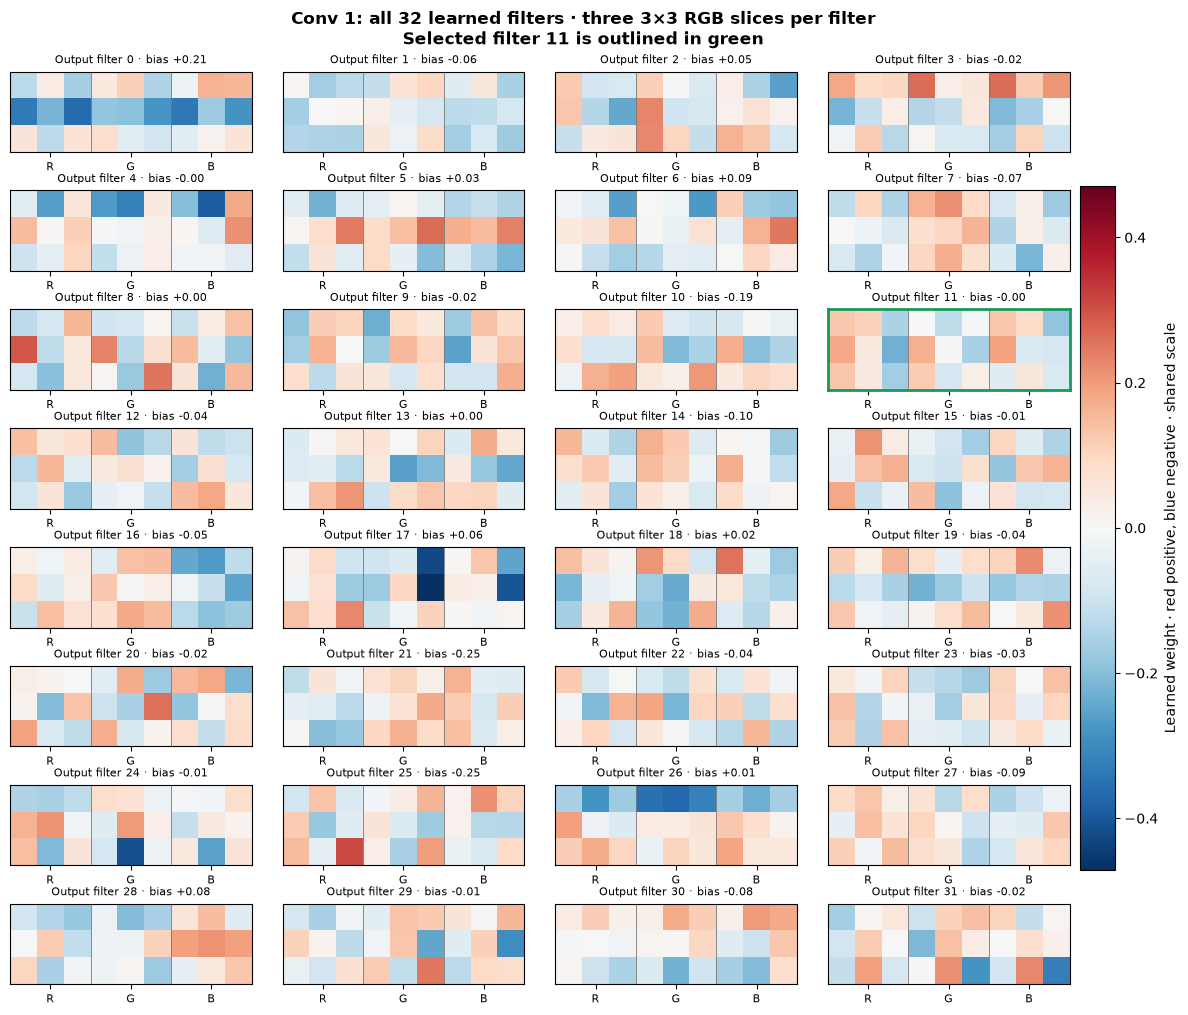

In [57]:
if internal_default_pair is not None:
    finish_internal_figure(
        internal_weight_figure(0, internal_default_channel), "conv1_weights"
    )


### 13.2 Follow the arithmetic of one convolution

To see what these numbers actually do, we will work through one response of the selected first-layer filter on the original resize example. We choose the position where this filter has its largest post-ReLU activation. The left column shows the 3×3 input values in each colour channel, scaled to 0–1; the middle column shows the learned weights at those positions; the right column shows their products. Summing all 27 products and adding the bias gives the convolution's response before ReLU. ReLU then keeps that value if it is positive, or returns zero otherwise. The calculation in the title is checked against the model's actual output at that position.

This is an exact calculation for one location, rather than an attribution approximation. It also explains why the weights and the activation are different things: the same weights slide across every location, but the input patch changes. In the explorer's second-layer calculation there are 32 incoming channels. It displays the three with the largest absolute product sums and explicitly includes the sum of the other 29 in the total.

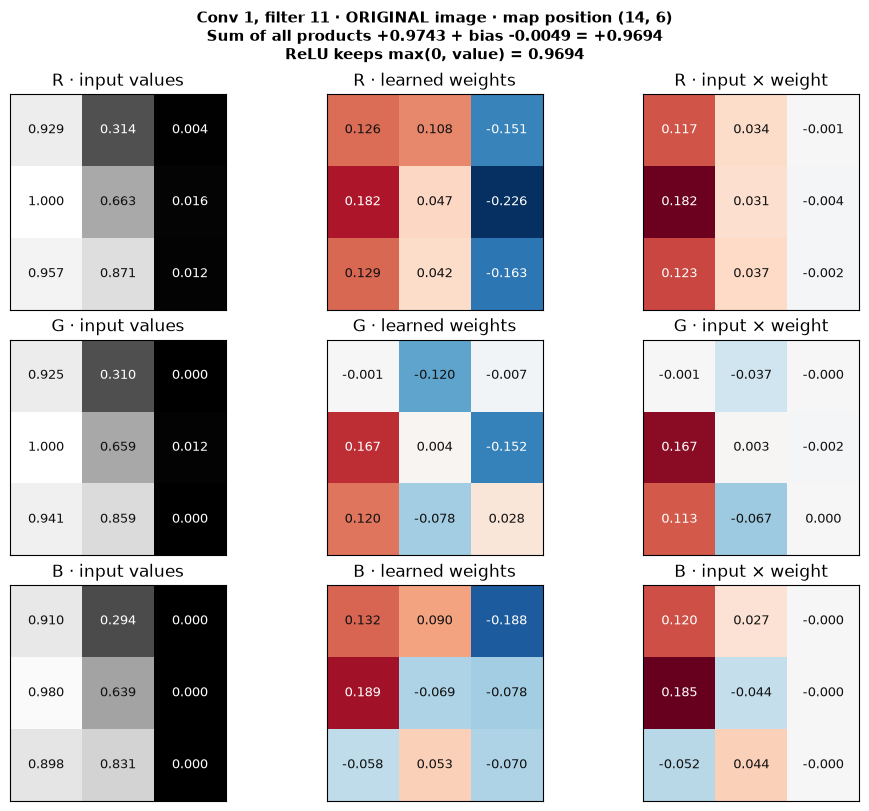

In [58]:
if internal_default_pair is not None:
    finish_internal_figure(
        internal_operation_figure(internal_default_pair, 0, internal_default_channel),
        "conv1_worked_calculation",
    )


### 13.3 How do the feature maps change after resizing?

We will now apply all 32 first-layer filters to the original image and its 32→28→32 version. Each panel shows one filter, with the original response on the left of the white divider and the modified response on the right. All panels share the same activation scale, so differences in brightness remain comparable across filters and versions. The numbers above each panel give its mean activation. These maps are taken after ReLU and before pooling, at their native 30×30 resolution; the second layer's corresponding maps are 13×13.

This lets us locate responses that disappear, weaken, or spread after an edit. It does not tell us by itself whether those changes help or hurt the classification: later layers combine the maps, and a bright response is not automatically evidence for either class. The next view connects a single channel to its input region and measures the change in prediction when that whole channel is zeroed.

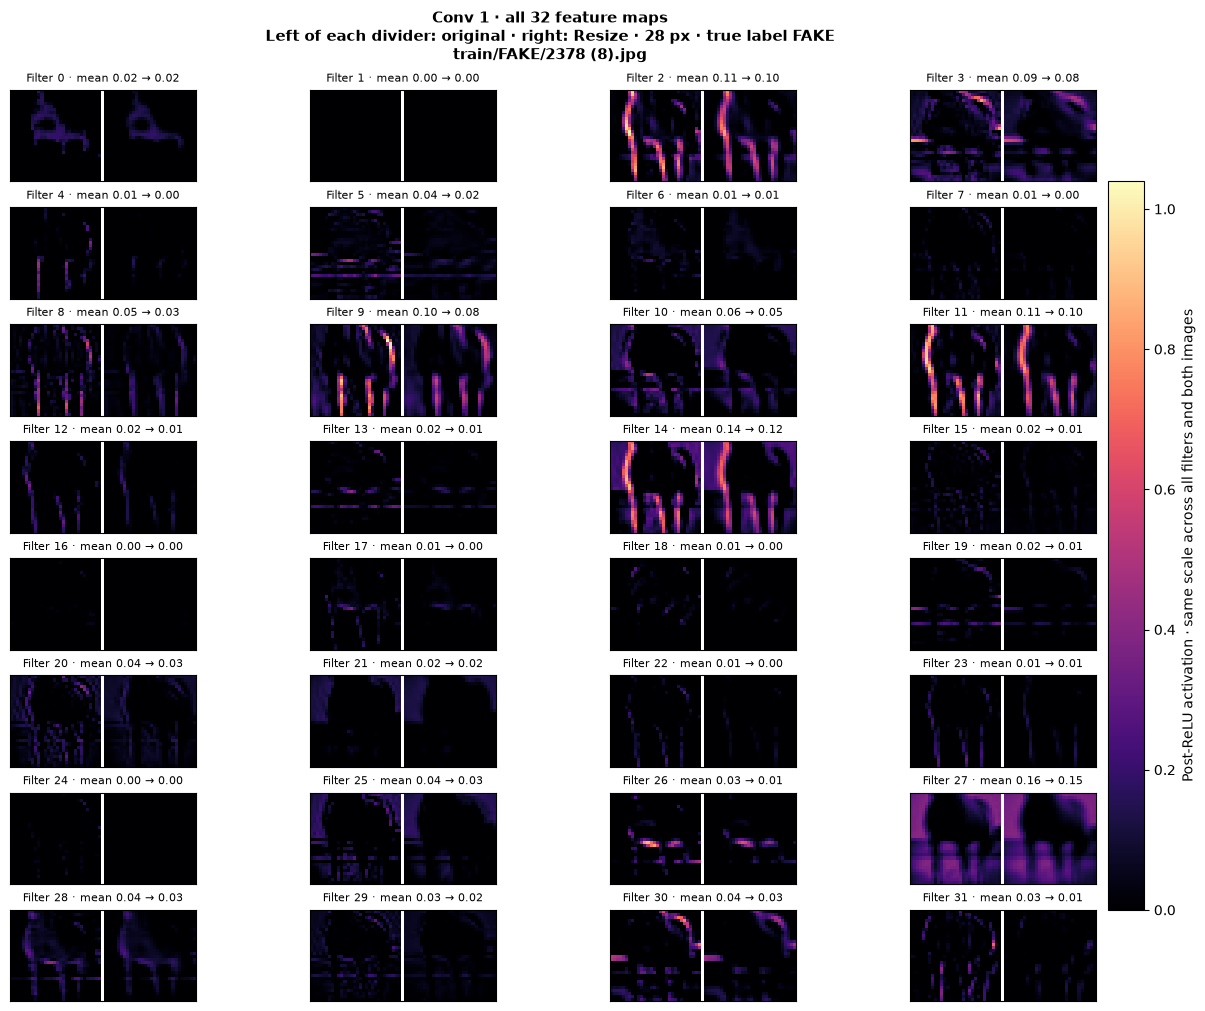

In [59]:
if internal_default_pair is not None:
    finish_internal_figure(
        internal_activation_figure(internal_default_pair, 0),
        "conv1_feature_maps_resize",
    )


Here we will follow only the selected filter through the same image pair. The middle column shows its response map, and the green square marks its strongest position. The green box on the original-sized input shows the input region that can affect that position; the right column enlarges that region. A first-layer response depends on a 3×3 input patch, while a second-layer response can depend on an 8×8 input region because the earlier convolution and pooling have already combined neighbouring pixels. These boxes are determined by the architecture, not by a saliency threshold.

The labels give the intact FAKE probability and the probability obtained after setting this entire channel to zero. That intervention affects all positions of the channel, not just the green box. A local peak and a channel's overall output effect therefore answer different questions. If a map is entirely zero, the view marks the absence of a positive response; a tied “peak” in such a map should not be read as a preferred region.

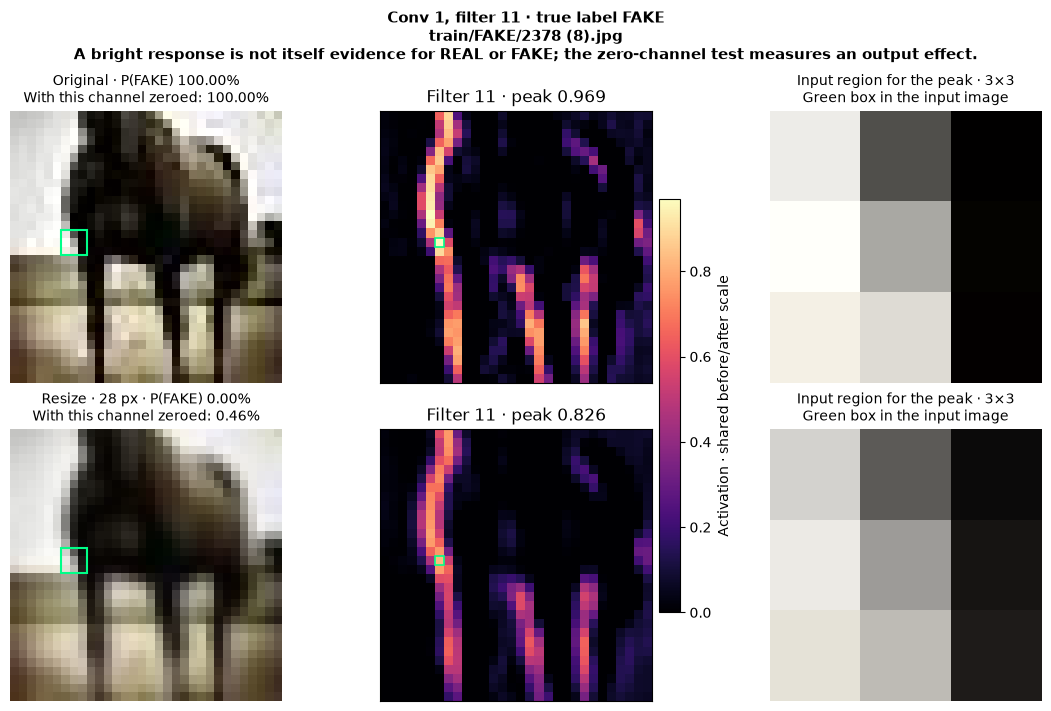

In [60]:
if internal_default_pair is not None:
    finish_internal_figure(
        internal_detail_figure(internal_default_pair, 0, internal_default_channel),
        "conv1_selected_filter_resize",
    )


### 13.4 What kinds of patches activate this filter?

The gallery below searches the original 2,000-image validation sample for the three images with the highest spatial activation of the selected filter. For each image, we will see the full image, its feature map, and the input patch corresponding to that peak. We select these examples by activation alone, without requiring a particular label or a correct prediction. This helps separate the pattern the filter responds to from the final classification that the rest of the network makes.

For the saved baseline's first-layer filter 11, the strongest patches show a bright region on the left transitioning to a dark region on the right. Together with its positive and negative weight pattern, this suggests sensitivity to that direction of contrast. The examples include both REAL and FAKE images, so it would be misleading to call it simply a “real-image detector.” Three examples also do not describe every pattern that can activate a filter; we will check the contrast interpretation using controlled inputs next.

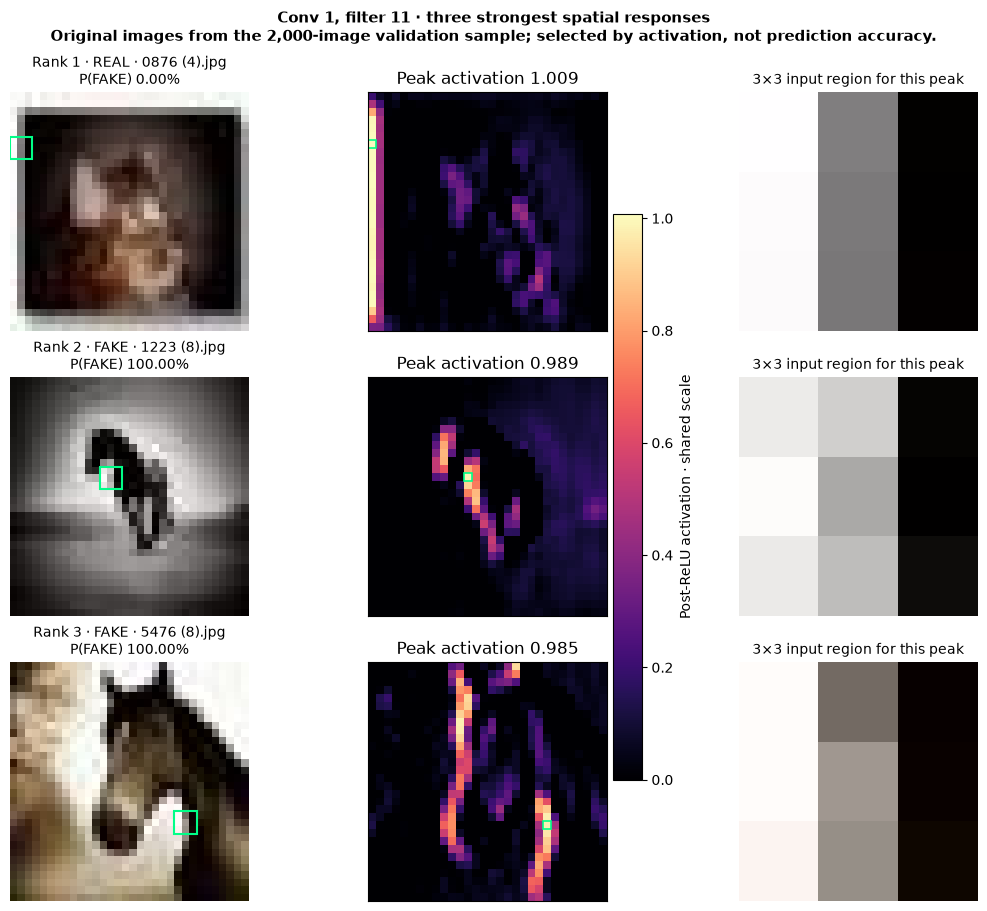

In [61]:
if internal_default_pair is not None:
    finish_internal_figure(
        internal_top_examples_figure(0, internal_default_channel),
        "conv1_strongest_examples",
    )


The next panel provides a small controlled check of that interpretation. We will feed the model flat black, grey and white images, vertical and horizontal brightness steps in both directions, and a one-pixel checkerboard. All three colour channels are identical, so these inputs isolate brightness patterns. The first row shows each input; the second row shows the selected filter's response, using one shared scale and reporting both the peak and mean activation. A large peak along a narrow edge can coexist with a small mean across the image.

These are synthetic diagnostic patterns, not CIFAKE examples or a new accuracy benchmark. They let us test whether a proposed direction of contrast really activates the filter, but cannot establish all of its colour preferences or its role in image classification. The explorer can apply this same fixed set of patterns to any channel in either convolutional layer.

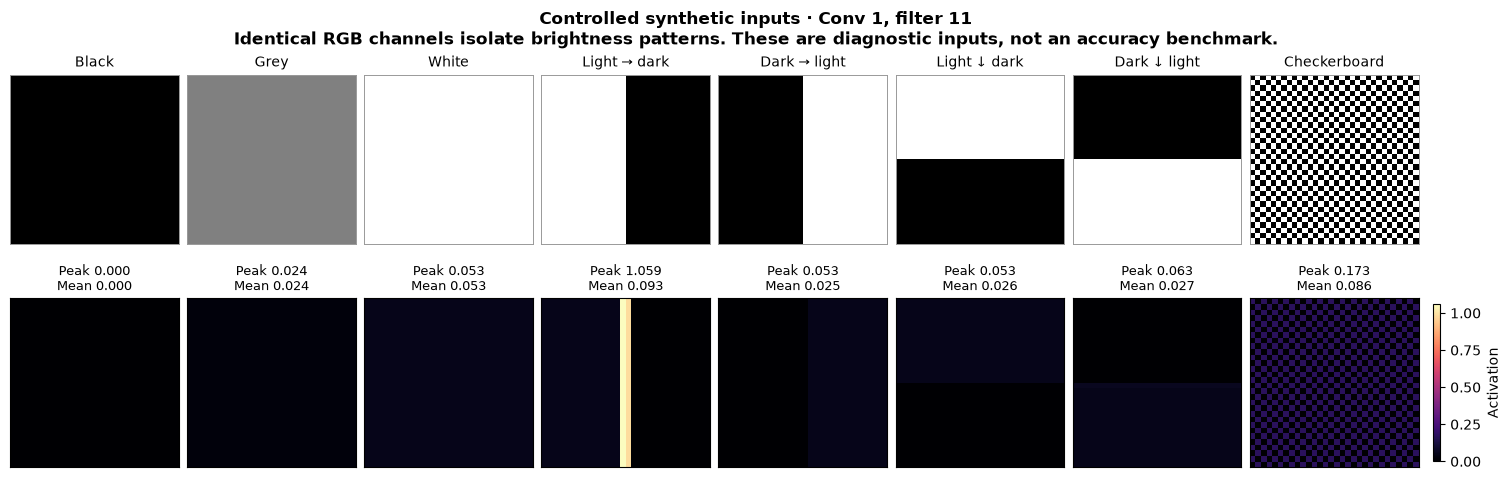

In [62]:
if internal_default_pair is not None:
    finish_internal_figure(
        internal_pattern_figure(0, internal_default_channel), "conv1_controlled_inputs"
    )


### 13.5 Which channels help, and under which conditions?

We will now compare performance with each channel switched off in turn. The channel is set to zero after its ReLU and before pooling, and the remaining network runs normally. Each point below is **intact accuracy minus accuracy after removal**, in percentage points, on the same balanced validation sample. Positive blue values mean removal causes a net loss of accuracy; negative orange values mean removal improves accuracy in that condition. Filters keep the same order across the three columns within each layer, making it easier to see when a channel's effect changes between clean, resized and JPEG images.

The thin lines are 95% pointwise paired-bootstrap intervals, resampling within each class while keeping intact and ablated predictions paired by image. They describe sampling variation for an individual comparison and are not adjusted for selecting among many filters. We will use them as exploratory context, not as a significance ranking. A zero effect on this sample does not prove that a channel is useless; other channels may compensate, and the response can depend on the image distribution. Zeroing a channel also creates an artificial internal state, so this is not the same experiment as retraining a model without that filter.

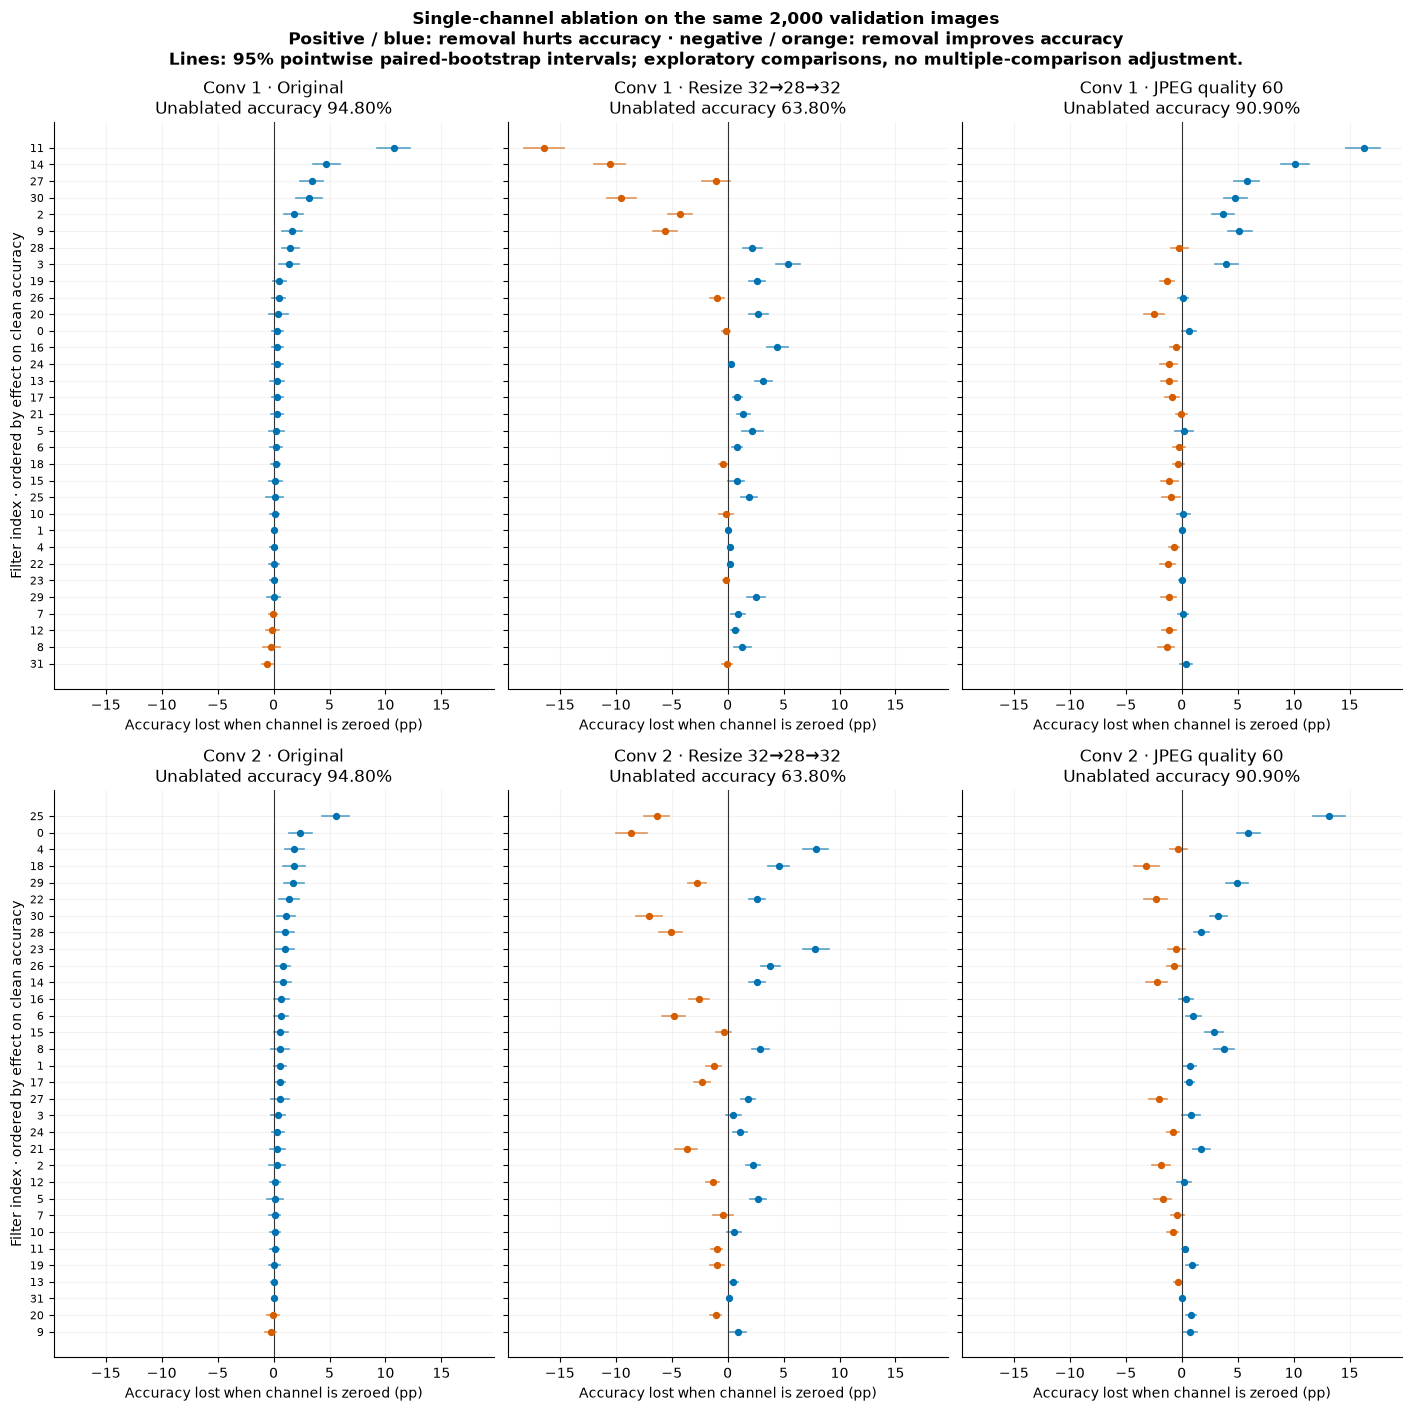

**Conv 1, filter 11: paired error changes**

| Condition | Accuracy: intact | Accuracy: zeroed | Accuracy lost (pp) | New mistakes | Mistakes repaired | Fake detected: intact → zeroed | Real false alarms: intact → zeroed |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Original | 94.80% | 84.05% | +10.75 | 265 | 50 | 94.9% → 99.9% | 5.3% → 31.8% |
| Resize 32→28→32 | 63.80% | 80.25% | -16.45 | 80 | 409 | 27.8% → 68.7% | 0.2% → 8.2% |
| JPEG quality 60 | 90.90% | 74.65% | +16.25 | 336 | 11 | 98.9% → 100.0% | 17.1% → 50.7% |

**Conv 2, filter 25: paired error changes**

| Condition | Accuracy: intact | Accuracy: zeroed | Accuracy lost (pp) | New mistakes | Mistakes repaired | Fake detected: intact → zeroed | Real false alarms: intact → zeroed |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Original | 94.80% | 89.25% | +5.55 | 144 | 33 | 94.9% → 98.2% | 5.3% → 19.7% |
| Resize 32→28→32 | 63.80% | 70.10% | -6.30 | 10 | 136 | 27.8% → 41.3% | 0.2% → 1.1% |
| JPEG quality 60 | 90.90% | 77.75% | +13.15 | 271 | 8 | 98.9% → 99.7% | 17.1% → 44.2% |

In [63]:
# Read the saved interventions to see which channel removals harm or repair predictions.
if internal_default_pair is not None:
    finish_internal_figure(internal_ablation_figure(), "channel_ablation_validation")
    for li, ch in [(0, internal_default_channel), (1, internal_second_channel)]:
        display(
            Markdown(
                f"**{INTERNAL_LAYERS[li]['name']}, filter {ch}: paired error changes**"
            )
        )
        show_table(INTERNAL_TABLE_HEADERS, internal_channel_rows(li, ch))


### 13.6 Inspect another filter or image

Choose a layer, filter index, preview image, modification and strength, then press **Inspect filter**. The tabs link the selected response maps to the weights, a worked convolution on the original preview, the strongest dataset examples, all feature maps, controlled test patterns, and aggregate ablation results. The first-layer weight tab shows all 32 filters with the selected one outlined; the second-layer weight tab shows the 32 input-channel slices of the selected output filter. Strength zero compares an image with itself.

The selected response and all-map tabs follow the image controls. The strongest examples and synthetic patterns follow the filter choice, while the ablation table always reports the three fixed conditions on the 2,000-image sample. Keeping that distinction visible prevents a preview of one image from being confused with a population result. The controls need a live kernel, but use the model and images already included in this notebook; GitHub can display the saved static figures above.

In [64]:
if internal_default_pair is not None:
    import html
    import ipywidgets as widgets

    internal_image_choice = widgets.Dropdown(
        options=[
            (
                f"{'FAKE' if behavior_labels[int(i)]==0 else 'REAL'} · {behavior_arrays['paths'][int(i)]}",
                int(i),
            )
            for i in behavior_arrays["preview_indices"]
        ],
        value=internal_default_pair["index"],
        description="Image:",
        layout=widgets.Layout(width="95%"),
    )
    internal_layer_choice = widgets.Dropdown(
        options=[("Conv 1", 0), ("Conv 2", 1)], value=0, description="Layer:"
    )
    internal_filter_choice = widgets.IntSlider(
        value=internal_default_channel,
        min=0,
        max=31,
        description="Filter:",
        continuous_update=False,
    )
    internal_family_choice = widgets.Dropdown(
        options=list(PROBE_FAMILIES), value="Resize", description="Change:"
    )
    internal_level_choice = widgets.IntSlider(
        value=1, min=0, max=4, description="Strength:", continuous_update=False
    )
    internal_button = widgets.Button(
        description="Inspect filter", icon="search", button_style="primary"
    )
    internal_status = widgets.HTML()
    internal_details = widgets.HTML()
    internal_table = widgets.HTML()
    internal_plot_widgets = [
        widgets.Image(format="png", layout=widgets.Layout(width="100%"))
        for _ in range(6)
    ]
    internal_tabs = widgets.Tab(children=[*internal_plot_widgets, internal_table])
    for i, title in enumerate(
        [
            "Responses",
            "Weights",
            "Calculation",
            "Examples",
            "All maps",
            "Test patterns",
            "Ablation",
        ]
    ):
        internal_tabs.set_title(i, title)
    internal_explorer_state = {}

    def mark_internal_stale(change=None):
        internal_status.value = "<b>Settings changed.</b> The results still show the previous selection. Press Inspect filter to update."

    def update_internal_explorer(button=None):
        internal_button.disabled = True
        internal_status.value = "Computing and rendering filter views…"
        try:
            if behavior_model_digest(model) != internal_report["model_state_sha256"]:
                raise ValueError(
                    "The model changed; reload a matching internal probe before using the explorer"
                )
            index = int(internal_image_choice.value)
            li, ch = int(internal_layer_choice.value), int(internal_filter_choice.value)
            family, level = internal_family_choice.value, int(
                internal_level_choice.value
            )
            pair = get_internal_pair(index, family, level)
            draws = [
                lambda: internal_detail_figure(pair, li, ch),
                lambda: internal_weight_figure(li, ch),
                lambda: internal_operation_figure(pair, li, ch),
                lambda: internal_top_examples_figure(li, ch),
                lambda: internal_activation_figure(pair, li),
                lambda: internal_pattern_figure(li, ch),
            ]
            pngs = []
            for draw in draws:
                fig = draw()
                try:
                    stream = BytesIO()
                    fig.savefig(
                        stream,
                        format="png",
                        dpi=110,
                        bbox_inches="tight",
                        facecolor="white",
                    )
                    pngs.append(stream.getvalue())
                finally:
                    plt.close(fig)
            for target, png in zip(internal_plot_widgets, pngs):
                target.value = png
            header = "".join(
                f'<th style="padding:6px">{html.escape(h)}</th>'
                for h in INTERNAL_TABLE_HEADERS
            )
            body = "".join(
                "<tr>"
                + "".join(
                    f'<td style="padding:6px">{html.escape(str(value))}</td>'
                    for value in row
                )
                + "</tr>"
                for row in internal_channel_rows(li, ch)
            )
            internal_table.value = (
                f'<p><b>{INTERNAL_LAYERS[li]["name"]}, filter {ch}</b> · '
                f'{internal_report["n"]:,} validation images. These three cohort conditions stay fixed when the preview controls change.</p>'
                f'<div style="overflow-x:auto"><table><tr>{header}</tr>{body}</table></div>'
                "<p>Positive accuracy lost means removal hurts; negative means removal helps. "
                "New mistakes and repaired mistakes are paired image counts, relative to the intact model under that condition.</p>"
            )
            p = internal_pfake(pair["logits_real"])
            removed = internal_pfake(pair["ablated_logits_real"][li, ch])
            means = pair["maps"][li][:, ch].mean((1, 2))
            internal_details.value = (
                f'<b>Showing {INTERNAL_LAYERS[li]["name"]}, filter {ch}</b> · true label {pair["truth"]} · '
                f'<code>{html.escape(pair["path"])}</code><br>'
                f'Original → {html.escape(pair["setting"])} · mean activation {means[0]:.3f} → {means[1]:.3f}<br>'
                f"Intact P(FAKE): {p[0]:.2%} → {p[1]:.2%}; with this channel zeroed: {removed[0]:.2%} → {removed[1]:.2%}.<br>"
                "The worked convolution uses the original preview. Strongest examples come from the fixed validation sample."
            )
            internal_explorer_state.update(
                index=index, layer=li, channel=ch, family=family, level=level, pair=pair
            )
            internal_status.value = (
                "<b>Ready.</b> All tabs match the filter and image recorded below."
            )
        except Exception as error:
            internal_status.value = f"<b>Could not update.</b> {html.escape(str(error))}. Existing results still show the previous selection."
            raise
        finally:
            internal_button.disabled = False

    for control in [
        internal_image_choice,
        internal_layer_choice,
        internal_filter_choice,
        internal_family_choice,
        internal_level_choice,
    ]:
        control.observe(mark_internal_stale, names="value")
    internal_button.on_click(update_internal_explorer)
    update_internal_explorer()
    display(
        widgets.VBox(
            [
                internal_image_choice,
                widgets.HBox([internal_layer_choice, internal_filter_choice]),
                widgets.HBox(
                    [internal_family_choice, internal_level_choice, internal_button]
                ),
                internal_status,
                internal_details,
                internal_tabs,
            ]
        )
    )
    print(
        "Run this cell with a live kernel to inspect filters. Static examples and all-channel ablation results are saved above."
    )


Run this cell with a live kernel to inspect filters. Static examples and all-channel ablation results are saved above.


### 13.7 What this investigation tells us

For the saved baseline, first-layer filter 11 has the largest clean-accuracy loss under single-channel removal. Its weights, strongest image patches and controlled-input responses support a description of sensitivity to a bright-to-dark transition from left to right. That is a local pattern description, not a semantic class label. Its activation on both real and fake examples shows why we need to follow the signal through the rest of the network.

The same channel has a distribution-dependent effect. Removing it changes clean sample accuracy from **94.80% to 84.05%**, but changes resized-image accuracy from **63.80% to 80.25%**. On resized images, fake detection rises from **27.8% to 68.7%**, while real-image false alarms also rise from **0.2% to 8.2%**. The higher accuracy is therefore a trade-off, not an across-the-board improvement. On JPEG images, removal lowers accuracy from **90.90% to 74.65%**. Second-layer filter 25 shows a similar sign change between clean and resized conditions. These numbers describe the saved model and this selected validation sample; the tables above recalculate for another compatible run.

The explanation is now more concrete than “resizing changes the score”: we can show learned spatial weights, verify their arithmetic, locate their responses, and measure how removing a channel changes errors. These results still do not establish a complete explanation of the clean-to-resized failure, or a justified pruning rule. In the illustrated fake-image pair, removing filter 11 alone does not reverse the resized image's incorrect REAL prediction. Several channels and the later layers act together, so the next hypothesis should be tested with controlled comparisons rather than naming a single filter as the cause of every failure.

**Calculation checks:** feature maps are compared with hooks on the model's normal forward pass; channel removal is compared with an independent forward-hook intervention; the displayed products plus bias reconstruct the convolution response; example rankings, input-region coordinates, zero-effect cases and the interactive controls are checked. The model weights and saved test evaluation remain fixed throughout this analysis.

## 14. Final test evaluation

The threshold is fixed at 0.5. Enable `EVALUATE_TEST` only after training and model selection are complete. If test results already exist, this notebook reads them instead of evaluating again. Test metrics are not used to select the checkpoint or change hyperparameters.

Both the official 20,000-image test set and its 19,962 unique images are reported. In `review` mode the following numbers come from the saved evaluation; they are not a newly computed test score.

The table below will put validation, the full official test set, and the test set with repeated copies counted only once side by side. Alongside accuracy, we'll compare loss, ROC-AUC, the proportion of fake images detected, and the proportion of real images incorrectly flagged as fake. The last two columns are especially useful for understanding what an error means for each class. Comparing the two test rows also lets us see how much repeated images affect the reported scores, without selecting a model or threshold based on those results.

In [65]:
# Display saved test results in review mode; only the explicit evaluation option can calculate them again.
test_report = read_result("test_metrics.json")
if EVALUATE_TEST and test_report is None:
    evaluate_model(RUN_DIR, data_dir=DATA_DIR, device=DEVICE)
    test_report = read_result("test_metrics.json")
elif EVALUATE_TEST:
    print("Existing test evaluation found; reusing it.")

if test_report:
    rows = []
    for label, metrics in (
        ("Validation", run_summary["validation"]),
        ("Official test", test_report["official_test"]),
        ("Unique test", test_report["unique_test"]),
    ):
        rows.append(
            [
                label,
                f"{metrics['n']:,}",
                f"{metrics['accuracy']:.2%}",
                f"{metrics['loss']:.4f}",
                f"{metrics['roc_auc_fake']:.4f}",
                f"{metrics['fake_detection_rate']:.2%}",
                f"{metrics['real_flagged_fake_rate']:.2%}",
            ]
        )
    show_table(
        [
            "Split",
            "Images",
            "Accuracy",
            "BCE",
            "ROC-AUC (fake)",
            "Fake detected",
            "Real flagged fake",
        ],
        rows,
    )
    print("Selected epoch:", test_report["selected_epoch"])
else:
    print(
        "No test evaluation for this run. Finish model selection before enabling EVALUATE_TEST."
    )


| Split | Images | Accuracy | BCE | ROC-AUC (fake) | Fake detected | Real flagged fake |
| --- | --- | --- | --- | --- | --- | --- |
| Validation | 10,000 | 94.54% | 0.1421 | 0.9882 | 94.60% | 5.52% |
| Official test | 20,000 | 94.29% | 0.1501 | 0.9871 | 94.18% | 5.60% |
| Unique test | 19,962 | 94.29% | 0.1500 | 0.9871 | 94.19% | 5.60% |

Selected epoch: 19


### Where the test errors occur

Overall accuracy combines two different kinds of mistake: accepting a fake image as real and flagging a real image as fake. We'll separate them with a confusion matrix using the saved official-test counts from the fixed 0.5 threshold. Rows show the true labels and columns show the predicted labels, so the diagonal cells contain correct classifications. The top-right cell counts fake images that passed as real, and the bottom-left cell counts real images incorrectly flagged as fake. The printed numbers are image counts, with darker shading representing larger counts. Reading the off-diagonal cells will help us see which type of error is more common in this balanced test set. This displays the existing evaluation; it does not run a new test or change the threshold.

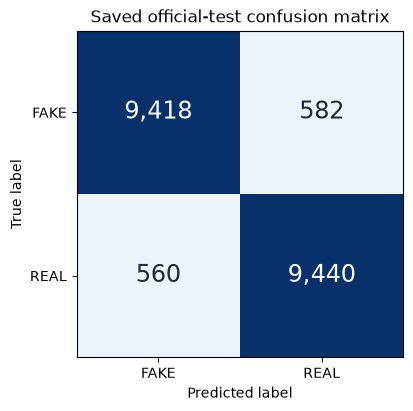

In [66]:
if test_report:
    cm = np.asarray(test_report["official_test"]["confusion_matrix"])
    fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max())
    for (row, col), value in np.ndenumerate(cm):
        ax.text(
            col,
            row,
            f"{value:,}",
            ha="center",
            va="center",
            fontsize=17,
            color="white" if value > cm.max() / 2 else "#1f2937",
        )
    ax.set(
        xticks=[0, 1],
        yticks=[0, 1],
        xticklabels=["FAKE", "REAL"],
        yticklabels=["FAKE", "REAL"],
        xlabel="Predicted label",
        ylabel="True label",
        title="Saved official-test confusion matrix",
    )
    plt.show()


## 15. Share one notebook; keep recovery checkpoints locally

**Only this `.ipynb` needs to be committed or downloaded for the completed baseline.** It includes the implementation, selected model weights, numerical results, and static figures. A teammate installs the packages, leaves `MODE = "review"`, and runs the notebook. Saved outputs can be read on GitHub without running anything. The modification, attribution and internal-filter explorers use the included validation images and need only a live kernel. The earlier full-data EDA explorer needs the prepared training data.

New training still saves `best.pt`, `last.pt`, and one full checkpoint per epoch under `runs/<RUN_NAME>/`. A notebook alone cannot resume an interrupted run without that run's optimizer and random-state checkpoints. If needed, enable `EXPORT_RUN` below to create a **local** archive of a completed, evaluated run for team storage. This does not publish or commit files. The bundled baseline remains fixed when you train another named run.

Dataset downloads, caches, optional exported figures, and checkpoints are runtime files, not additional required repository files. Commit only the notebook for this workflow.

In [67]:
if EXPORT_RUN:
    if not (RUN_DIR / "test_metrics.json").exists():
        raise RuntimeError(
            "A completed, evaluated local run is required for a full recovery archive."
        )
    archive_path = ROOT / "artifacts" / f"{RUN_NAME}.tar.gz"
    if archive_path.exists():
        print("Keeping the existing archive:", archive_path.relative_to(ROOT))
    else:
        archive_path.parent.mkdir(parents=True, exist_ok=True)
        temporary_archive = archive_path.with_suffix(".tmp")
        with tarfile.open(temporary_archive, "w:gz") as handle:
            handle.add(RUN_DIR, arcname=RUN_NAME)
        temporary_archive.replace(archive_path)
        archive_path.with_suffix(archive_path.suffix + ".sha256").write_text(
            f"{file_sha256(archive_path)}  {archive_path.name}\n"
        )
        print("Saved local recovery archive:", archive_path.relative_to(ROOT))
else:
    print(
        "Single-file sharing: copy or commit this notebook. The baseline weights and results are already bundled."
    )
print("Full recovery checkpoints are generated locally only when training is enabled.")


Single-file sharing: copy or commit this notebook. The baseline weights and results are already bundled.
Full recovery checkpoints are generated locally only when training is enabled.


## 16. What we learned from this baseline

The small CNN gives us a useful reference for the model-behaviour project. It was trained from scratch on native 32×32 images, without random augmentation, and completed **24 epochs in about 2 minutes 21 seconds** on this machine. Validation loss selected **epoch 19**, rather than the final epoch. The selected model reached **94.54% validation accuracy** and **94.29% accuracy on the 20,000-image official test set**. These clean results show that there is enough information at this resolution for this network to separate the two CIFAKE classes. They do not, by themselves, tell us which visual cues the model relies on or whether those cues survive changes to an image.

The modification views answer part of that question. We kept each validation image and its label fixed, changed one property at a time, and followed the probability and predicted class. JPEG compression and moderate noise reduced accuracy, while even a small downsample-and-upsample operation caused a much larger change. Resizing from 32 to 28 pixels and back reduced the CNN's validation accuracy to **62.13%**; blur with radius 0.6 reduced it to **66.79%**. The score distributions and individual examples show why an average accuracy is not enough: we also need to see which class loses detections and whether many images move in the same direction. These are observations about the tested transformations, not proof that any particular image artifact is the cause.

The completed ResNet18 experiment gives us a second reference:

| Condition | Plain CNN accuracy | Fine-tuned ResNet18 accuracy |
| --- | ---: | ---: |
| Clean official test, 20,000 images | 94.290% | 97.735% |
| Original validation images | 94.54% | 97.92% |
| JPEG quality 60 | 90.94% | 96.24% |
| Gaussian blur, radius 0.6 | 66.79% | 63.69% |
| Resize 32 → 28 → 32 | 62.13% | 55.77% |
| Gaussian noise, standard deviation 0.05 | 89.83% | 90.68% |

Except for the explicitly marked official test row, these measurements use the same **10,000 validation images**, their original labels and the fixed 0.5 decision threshold. The channel-removal experiments below use a separate **2,000-image subset of that validation split**, so their percentages should be compared within that cohort.

ResNet18 is more accurate on clean images and at the listed JPEG and noise settings, but it performs worse than the small CNN at the listed blur and resize settings. A larger model with ImageNet pretraining therefore did not remove this sensitivity. This comparison changes several things together—architecture, initialization, input resizing and normalization—so it cannot isolate the effect of architecture alone. The table also shows selected settings from the full sweep; the complete curves are needed to see how behaviour changes with strength.

The explanation views connect those changes to the computation. Grad-CAM highlights coarse regions supporting the FAKE score; occlusion asks how the score changes when a small patch is covered; and the final-layer chart reconstructs the REAL logit from **64 activation-times-weight contributions plus the bias**. Looking at learned filters, their response maps and their most activating patches helps us describe local patterns. These views complement one another: a bright heatmap region or a large weight alone is not a complete explanation of a decision.

The strongest concrete internal finding concerns **first-layer channel 11**. On the fixed 2,000-image validation cohort, zeroing it reduced clean accuracy from **94.80% to 84.05%**, but increased resized-image accuracy from **63.80% to 80.25%**. That improvement involved a trade-off: fake detection rose from **27.8% to 68.7%**, while real images incorrectly flagged as fake rose from **0.2% to 8.2%**. JPEG-quality-60 accuracy also fell from **90.90% to 74.65%**. The filter weights, activation examples and synthetic pattern checks are consistent with sensitivity to a local bright-to-dark transition. Removing it does not reverse every illustrated error, so it is not a single explanation for all resizing failures. The intervention shows a measurable dependence on one channel under specific conditions; it does not justify deleting that channel as a general fix.

For our course, **32×32 is sufficient to study these controlled changes in model behaviour**. Phase 1 can show how scores and errors move under modifications; phase 2 can trace feature responses and test the consequences of channel removal. The small images limit fine spatial interpretation and claims about semantic object parts. The useful conclusion is that the baseline learns a successful clean-data decision rule with measurable sensitivities, and that we can visualize and investigate those sensitivities. A future augmentation experiment should use a separately trained model and the same validation protocol; the current results do not establish that augmentation would solve the problem, and the test set should remain outside that design process.

The saved analysis includes checks of data integrity, score reconstruction and explanation calculations. Those checks support the correctness of the implementation; they do not make an attribution method a complete explanation or turn this single seeded experiment into a general robustness claim.